In [32]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

print("Random seed:", SEED)

TensorFlow version: 2.17.0
Random seed: 42


In [33]:
import pandas as pd

df = pd.read_csv("forex_usd_inr_2007_to_present.csv")

df.columns = ["Date", "Close", "High", "Low", "Open", "Volume"]

print(df.columns)

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [34]:
# ============================================================
# CONFIGURATION
# ============================================================

DATA_PATH = "forex_usd_inr_2007_to_present.csv"

TARGETS = ["High", "Low"]

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "FAAST_LSTM_Results"

GRAPH_DIR = os.path.join(OUTPUT_DIR, "Graphs")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Configuration loaded.")
print("Lookback:", LOOKBACK)
print("Train:", TRAIN_RATIO)
print("Validation:", VAL_RATIO)
print("Test:", TEST_RATIO)

Configuration loaded.
Lookback: 25
Train: 0.7
Validation: 0.15
Test: 0.15


In [35]:
# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------
df = df.rename(columns={df.columns[0]: "Date"})

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Timestamp",
    "timestamp"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "No date column found. Available columns:\n"
        + str(df.columns.tolist())
    )

print("\nDate column:", date_column)

# ------------------------------------------------------------
# Convert date
# ------------------------------------------------------------

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = df.dropna(subset=[date_column])

# ------------------------------------------------------------
# Sort chronologically
# ------------------------------------------------------------

df = df.sort_values(date_column)

# Remove duplicate dates
df = df.drop_duplicates(
    subset=[date_column],
    keep="first"
)

df = df.reset_index(drop=True)

# ------------------------------------------------------------
# Check targets
# ------------------------------------------------------------

for target in TARGETS:

    if target not in df.columns:
        raise ValueError(
            f"Target '{target}' not found."
        )

    df[target] = pd.to_numeric(
        df[target],
        errors="coerce"
    )

df = df.dropna(subset=TARGETS)

print("\nCleaned shape:", df.shape)

print(
    "\nDate range:",
    df[date_column].min(),
    "to",
    df[date_column].max()
)

print("\nTarget summary:")
print(df[TARGETS].describe())

Original shape: (4889, 6)

Columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Date column: Date

Cleaned shape: (1929, 6)

Date range: 2007-01-01 00:00:00 to 2025-12-09 00:00:00

Target summary:
              High          Low
count  1929.000000  1929.000000
mean     63.931460    63.504019
std      14.025289    14.003916
min      39.259998    38.979000
25%      49.938000    49.423000
50%      65.192497    64.839996
75%      74.528702    74.050598
max      88.921501    88.719101


In [49]:
# ============================================================
# MARKET REGIMES
# ============================================================

def assign_regime(year):

    if year <= 2011:
        return "DF1"

    elif year <= 2019:
        return "DF2"

    elif year <= 2022:
        return "DF3"

    else:
        return "DF4"


df["Regime"] = df[date_column].dt.year.apply(assign_regime)

print("\nRegime distribution:")
print(df["Regime"].value_counts().sort_index())

print("\nRegime date ranges:")

for regime in ["DF1", "DF2", "DF3", "DF4"]:

    temp = df[df["Regime"] == regime]

    if len(temp) > 0:

        print(
            regime,
            ":",
            temp[date_column].min().date(),
            "→",
            temp[date_column].max().date(),
            "| n =",
            len(temp)
        )


Regime distribution:
Regime
DF1    504
DF2    821
DF3    308
DF4    296
Name: count, dtype: int64

Regime date ranges:
DF1 : 2007-01-01 → 2011-12-12 | n = 504
DF2 : 2012-01-02 → 2019-12-12 | n = 821
DF3 : 2020-01-01 → 2022-12-12 | n = 308
DF4 : 2023-01-02 → 2025-12-09 | n = 296


In [37]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

def chronological_split(data):

    n = len(data)

    train_end = int(n * TRAIN_RATIO)

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    train = data.iloc[:train_end].copy()

    val = data.iloc[
        train_end:val_end
    ].copy()

    test = data.iloc[
        val_end:
    ].copy()

    return train, val, test


train_df, val_df, test_df = chronological_split(df)

print("TRAIN")
print(
    len(train_df),
    train_df[date_column].min(),
    "→",
    train_df[date_column].max()
)

print("\nVALIDATION")
print(
    len(val_df),
    val_df[date_column].min(),
    "→",
    val_df[date_column].max()
)

print("\nTEST")
print(
    len(test_df),
    test_df[date_column].min(),
    "→",
    test_df[date_column].max()
)

TRAIN
1350 2007-01-01 00:00:00 → 2020-03-09 00:00:00

VALIDATION
289 2020-03-11 00:00:00 → 2023-01-09 00:00:00

TEST
290 2023-01-11 00:00:00 → 2025-12-09 00:00:00


In [38]:
# ============================================================
# SEQUENCE CREATION
# ============================================================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close"
]

for col in FEATURE_COLUMNS:

    if col not in df.columns:
        raise ValueError(
            f"Required feature '{col}' not found."
        )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURE_COLUMNS
).reset_index(drop=True)

# Recreate split after final cleaning
train_df, val_df, test_df = chronological_split(df)


def create_sequences(X, y, lookback):

    X_seq = []
    y_seq = []

    for i in range(lookback, len(X)):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return np.array(X_seq), np.array(y_seq)


print("Sequence function ready.")

Sequence function ready.


In [39]:
# ============================================================
# LSTM MODEL
# ============================================================

def build_lstm(
    input_shape,
    output_dim=1
):

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(16, activation="relu"),

        Dense(output_dim)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model

In [40]:
# ============================================================
# METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        np.nan,
        np.abs(y_true)
    )

    mape = np.nanmean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

In [41]:
# ============================================================
# LSTM — HIGH
# ============================================================

def run_lstm_target(
    target
):

    print("\n" + "=" * 70)
    print(f"LSTM MODEL — TARGET: {target}")
    print("=" * 70)

    # --------------------------------------------------------
    # Extract target
    # --------------------------------------------------------

    train_target = train_df[target].values.reshape(-1, 1)
    val_target = val_df[target].values.reshape(-1, 1)
    test_target = test_df[target].values.reshape(-1, 1)

    # --------------------------------------------------------
    # Input features
    # --------------------------------------------------------

    train_X = train_df[FEATURE_COLUMNS].values
    val_X = val_df[FEATURE_COLUMNS].values
    test_X = test_df[FEATURE_COLUMNS].values

    # --------------------------------------------------------
    # Scale X — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_X = MinMaxScaler()

    train_X_scaled = scaler_X.fit_transform(
        train_X
    )

    val_X_scaled = scaler_X.transform(
        val_X
    )

    test_X_scaled = scaler_X.transform(
        test_X
    )

    # --------------------------------------------------------
    # Scale y — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_y = MinMaxScaler()

    train_y_scaled = scaler_y.fit_transform(
        train_target
    )

    val_y_scaled = scaler_y.transform(
        val_target
    )

    test_y_scaled = scaler_y.transform(
        test_target
    )

    # --------------------------------------------------------
    # Create sequences
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_X_scaled,
        train_y_scaled,
        LOOKBACK
    )

    X_val, y_val = create_sequences(
        val_X_scaled,
        val_y_scaled,
        LOOKBACK
    )

    X_test, y_test = create_sequences(
        test_X_scaled,
        test_y_scaled,
        LOOKBACK
    )

    print("\nSequence shapes:")
    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

    print("X_val:", X_val.shape)
    print("y_val:", y_val.shape)

    print("X_test:", X_test.shape)
    print("y_test:", y_test.shape)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm(
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )

    print("\nModel architecture:")
    model.summary()

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )

    # --------------------------------------------------------
    # FINAL TEST PREDICTION
    # --------------------------------------------------------

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Inverse transform
    y_pred = scaler_y.inverse_transform(
        y_pred_scaled
    ).flatten()

    y_true = scaler_y.inverse_transform(
        y_test
    ).flatten()

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    print("\nTEST RESULTS")
    print("-" * 40)

    for key, value in metrics.items():

        print(
            f"{key}: {value:.6f}"
        )

    # --------------------------------------------------------
    # Test dates
    # --------------------------------------------------------

    test_dates = test_df[
        date_column
    ].iloc[LOOKBACK:].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual": y_true,

        "Predicted": y_pred

    })

    # --------------------------------------------------------
    # Save model
    # --------------------------------------------------------

    model_path = os.path.join(
        MODEL_DIR,
        f"LSTM_{target}.keras"
    )

    model.save(model_path)

    print(
        "\nModel saved:",
        model_path
    )

    return (
        model,
        history,
        metrics,
        prediction_df
    )

In [42]:
# ============================================================
# RUN LSTM
# ============================================================

lstm_results = {}

for target in TARGETS:

    result = run_lstm_target(
        target
    )

    lstm_results[target] = result


LSTM MODEL — TARGET: High

Sequence shapes:
X_train: (1325, 25, 4)
y_train: (1325, 1)
X_val: (264, 25, 4)
y_val: (264, 1)
X_test: (265, 25, 4)
y_test: (265, 1)

Model architecture:


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_24 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_25 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 0.0111 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 2/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0124 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 3/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0088 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 4/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0074 - val_loss: 0.0107 - learning_rate: 0.0010
Epoch 5/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0066 - val_loss: 0.0086 - learning_rate: 0.0010
Epoch 6/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0069 - val_loss: 0.0110 - learning_rate: 0.0010
Epoch 7/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0066 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 8/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0074 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 9/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0056
Epoch 9: ReduceLROnPlateau reducing learning rate to 

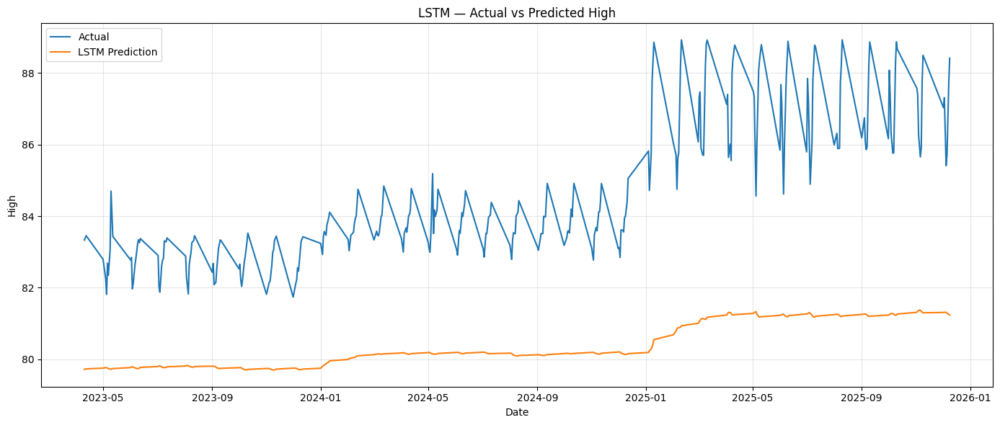

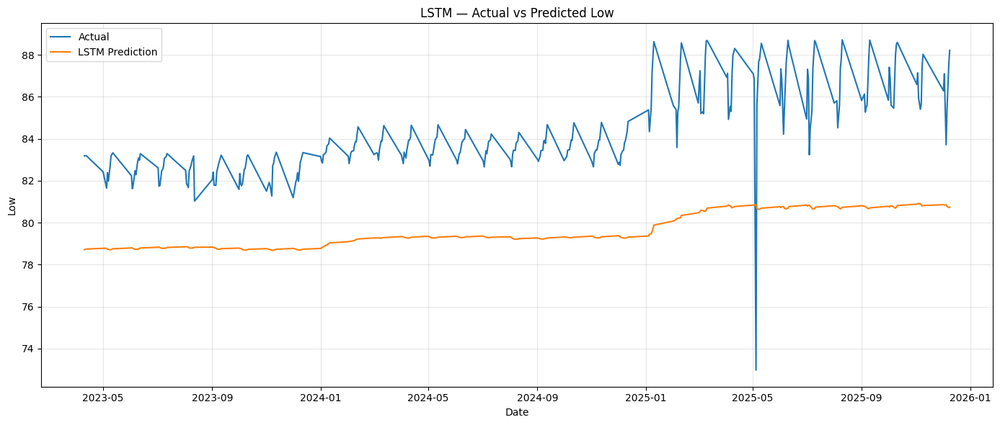

In [43]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in TARGETS:

    _, _, metrics, prediction_df = (
        lstm_results[target]
    )

    plt.figure(figsize=(14, 6))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Actual"],
        label="Actual"
    )

    plt.plot(
        prediction_df["Date"],
        prediction_df["Predicted"],
        label="LSTM Prediction"
    )

    plt.xlabel("Date")
    plt.ylabel(target)

    plt.title(
        f"LSTM — Actual vs Predicted {target}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Actual_vs_Predicted.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

TensorFlow: 2.17.0
Seed: 42
Original shape: (1929, 8)


RUNNING DF1
2007 - 2011
Regime observations: 504
Train: 352
Validation: 75
Test: 76
X_train: (327, 25, 4)
X_val: (75, 25, 4)
X_test: (76, 25, 4)


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_44 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_45 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 0.2056 - val_loss: 0.0137 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.1178 - val_loss: 0.0137 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0528 - val_loss: 0.0139 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0462 - val_loss: 0.0170 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0377 - val_loss: 0.0132 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0337 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0344 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0367 - val_loss: 0.0128 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0341 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 10/2

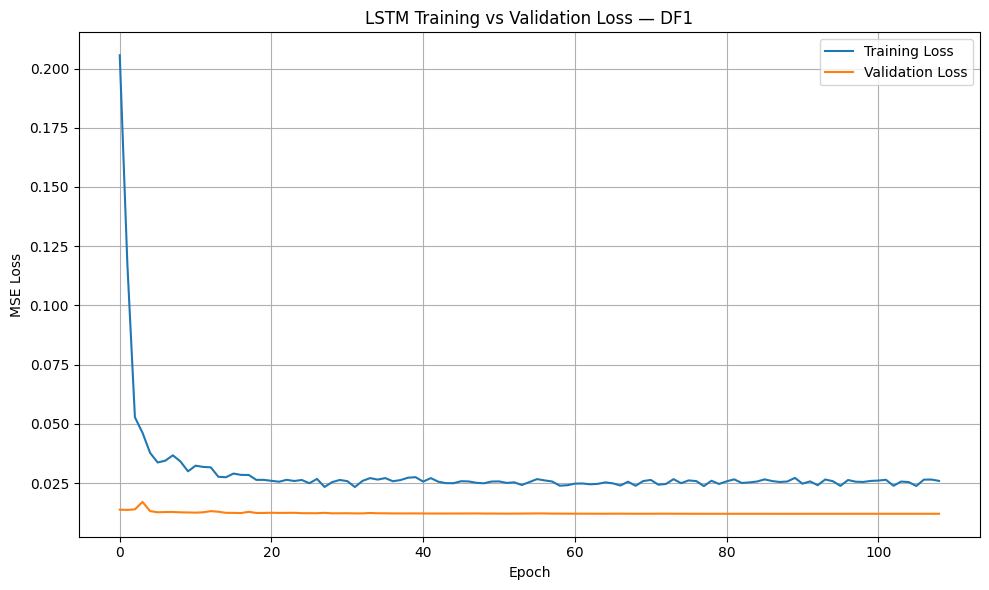

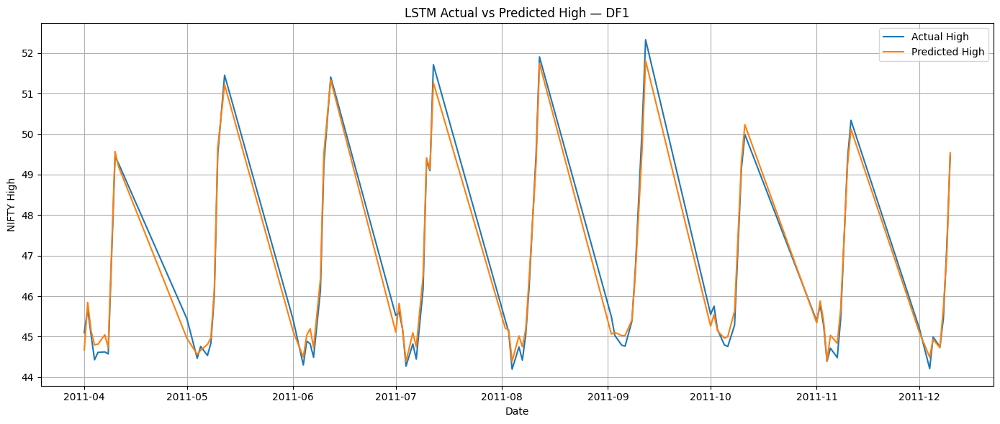

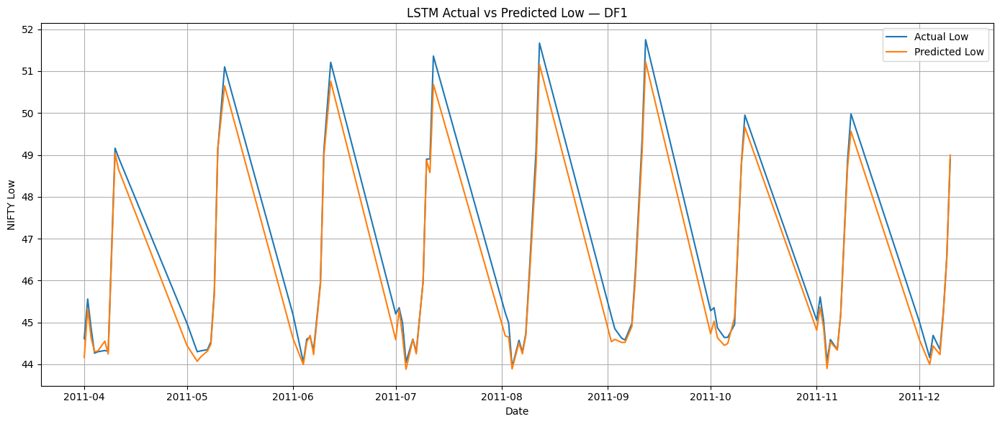

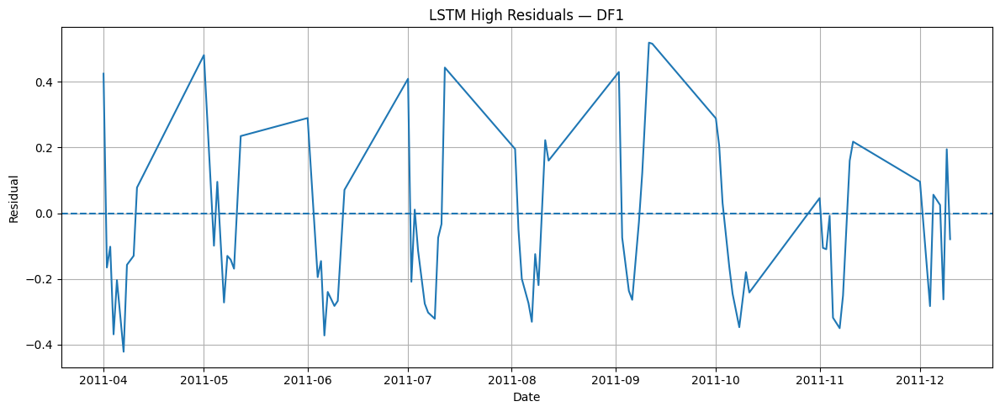

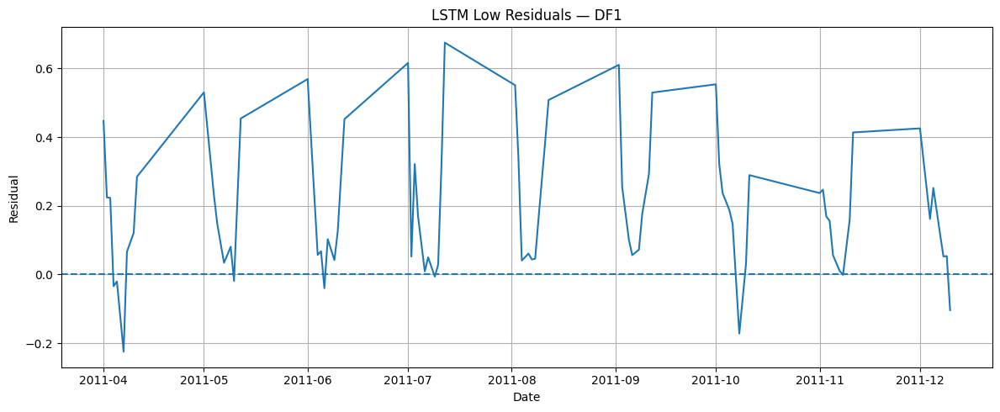

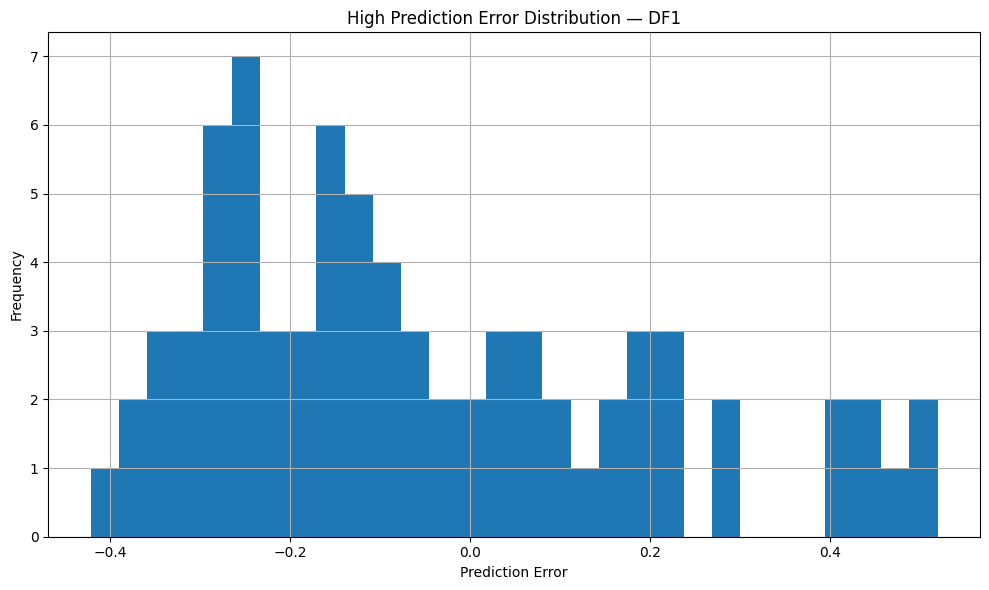

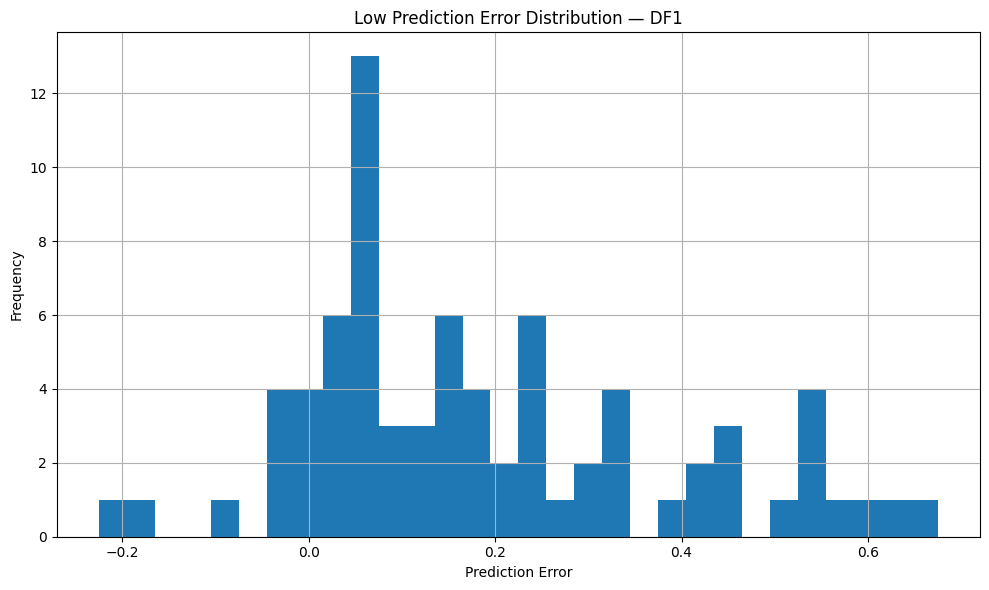


DF1 completed.


RUNNING DF2
2012 - 2019
Regime observations: 821
Train: 574
Validation: 123
Test: 123
X_train: (549, 25, 4)
X_val: (123, 25, 4)
X_test: (123, 25, 4)


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_46 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_47 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - loss: 0.1327 - val_loss: 0.0310 - learning_rate: 0.0010
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0365 - val_loss: 0.0241 - learning_rate: 0.0010
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0316 - val_loss: 0.0229 - learning_rate: 0.0010
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0266 - val_loss: 0.0221 - learning_rate: 0.0010
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0226 - val_loss: 0.0222 - learning_rate: 0.0010
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0217 - val_loss: 0.0219 - learning_rate: 0.0010
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0208 - val_loss: 0.0216 - learning_rate: 0.0010
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0214 - val_loss: 0.0220 - learning_rate: 0.0010
Epoch 9/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0212 - val_loss: 0.0219 - learning_rate: 0.0010
Epoch 10/2

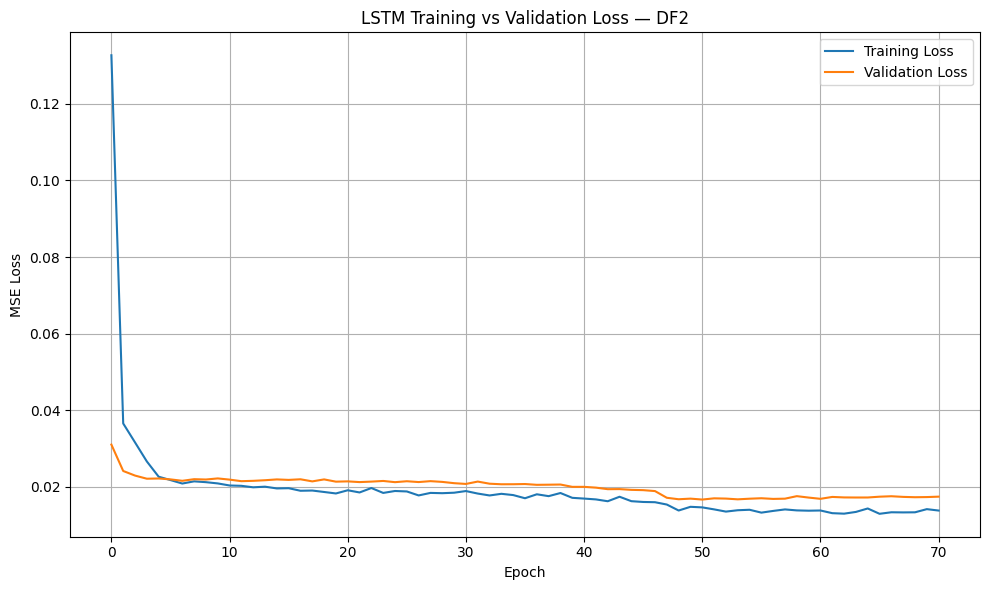

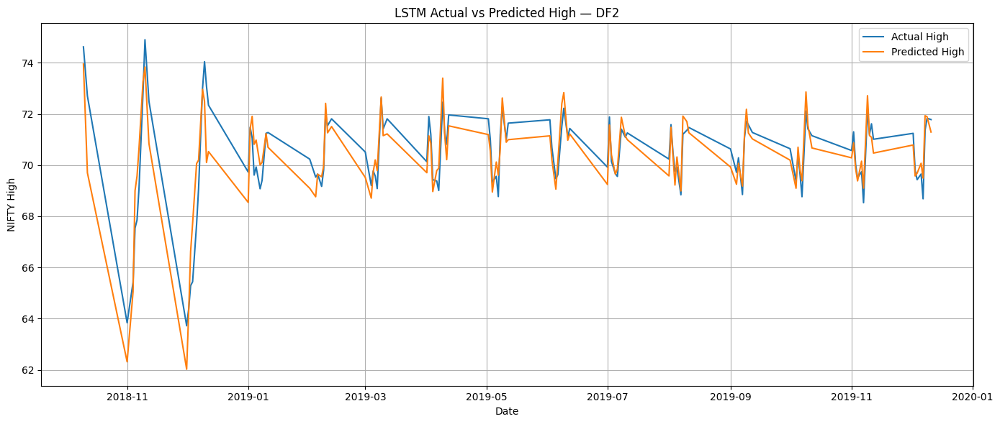

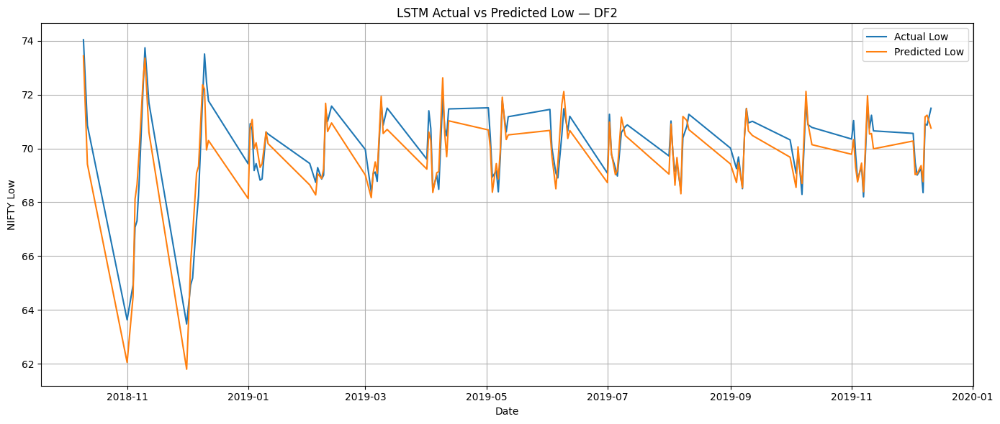

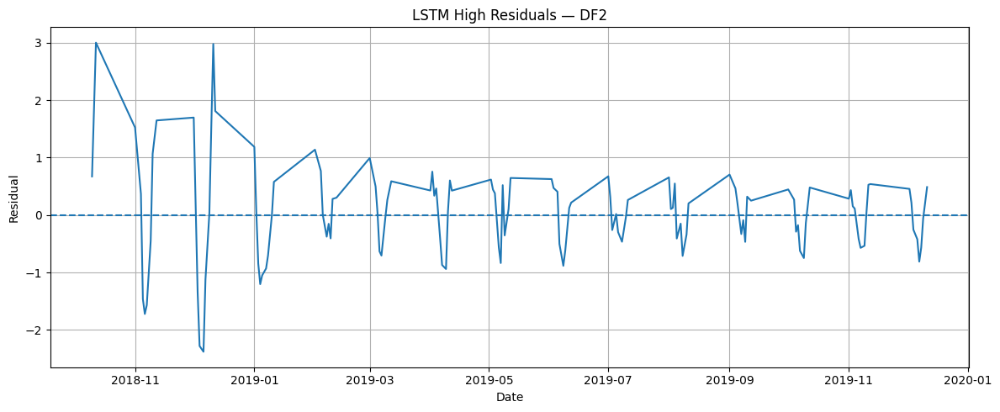

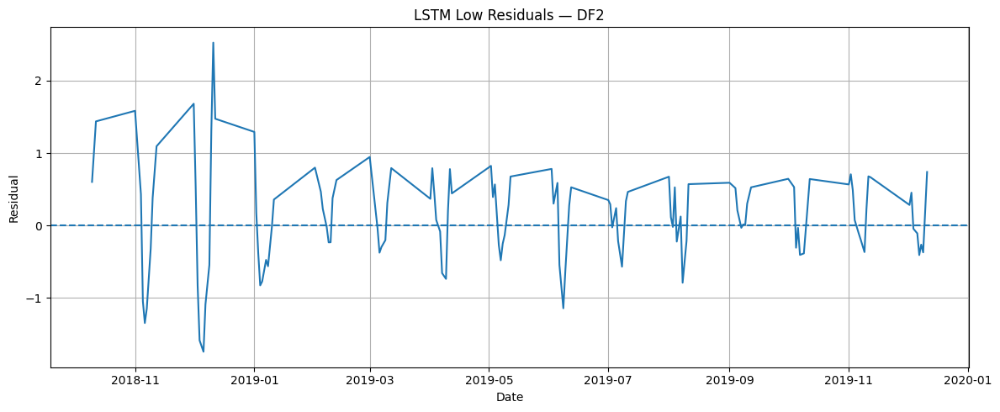

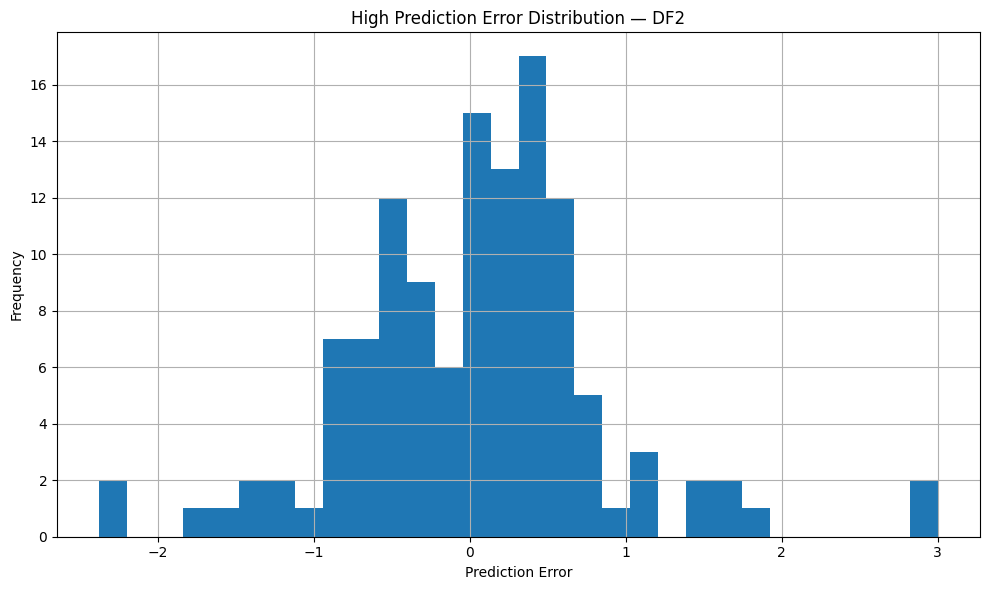

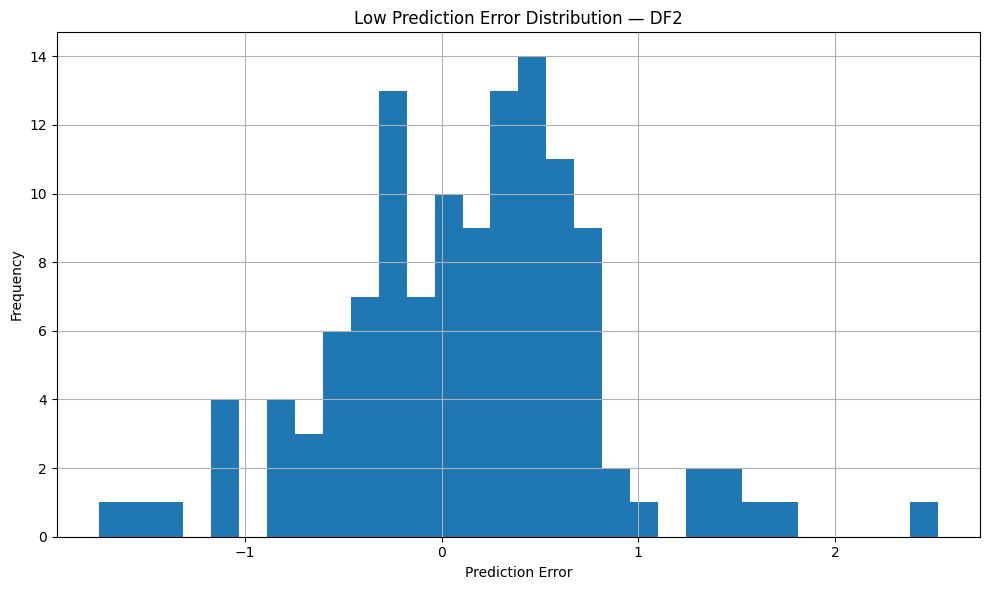


DF2 completed.


RUNNING DF3
2020 - 2022
Regime observations: 308
Train: 214
Validation: 46
Test: 47
X_train: (189, 25, 4)
X_val: (46, 25, 4)
X_test: (47, 25, 4)


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_48 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_49 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_49 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - loss: 0.1233 - val_loss: 0.1239 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0472 - val_loss: 0.2396 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0499 - val_loss: 0.1508 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0390 - val_loss: 0.1265 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0351 - val_loss: 0.1419 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0349 - val_loss: 0.1567 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0361 - val_loss: 0.1474 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0359 - val_loss: 0.1381 - learning_rate: 0.0010
Epoch 9/200
5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0419
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.000500000023748

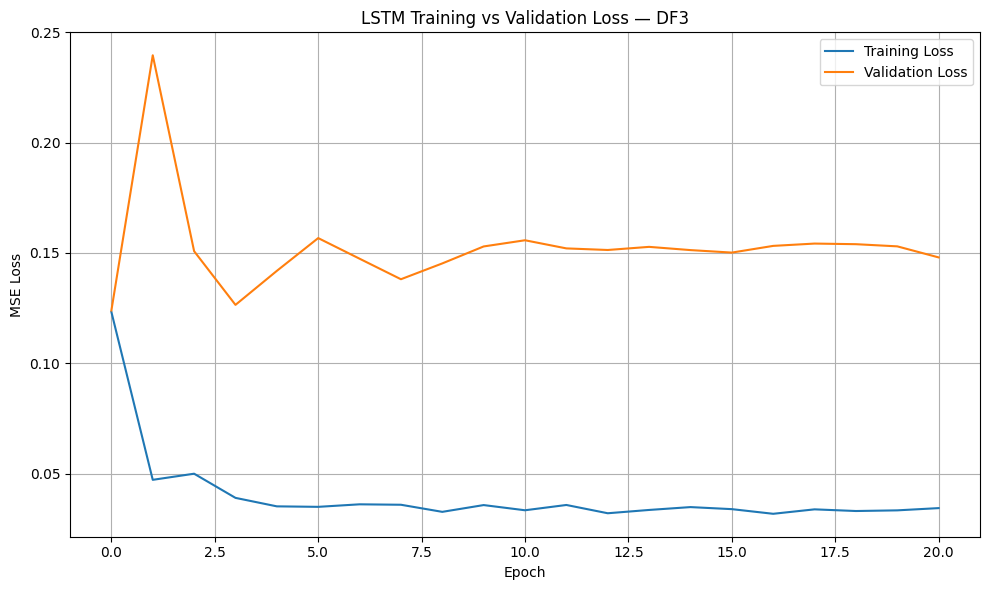

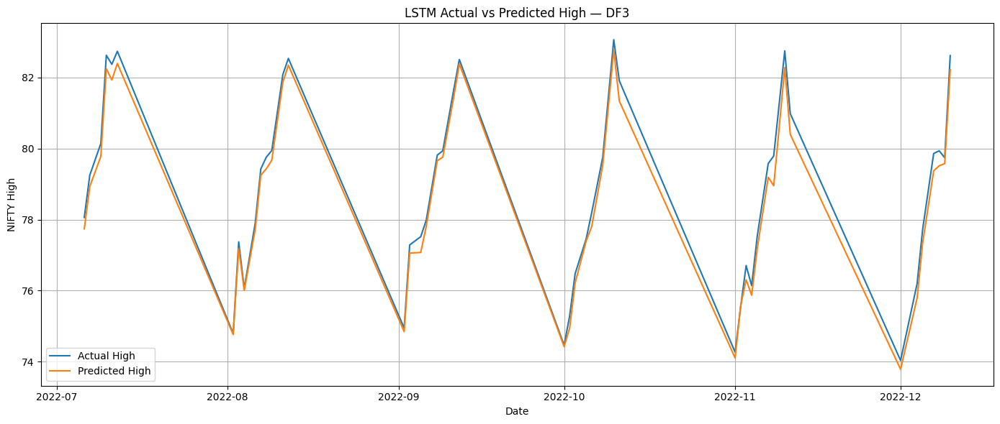

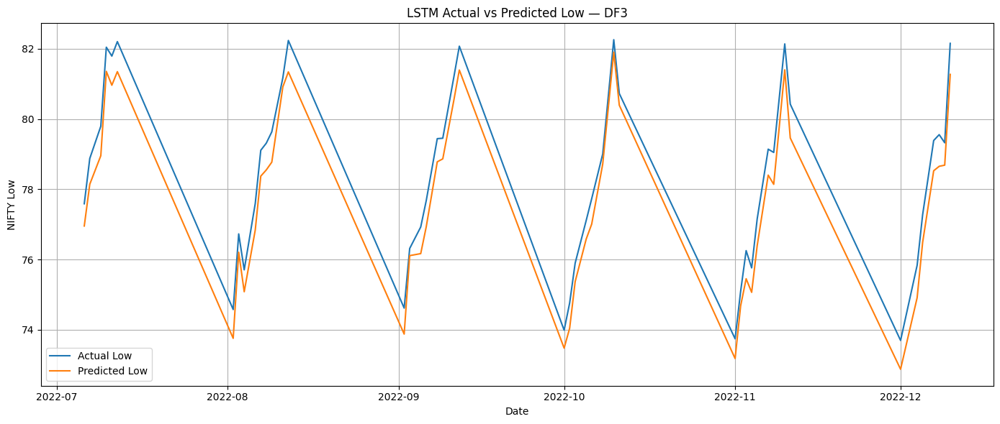

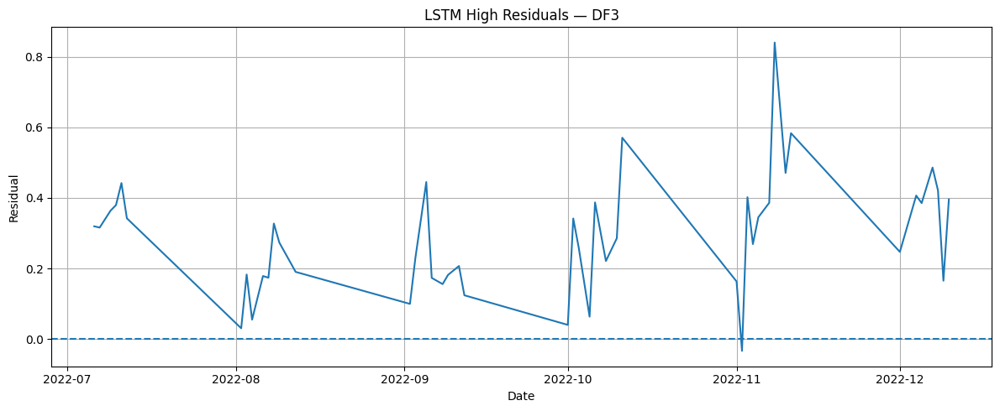

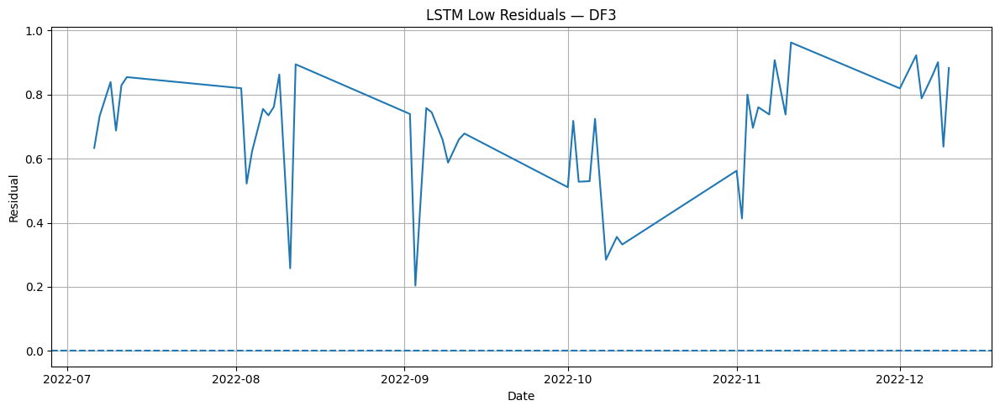

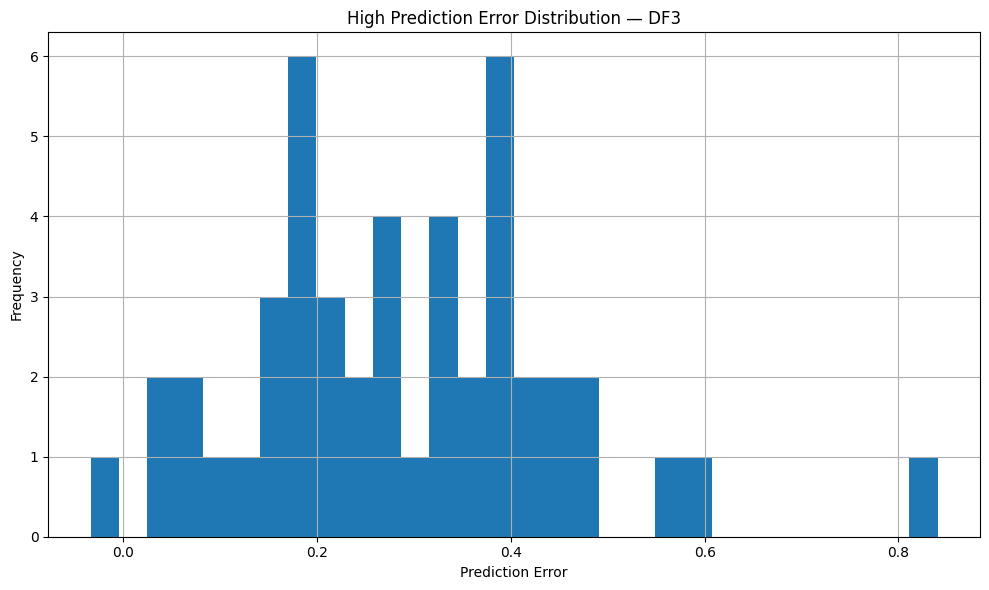

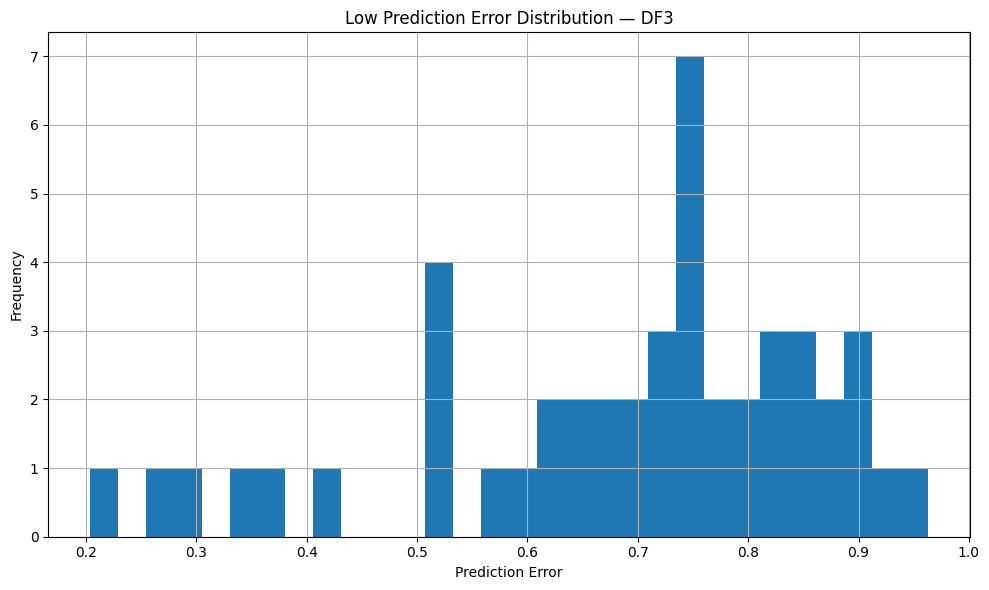


DF3 completed.


RUNNING DF4
2023 - 2025
Regime observations: 296
Train: 206
Validation: 44
Test: 45
X_train: (181, 25, 4)
X_val: (44, 25, 4)
X_test: (45, 25, 4)


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_50 (LSTM)                  │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_50 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_51 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_51 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,642 (119.70 KB)

 Trainable params: 30,642 (119.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - loss: 0.2739 - val_loss: 0.3446 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.1002 - val_loss: 0.4703 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0644 - val_loss: 0.3755 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0486 - val_loss: 0.3383 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0569 - val_loss: 0.3397 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0477 - val_loss: 0.3443 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0471 - val_loss: 0.3427 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0433 - val_loss: 0.3403 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0412 - val_loss: 0.3387 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

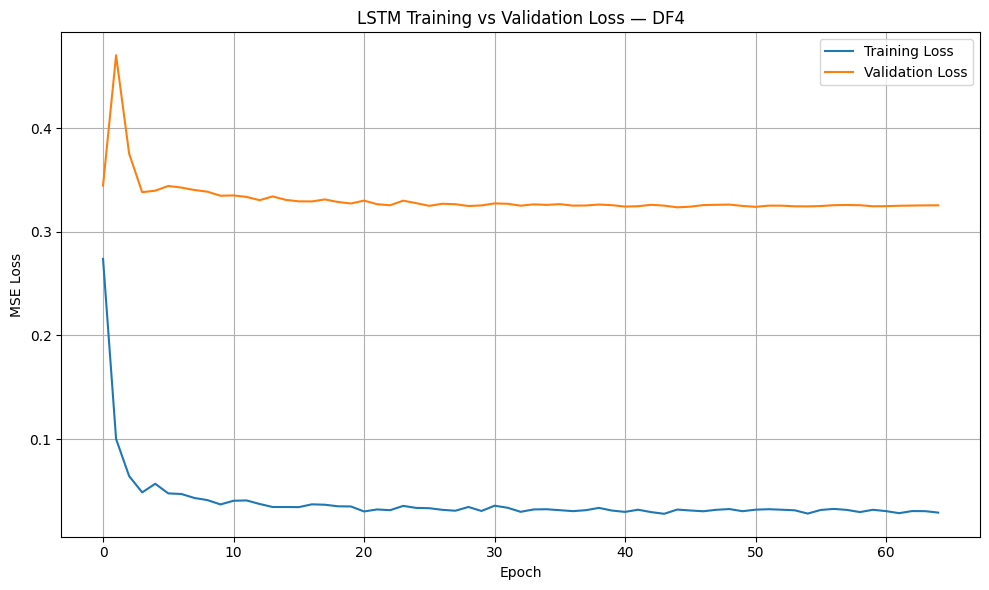

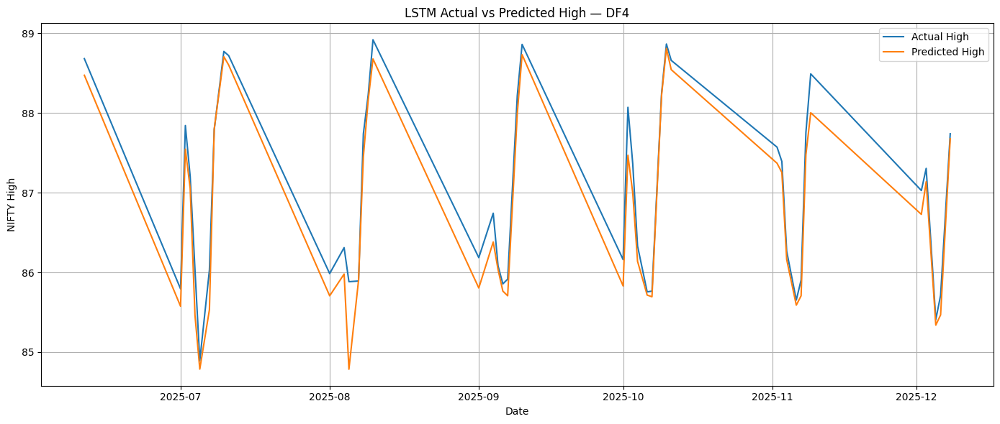

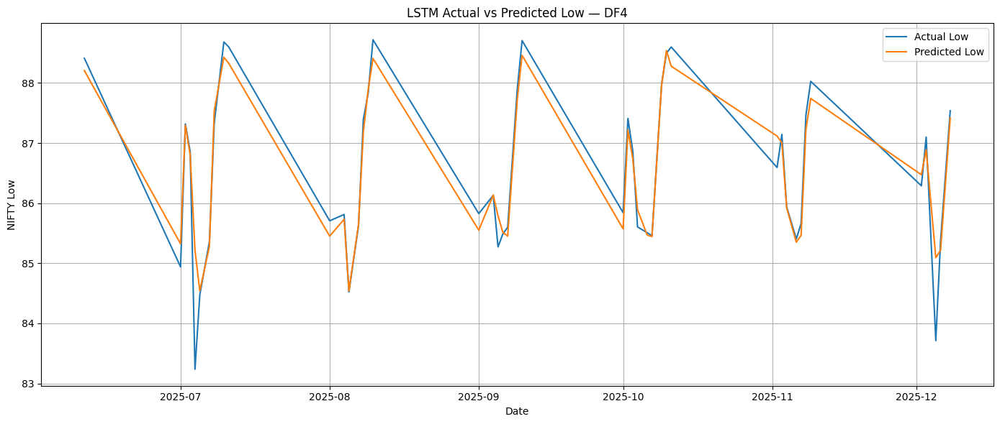

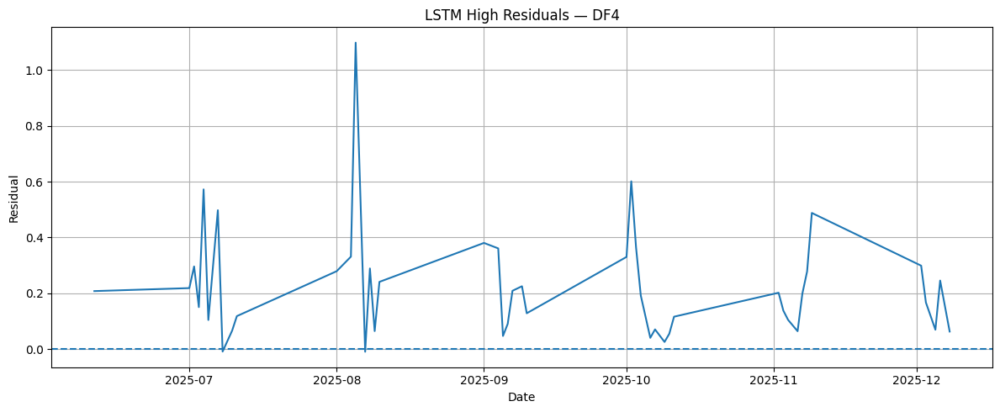

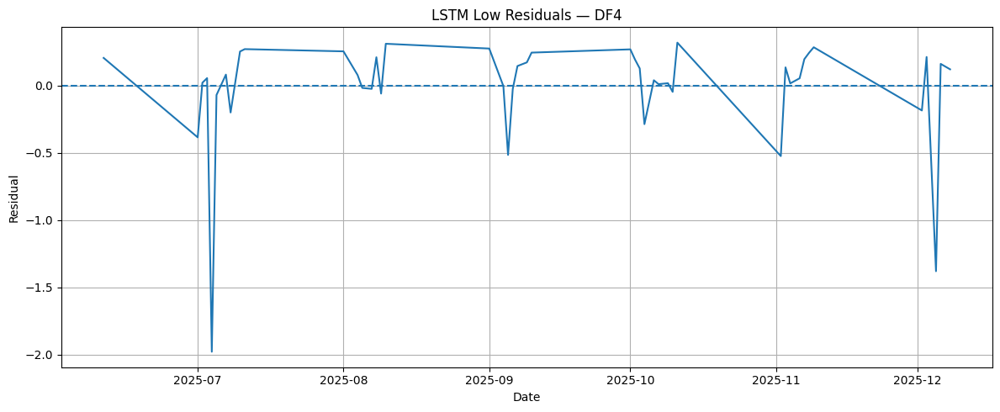

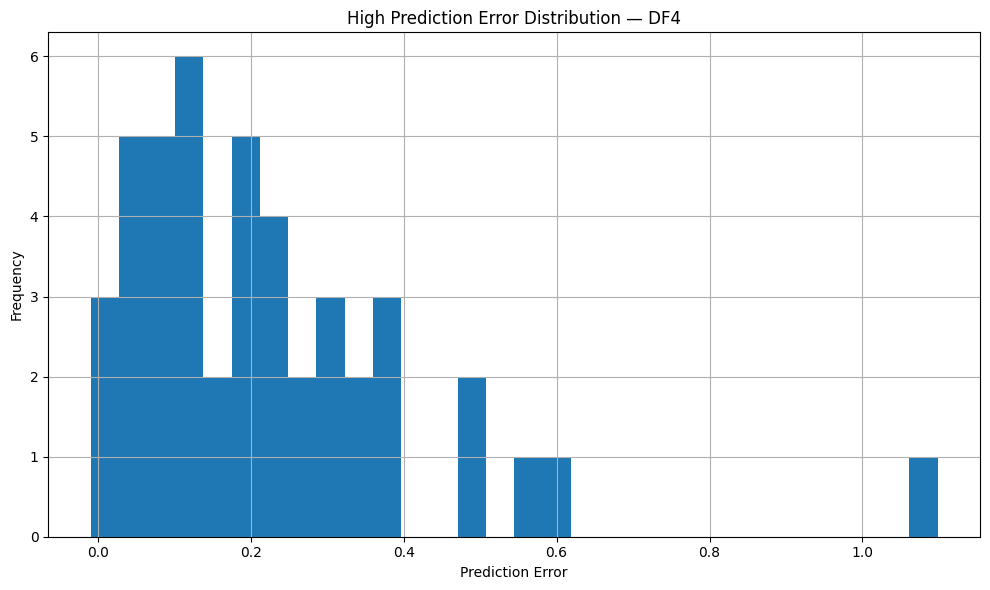

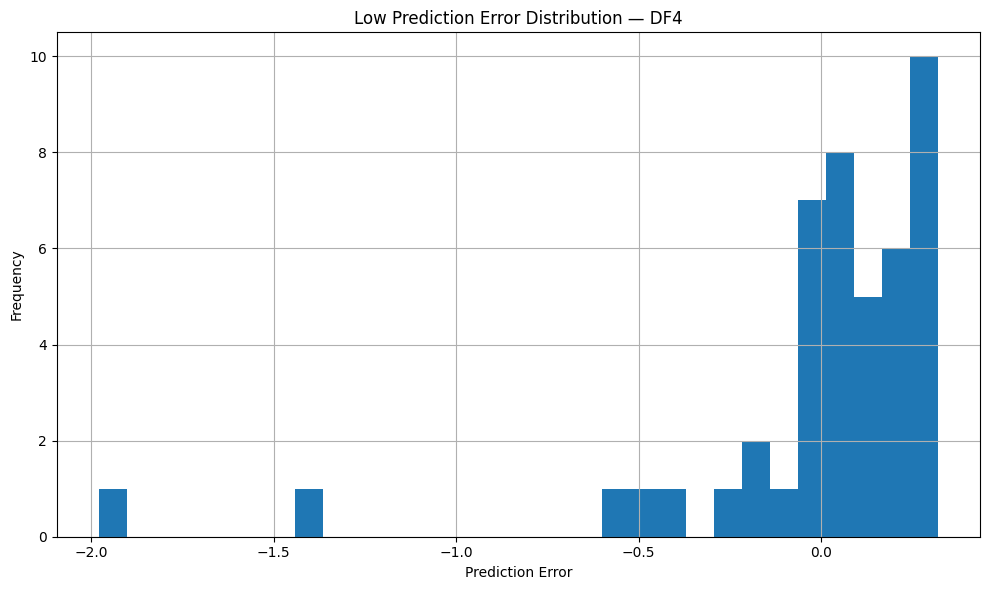


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE  High_R2  High_MAPE  Low_MAE  Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1  0.210016   0.244623 0.988415   0.453913 0.206533  0.273744 0.984801  0.443064                 327                       75                 76
   DF2  0.606929   0.822927 0.804453   0.866565 0.525582  0.675806 0.857070  0.755353                 549                      123                123
   DF3  0.288936   0.330356 0.984214   0.364097 0.685634  0.709609 0.923934  0.874947                 189                       46                 47
   DF4  0.224670   0.299011 0.934819   0.258530 0.237585  0.415842 0.911617  0.277148                 181                       44                 45

Results saved to:
LSTM_Regime_Results


In [50]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


DATA_PATH = "nifty50_2007_to_now.csv"

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2011
    },

    "DF2": {
        "start": 2012,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2022
    },

    "DF4": {
        "start": 2023,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=(LOOKBACK, 4)
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            2
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

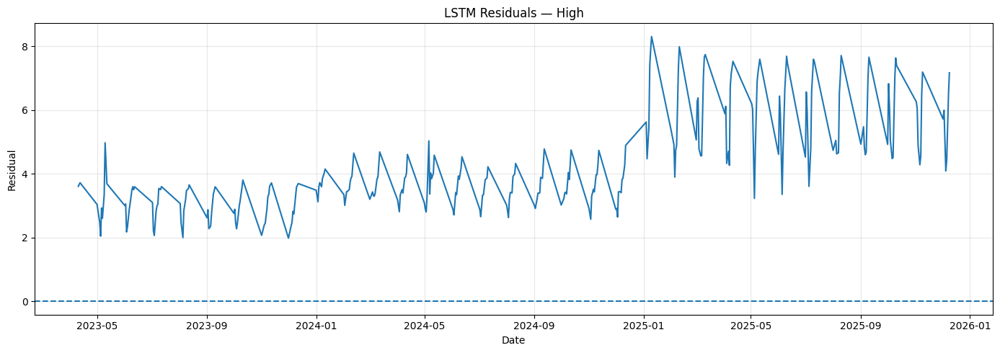

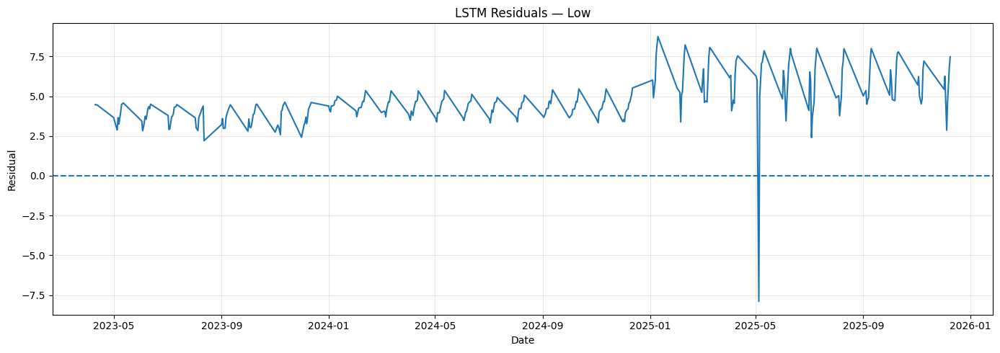

In [51]:
# ============================================================
# RESIDUAL ANALYSIS
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    prediction_df["Residual"] = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Residual"]
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")
    plt.ylabel("Residual")

    plt.title(
        f"LSTM Residuals — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Residuals.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

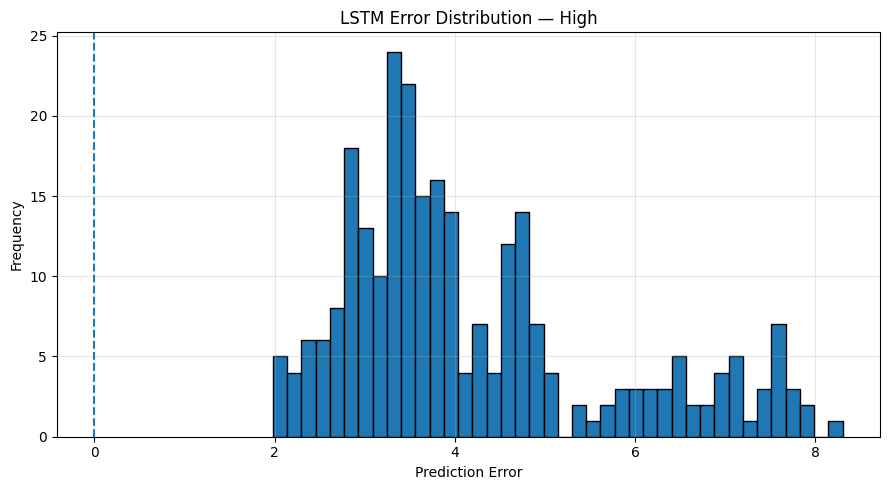

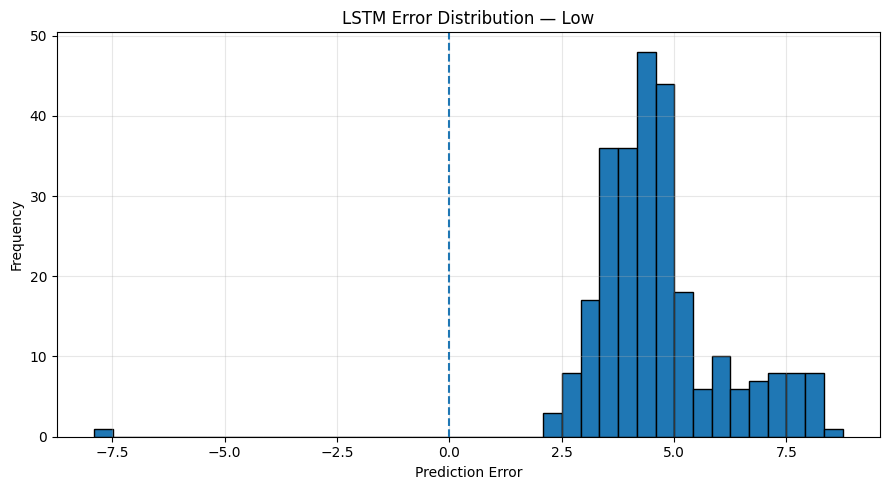

In [52]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

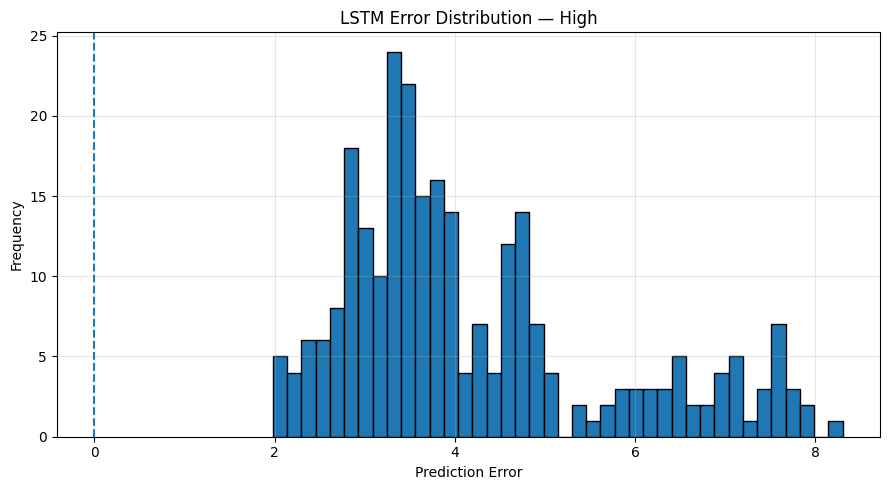

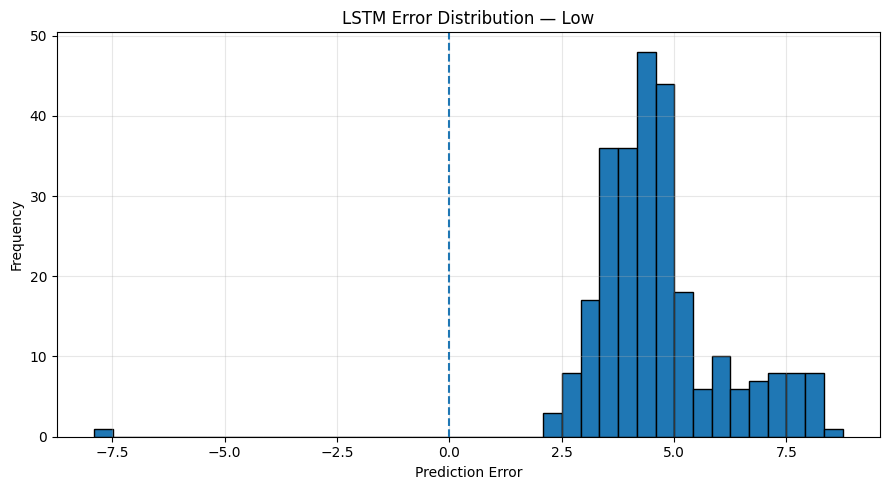

In [53]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

TensorFlow: 2.17.0
Seed: 42
Original shape: (1929, 8)


RUNNING DF1
2007 - 2011
Regime observations: 504
Train: 352
Validation: 75
Test: 76
X_train: (327, 25, 4)
X_val: (75, 25, 4)
X_test: (76, 25, 4)


Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_16                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_52 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_17                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_53 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - loss: 0.2040 - val_loss: 0.0523 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1399 - val_loss: 0.0362 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0851 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0483 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0442 - val_loss: 0.0129 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0412 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0360 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0308 - val_loss: 0.0122 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0312 - val_loss: 0.0121 - learning_rate: 0.0010
Epoch 10/

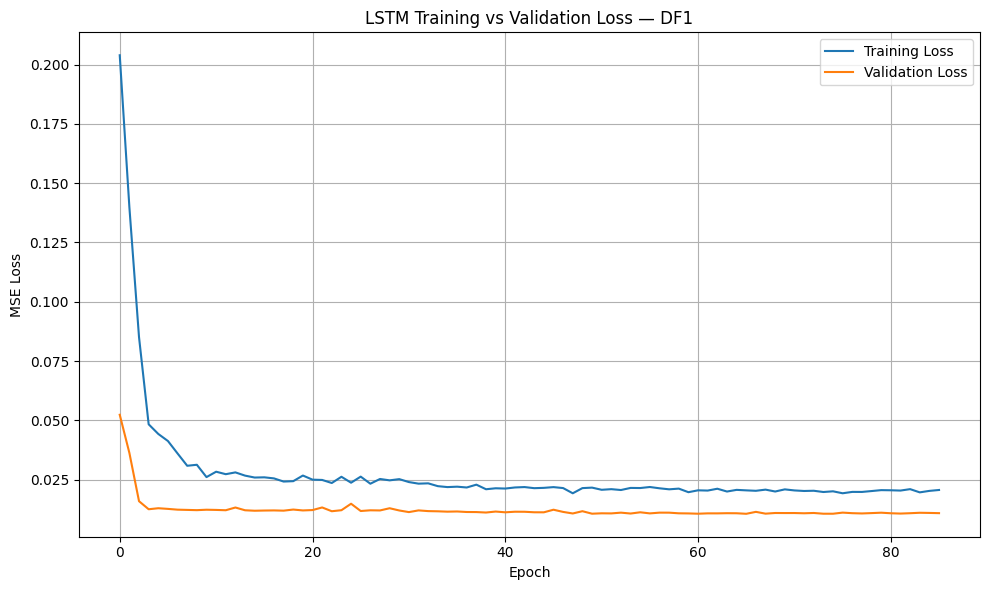

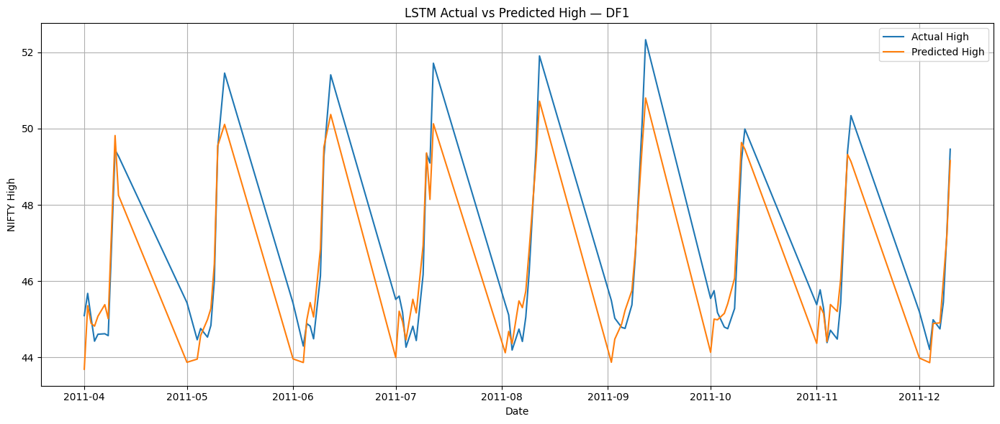

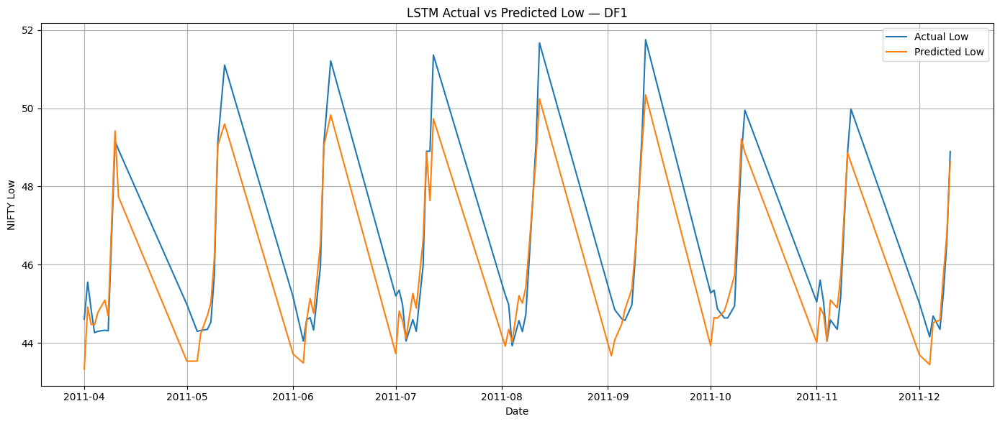

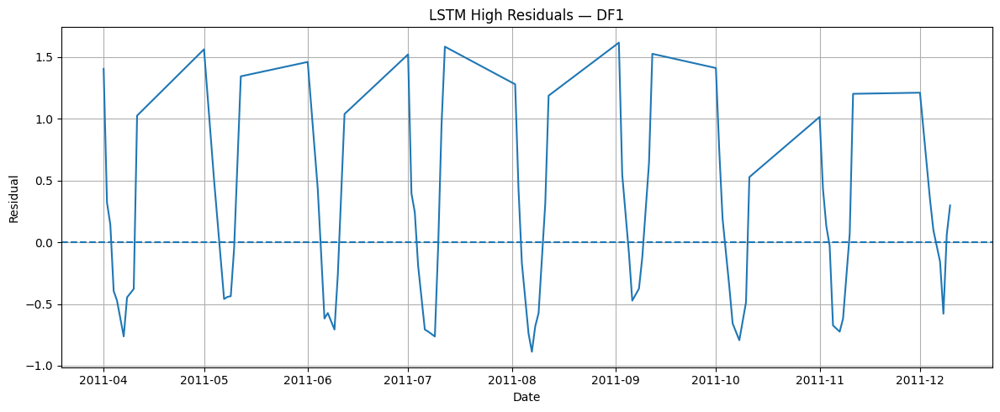

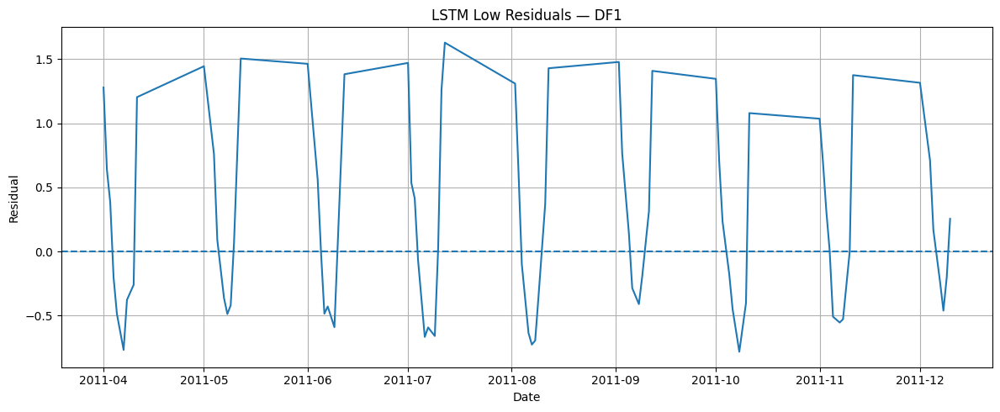

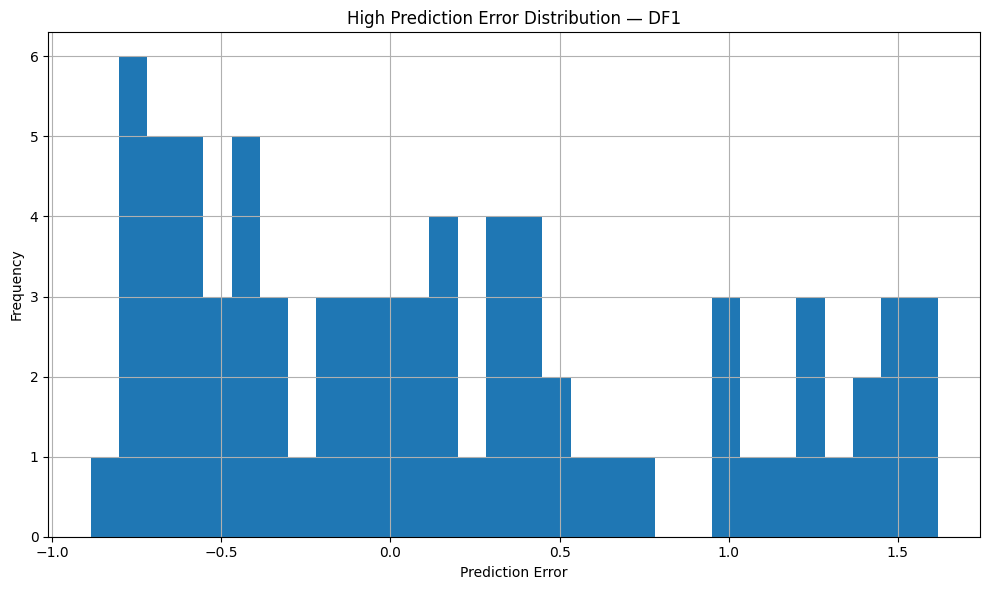

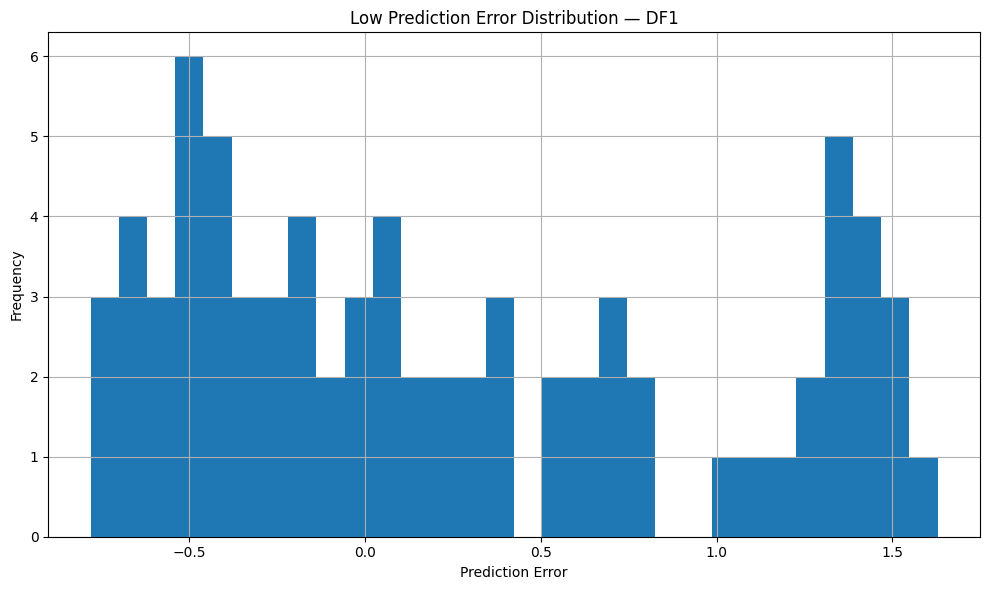


DF1 completed.


RUNNING DF2
2012 - 2019
Regime observations: 821
Train: 574
Validation: 123
Test: 123
X_train: (549, 25, 4)
X_val: (123, 25, 4)
X_test: (123, 25, 4)


Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_18                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_54 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_19                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_55 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - loss: 0.1110 - val_loss: 0.0285 - learning_rate: 0.0010
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0534 - val_loss: 0.0217 - learning_rate: 0.0010
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0315 - val_loss: 0.0216 - learning_rate: 0.0010
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0255 - val_loss: 0.0222 - learning_rate: 0.0010
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0236 - val_loss: 0.0218 - learning_rate: 0.0010
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0207 - val_loss: 0.0213 - learning_rate: 0.0010
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0210 - val_loss: 0.0212 - learning_rate: 0.0010
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0203 - val_loss: 0.0218 - learning_rate: 0.0010
Epoch 9/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0198 - val_loss: 0.0225 - learning_rate: 0.0010
Epoch 10/2

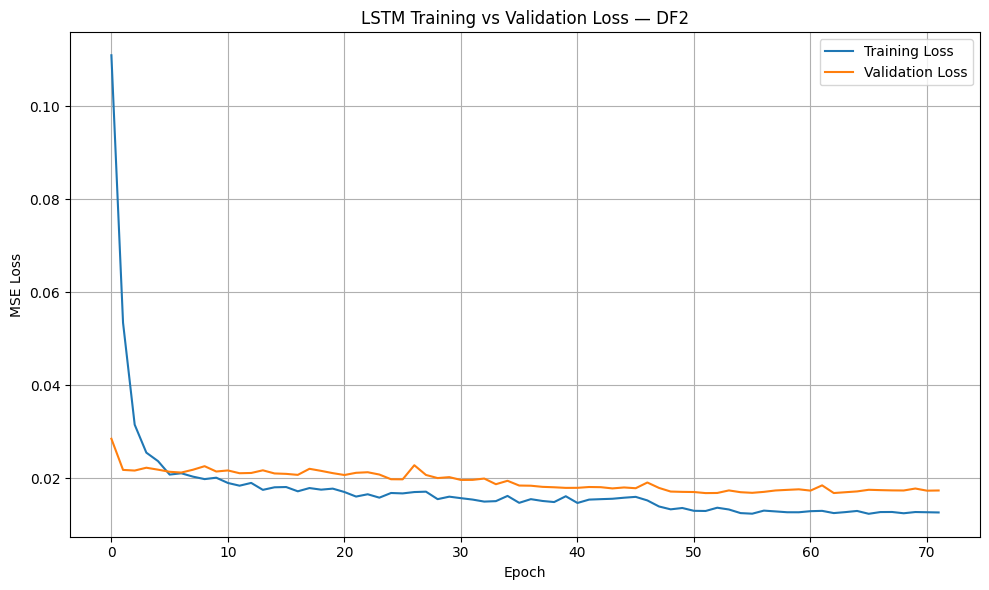

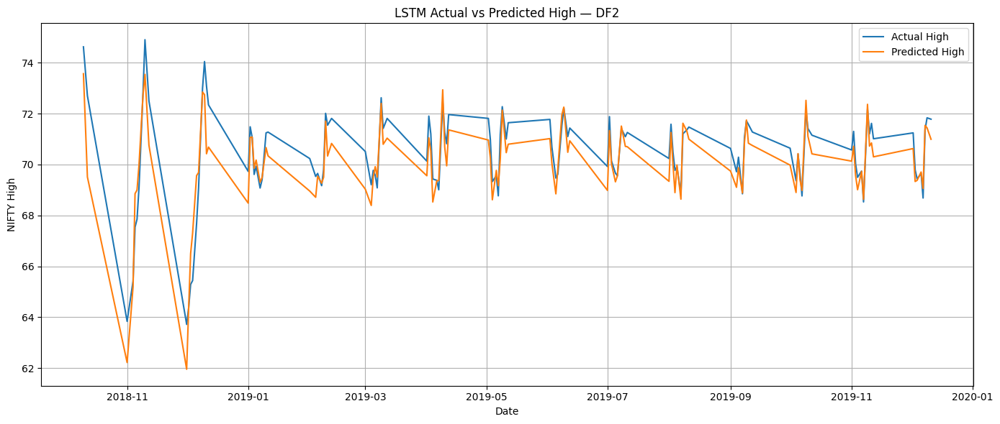

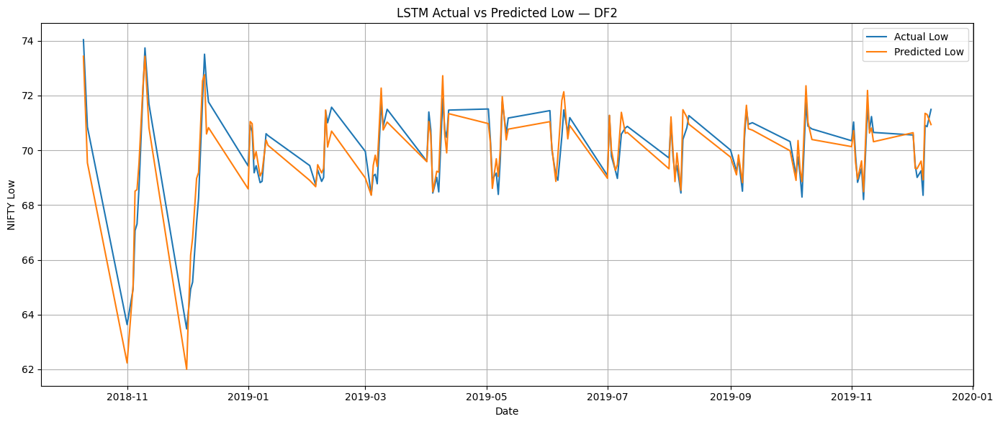

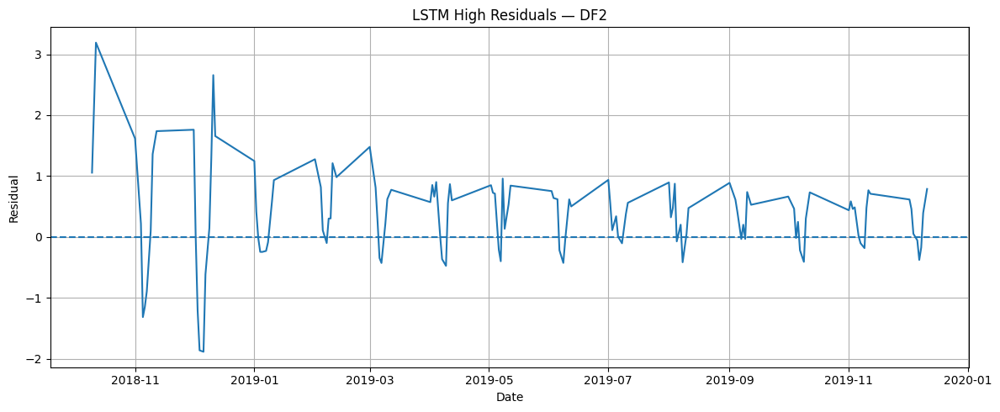

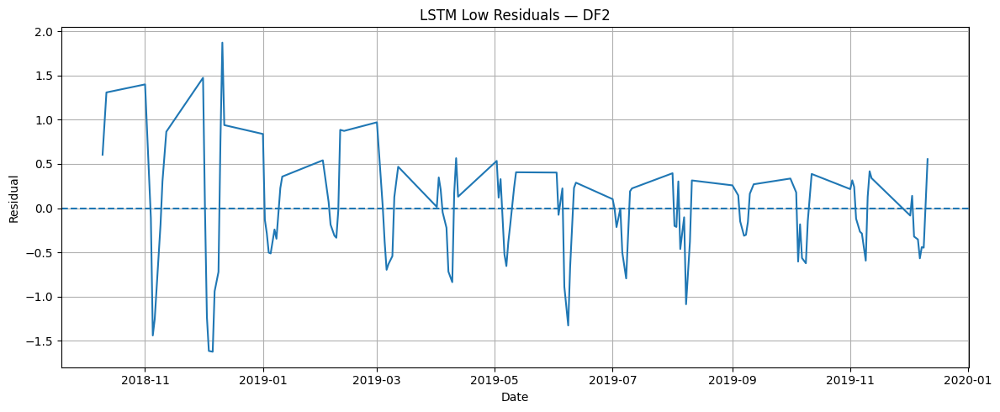

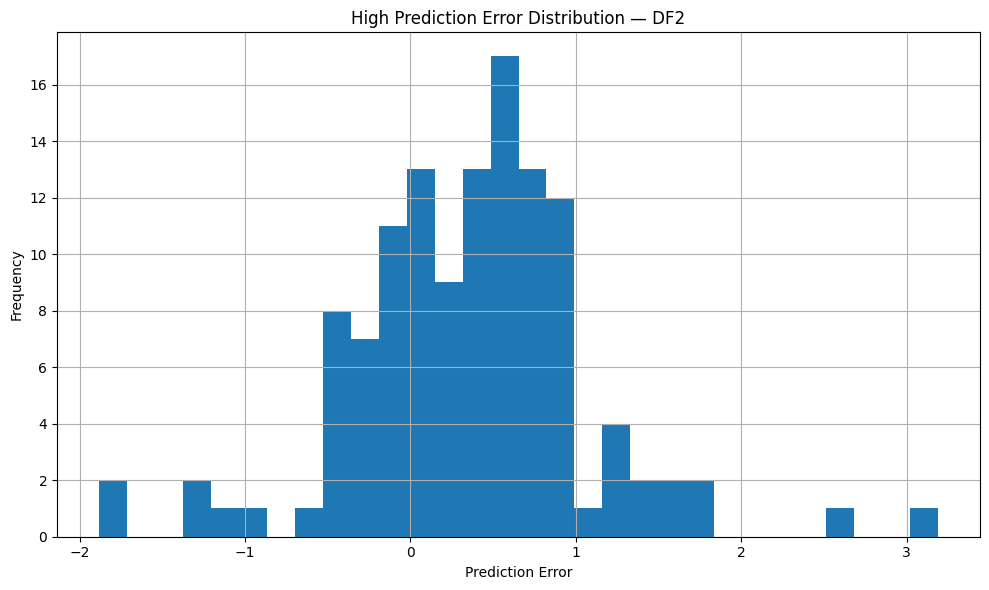

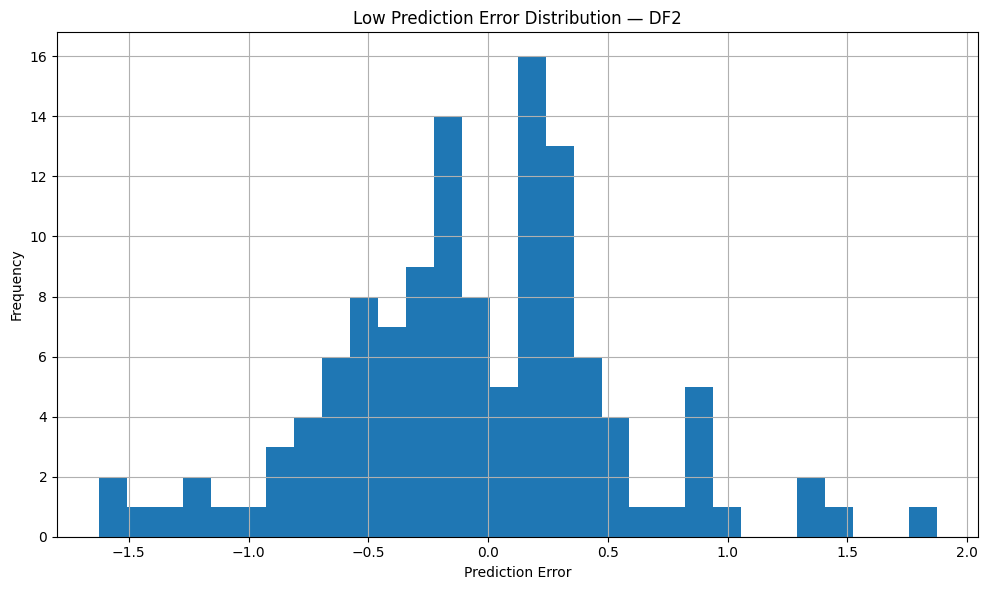


DF2 completed.


RUNNING DF3
2020 - 2022
Regime observations: 308
Train: 214
Validation: 46
Test: 47
X_train: (189, 25, 4)
X_val: (46, 25, 4)
X_test: (47, 25, 4)


Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_20                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_56 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_21                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_57 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 175ms/step - loss: 0.0884 - val_loss: 0.2386 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0463 - val_loss: 0.2217 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0383 - val_loss: 0.1470 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0351 - val_loss: 0.1806 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0345 - val_loss: 0.2079 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0332 - val_loss: 0.1826 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0319 - val_loss: 0.1809 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0335 - val_loss: 0.1947 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0330 - val_loss: 0.1833 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

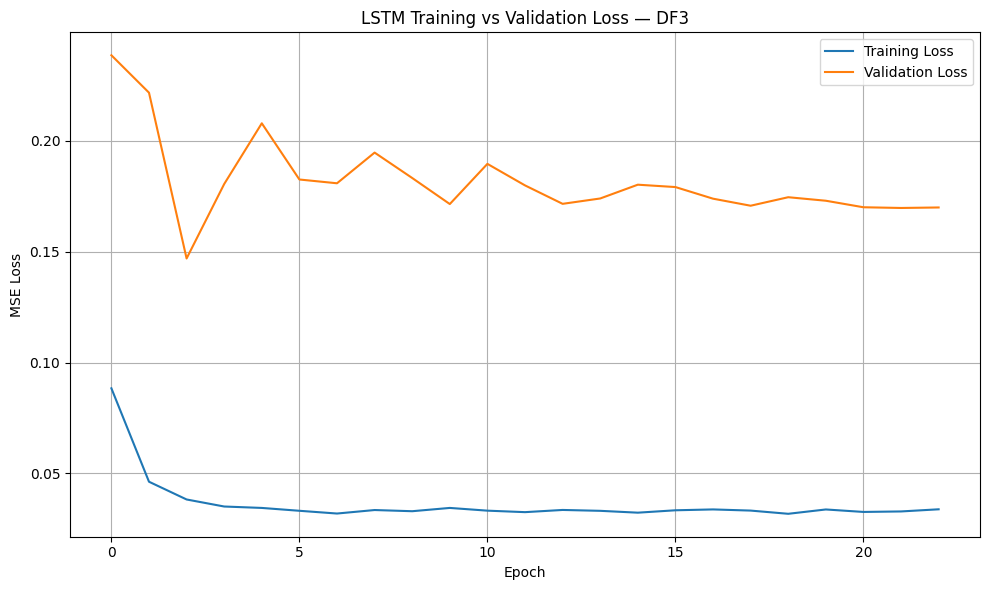

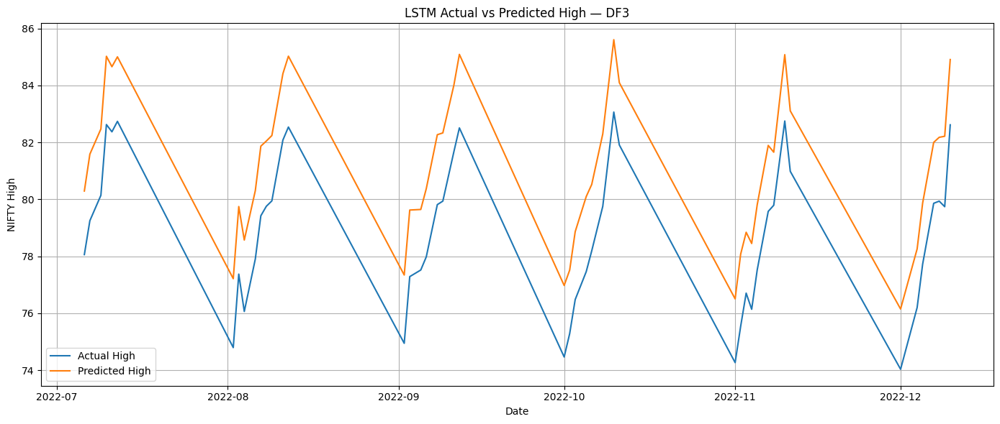

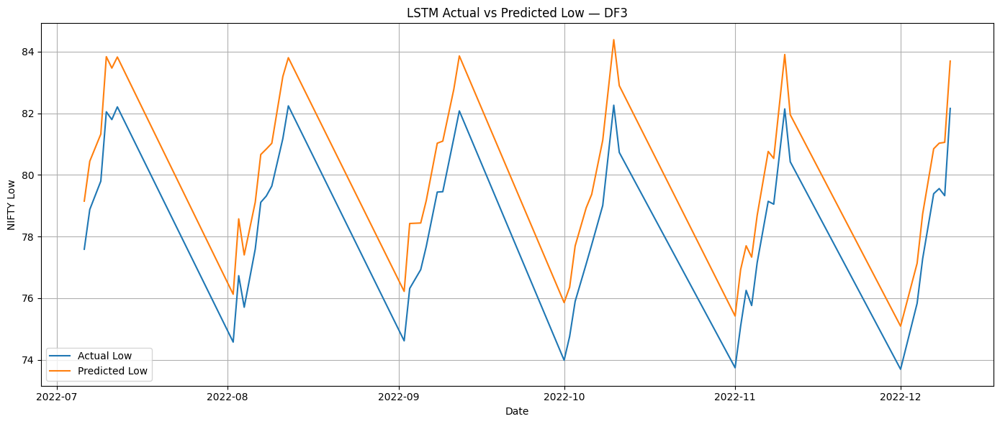

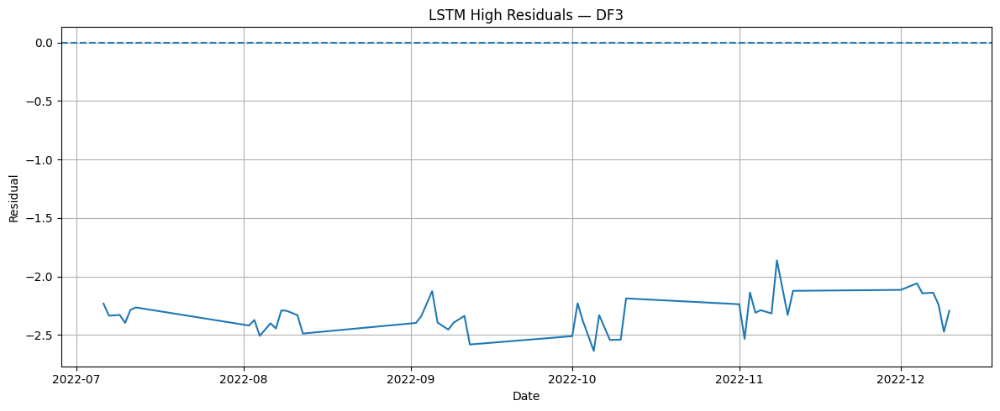

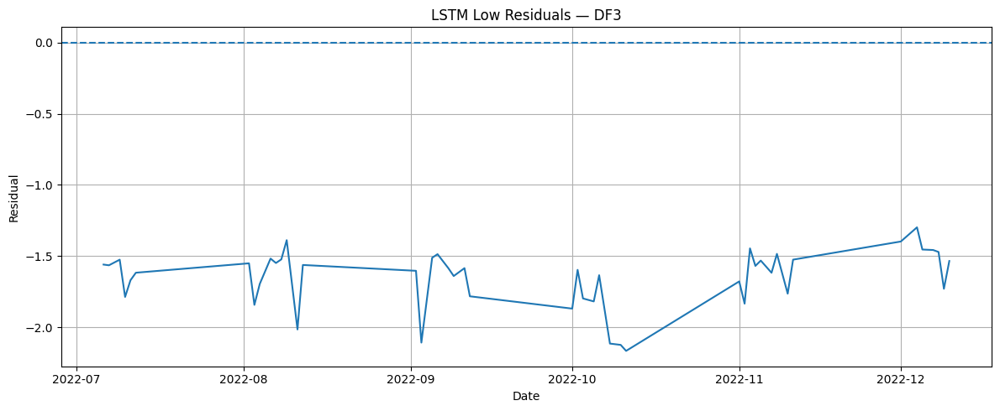

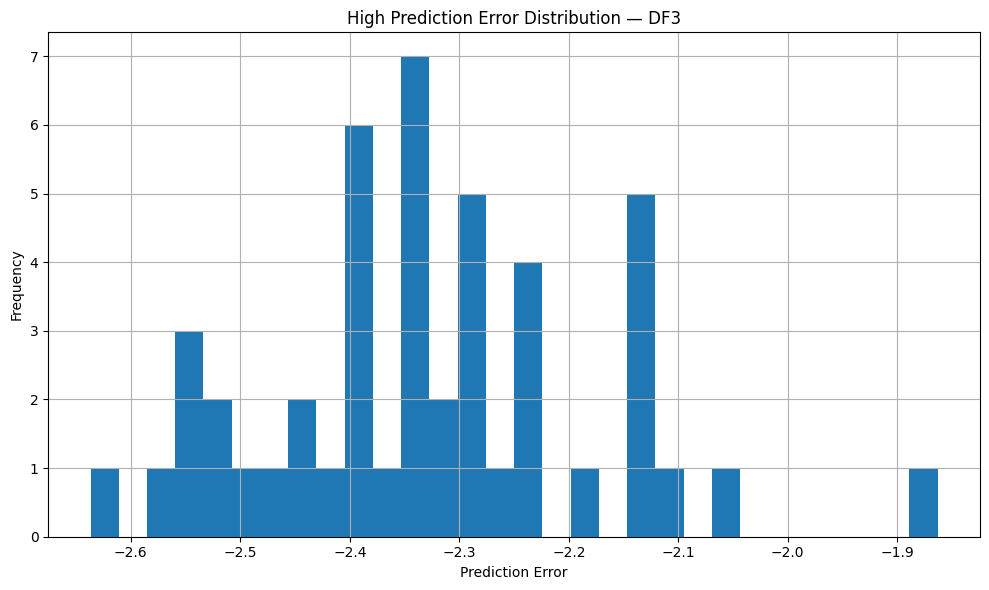

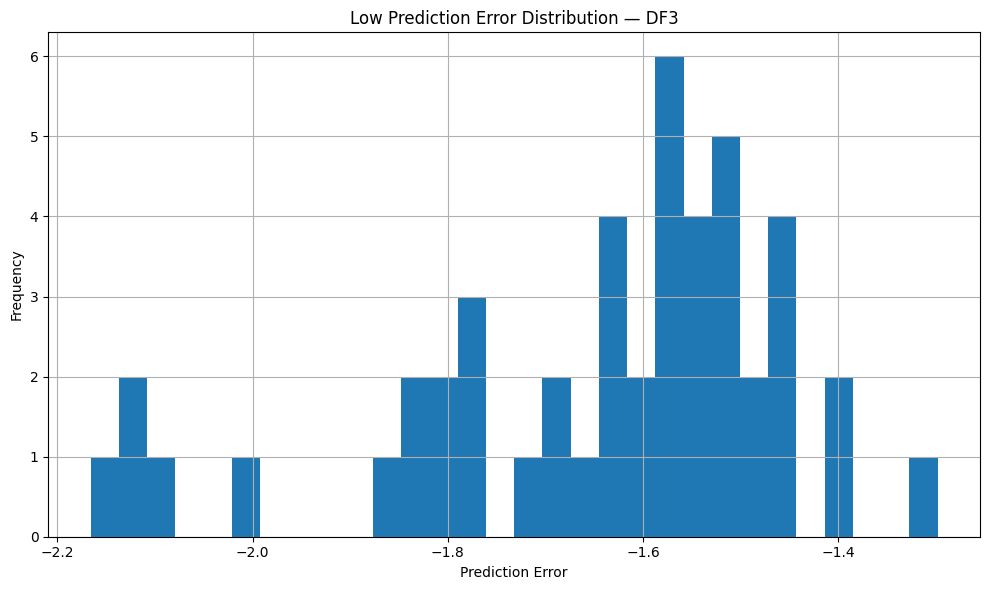


DF3 completed.


RUNNING DF4
2023 - 2025
Regime observations: 296
Train: 206
Validation: 44
Test: 45
X_train: (181, 25, 4)
X_val: (44, 25, 4)
X_test: (45, 25, 4)


Model: "sequential_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_22                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_58 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_23                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_59 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 192ms/step - loss: 0.2237 - val_loss: 0.6872 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1268 - val_loss: 0.6913 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0497 - val_loss: 0.3905 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0625 - val_loss: 0.3976 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0574 - val_loss: 0.4616 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0481 - val_loss: 0.4562 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0417 - val_loss: 0.4028 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0398 - val_loss: 0.3716 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0401 - val_loss: 0.3631 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

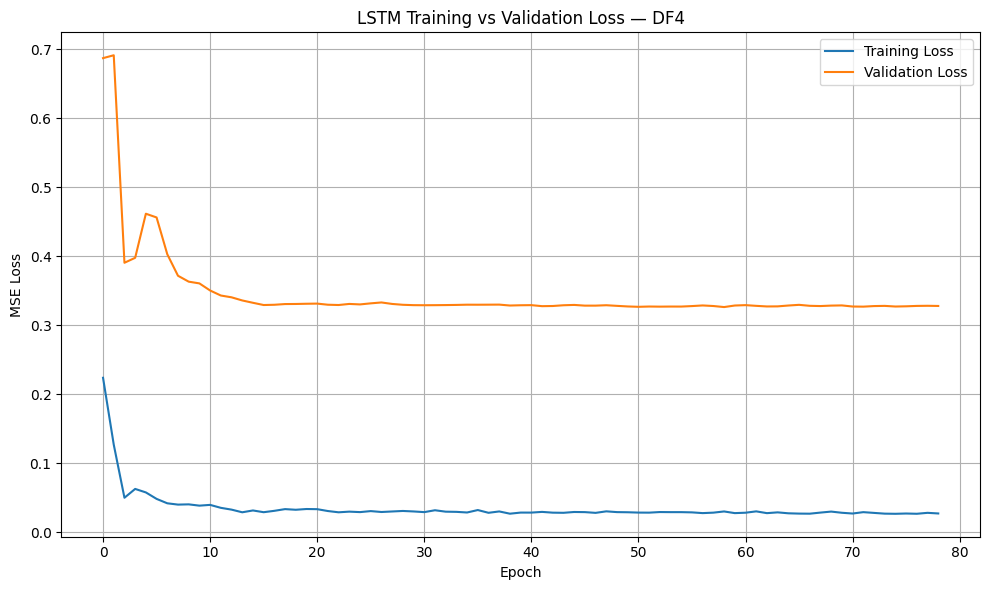

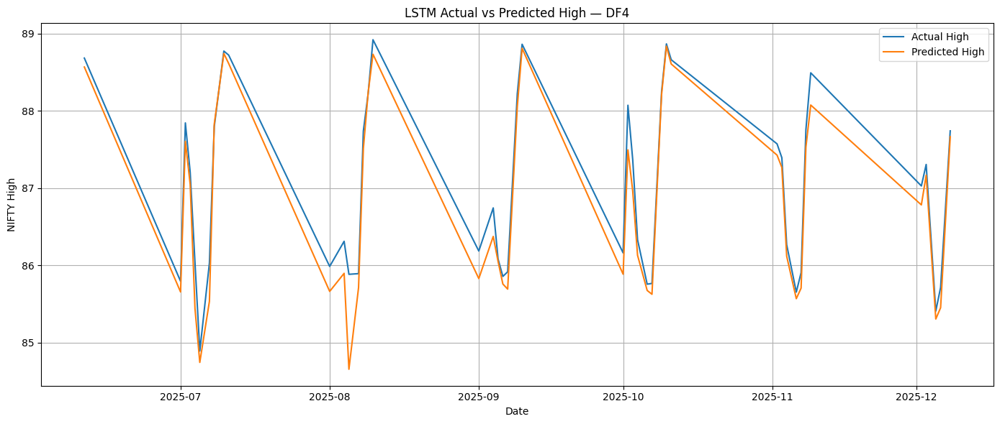

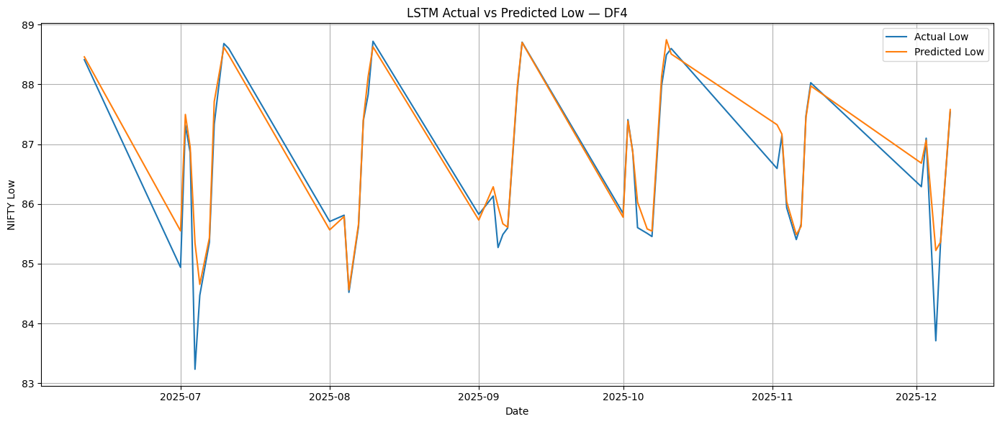

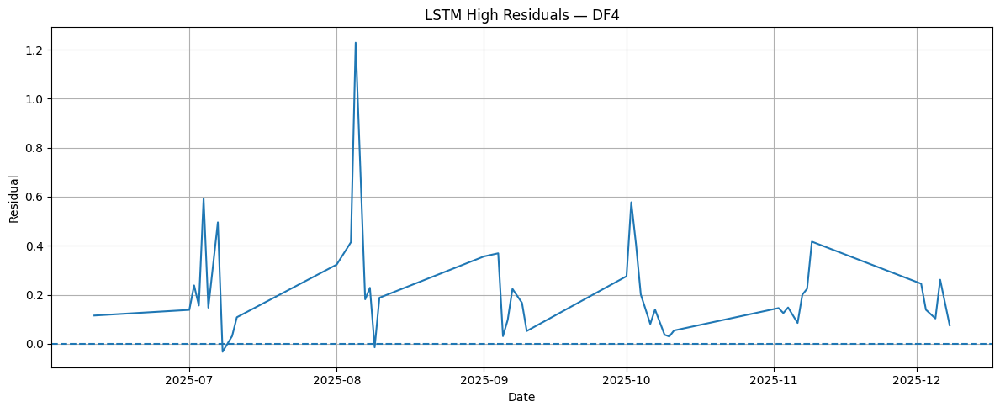

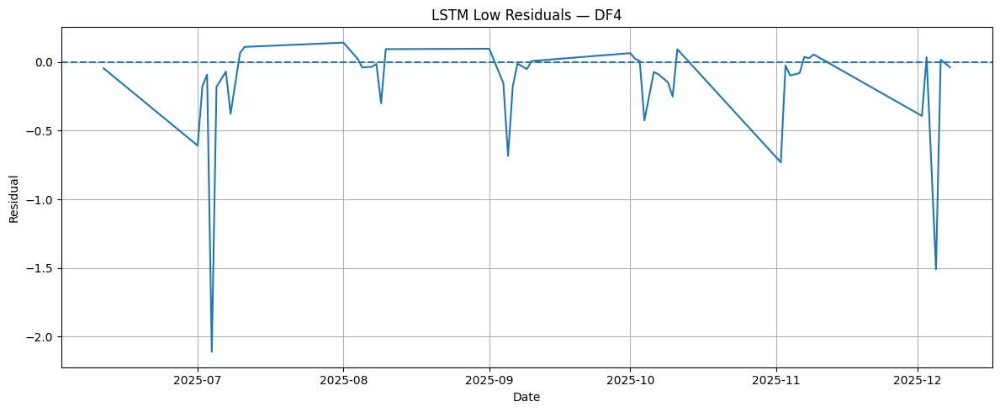

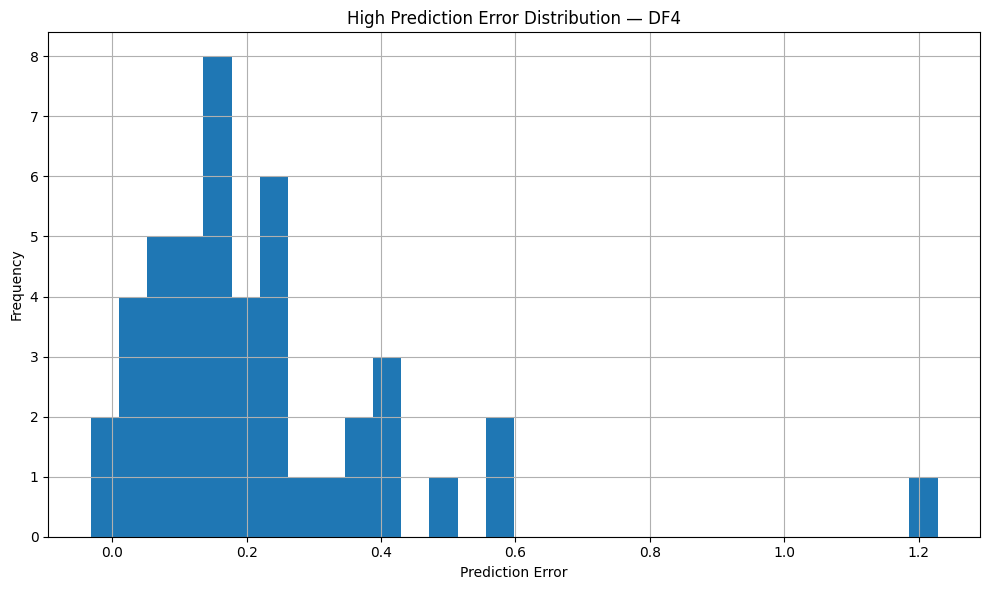

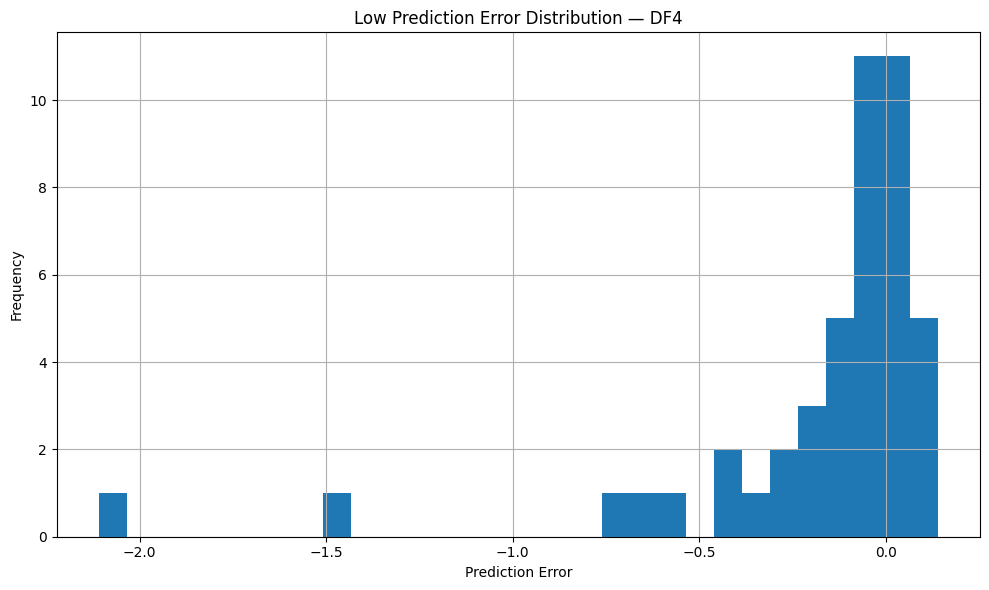


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE  High_R2  High_MAPE  Low_MAE  Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1  0.619632   0.759215 0.888411   1.330802 0.629309  0.778056 0.877211  1.356035                 327                       75                 76
   DF2  0.611686   0.808743 0.811136   0.869798 0.462453  0.603184 0.886138  0.665770                 549                      123                123
   DF3  2.327480   2.332331 0.213179   2.954032 1.650727  1.663020 0.582219  2.107193                 189                       46                 47
   DF4  0.220176   0.303606 0.932800   0.253859 0.219928  0.447332 0.897725  0.257942                 181                       44                 45

Results saved to:
LSTM_Regime_Results


In [54]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


DATA_PATH = "nifty50_2007_to_now.csv"

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2011
    },

    "DF2": {
        "start": 2012,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2022
    },

    "DF4": {
        "start": 2023,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    
    model = Sequential([
    Bidirectional(
        LSTM(64, return_sequences=True),
        input_shape=(LOOKBACK, 4)
    ),
    Dropout(0.20),

    Bidirectional(
        LSTM(32)
    ),
    Dropout(0.20),

    Dense(16, activation="relu"),
    Dense(2)
])    

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

In [29]:

df = df.rename(columns={df.columns[0]: "Date"})


df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


df = df.dropna(subset=["Date"])


for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")


df = df.ffill().bfill()

df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# Regime splitting
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                Close       High        Low       Open  Volume  Regime  Year
Date                                                                        
2007-01-01  44.215000  44.223999  44.040001  44.220001       0     NaN  2007
2007-01-02  43.945000  44.132500  43.945000  44.000000       0     NaN  2007
2007-01-03  44.195999  44.290001  44.007000  44.020000       0     NaN  2007
2007-01-05  41.113998  41.124001  40.966999  40.980000       0     NaN  2007
2007-01-06  40.215000  40.564999  40.174999  40.549999       0     NaN  2007
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
Regime    float64
Year        int32
dtype: object

Sizes of each segment:
df1 (2007–2010): 402
df2 (2011–2019): 923
df3 (2020–2021): 206
df4 (2022–present): 398




TRAINING TCN — DF1
Total observations: 504
Train observations: 352
Validation observations: 76
Test observations: 76

Sequence shapes:
X_train: (327, 25, 4)
y_train: (327, 2)
X_val: (76, 25, 4)
y_val: (76, 2)
X_test: (76, 25, 4)
y_test: (76, 2)

Model architecture:


Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_30      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 25, 64)    │        832 │ input_layer_30[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_60          │ (None, 25, 64)    │          0 │ conv1d[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_60[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_61          │ (None, 25, 64)    │          0 │ conv1d_1[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 25, 64)    │        320 │ input_layer_30[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 25, 64)    │          0 │ dropout_61[0][0], │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 25, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_62          │ (None, 25, 64)    │          0 │ conv1d_3[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_62[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_63          │ (None, 25, 64)    │          0 │ conv1d_4[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 25, 64)    │          0 │ dropout_63[0][0], │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 25, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_64          │ (None, 25, 64)    │          0 │ conv1d_5[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_64[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_65          │ (None, 25, 64)    │          0 │ conv1d_6[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 25, 64)    │          0 │ dropout_65[0][0], │
│                     │                   │            │ activation_1[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.1768 - mae: 0.3631 - val_loss: 0.0688 - val_mae: 0.2411 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0771 - mae: 0.2284 - val_loss: 0.0274 - val_mae: 0.1416 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0560 - mae: 0.1737 - val_loss: 0.0815 - val_mae: 0.2677 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0606 - mae: 0.2025 - val_loss: 0.0278 - val_mae: 0.1435 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0493 - mae: 0.1678 - val_loss: 0.0407 - val_mae: 0.1787 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0373 - mae: 0.1504 - val_loss: 0.0313 - val_mae: 0.1544 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0330 - mae: 0.1239 - val_loss: 0.0384 - val_mae: 0.1725 - learning_rate: 0.0010
Epoch 

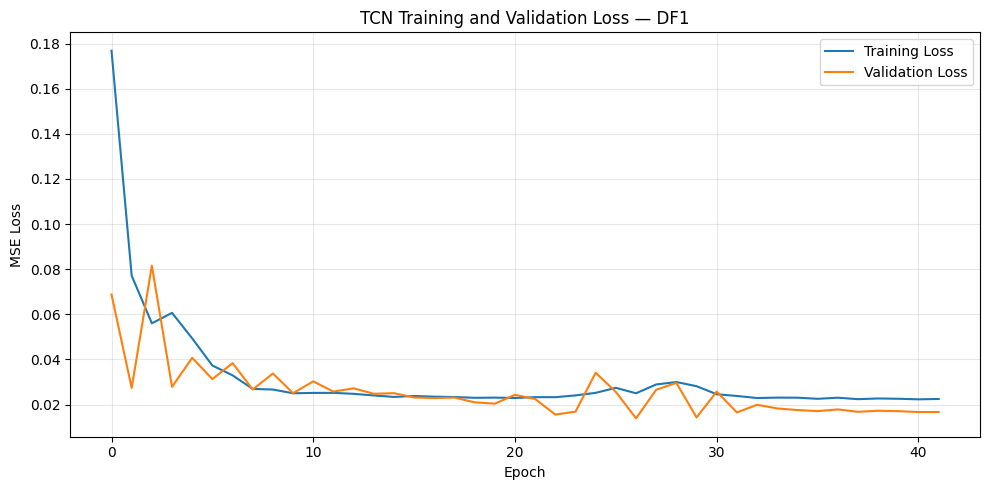

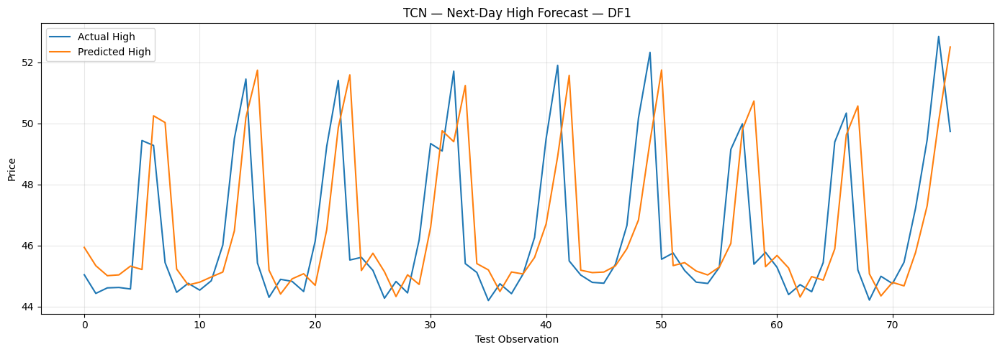

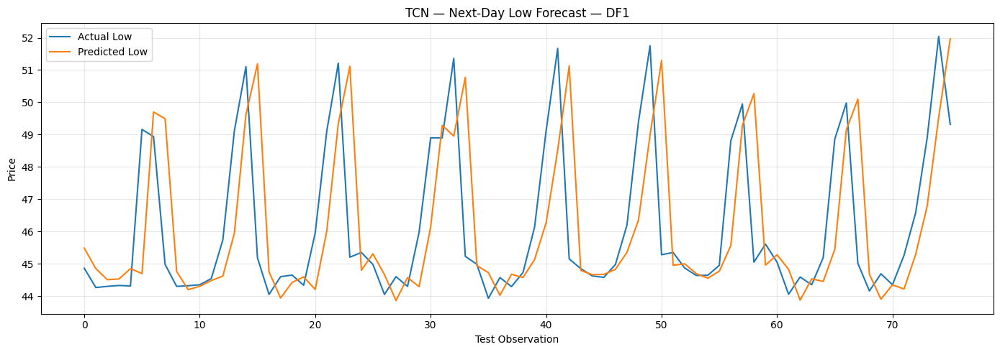



TRAINING TCN — DF2
Total observations: 821
Train observations: 574
Validation observations: 123
Test observations: 124

Sequence shapes:
X_train: (549, 25, 4)
y_train: (549, 2)
X_val: (123, 25, 4)
y_val: (123, 2)
X_test: (124, 25, 4)
y_test: (124, 2)

Model architecture:


Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_31      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 25, 64)    │        832 │ input_layer_31[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_68          │ (None, 25, 64)    │          0 │ conv1d_9[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_68[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_69          │ (None, 25, 64)    │          0 │ conv1d_10[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_31[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 25, 64)    │          0 │ dropout_69[0][0], │
│                     │                   │            │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 25, 64)    │          0 │ add_4[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_70          │ (None, 25, 64)    │          0 │ conv1d_12[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_70[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_71          │ (None, 25, 64)    │          0 │ conv1d_13[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 25, 64)    │          0 │ dropout_71[0][0], │
│                     │                   │            │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 25, 64)    │          0 │ add_5[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_72          │ (None, 25, 64)    │          0 │ conv1d_14[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_72[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_73          │ (None, 25, 64)    │          0 │ conv1d_15[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 25, 64)    │          0 │ dropout_73[0][0], │
│                     │                   │            │ activation_5[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0592 - mae: 0.1708 - val_loss: 0.0257 - val_mae: 0.1230 - learning_rate: 0.0010
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0543 - mae: 0.1865 - val_loss: 0.0489 - val_mae: 0.2024 - learning_rate: 0.0010
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0693 - mae: 0.2123 - val_loss: 0.0260 - val_mae: 0.1280 - learning_rate: 0.0010
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0521 - mae: 0.1816 - val_loss: 0.0237 - val_mae: 0.1155 - learning_rate: 0.0010
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0393 - mae: 0.1555 - val_loss: 0.0230 - val_mae: 0.1061 - learning_rate: 0.0010
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0312 - mae: 0.1345 - val_loss: 0.0238 - val_mae: 0.1156 - learning_rate: 0.0010
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0262 - mae: 0.1213 - val_loss: 0.0240 - val_mae: 0.1165 - learning_rate: 0.0010
Epoch 

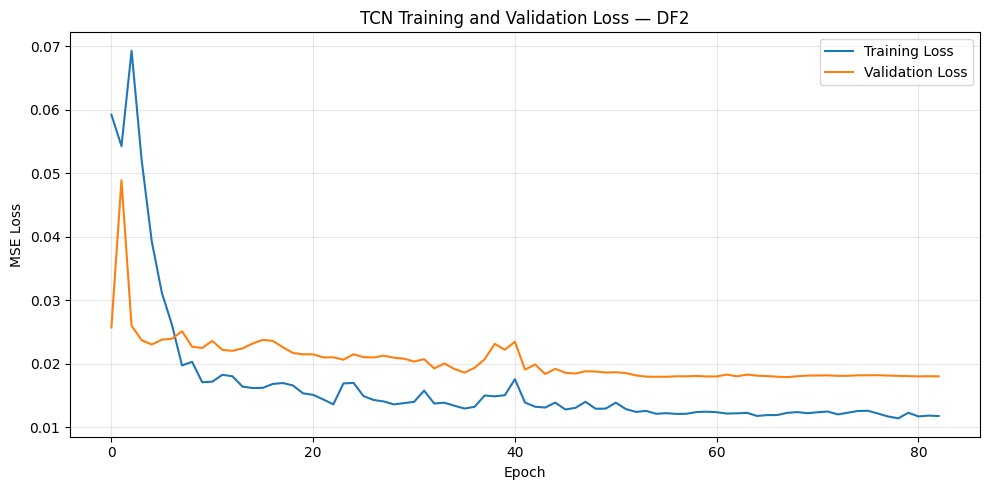

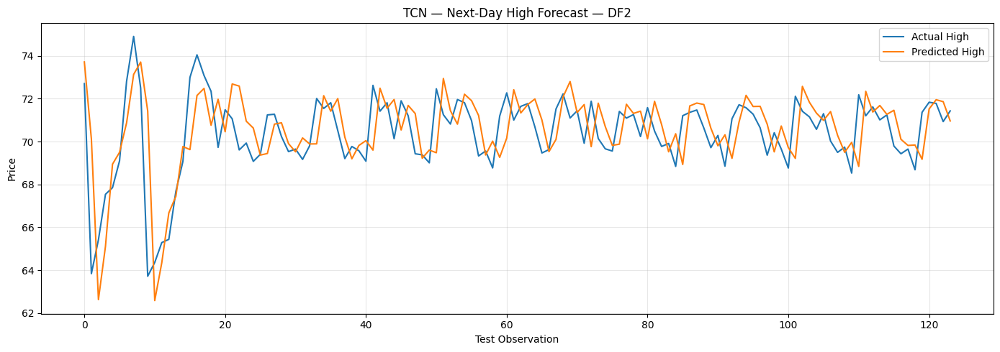

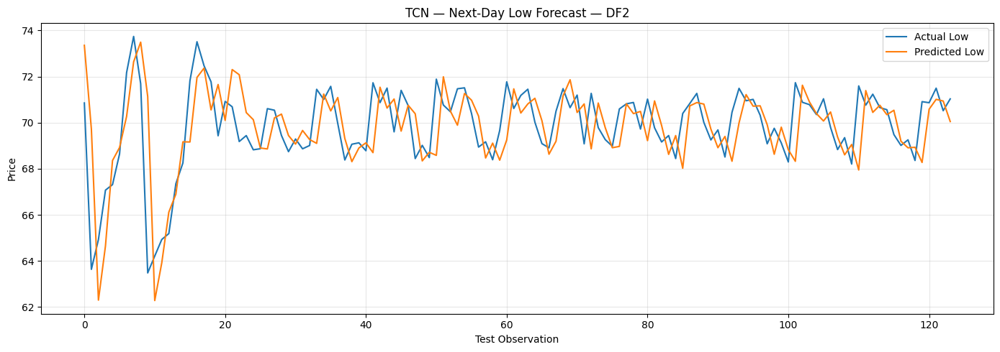



TRAINING TCN — DF3
Total observations: 308
Train observations: 215
Validation observations: 46
Test observations: 47

Sequence shapes:
X_train: (190, 25, 4)
y_train: (190, 2)
X_val: (46, 25, 4)
y_val: (46, 2)
X_test: (47, 25, 4)
y_test: (47, 2)

Model architecture:


Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_32      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_32[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_76          │ (None, 25, 64)    │          0 │ conv1d_18[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_76[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_77          │ (None, 25, 64)    │          0 │ conv1d_19[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_32[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 25, 64)    │          0 │ dropout_77[0][0], │
│                     │                   │            │ conv1d_20[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 25, 64)    │          0 │ add_8[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_78          │ (None, 25, 64)    │          0 │ conv1d_21[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_78[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_79          │ (None, 25, 64)    │          0 │ conv1d_22[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 25, 64)    │          0 │ dropout_79[0][0], │
│                     │                   │            │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 25, 64)    │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_80          │ (None, 25, 64)    │          0 │ conv1d_23[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_80[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_81          │ (None, 25, 64)    │          0 │ conv1d_24[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 25, 64)    │          0 │ dropout_81[0][0], │
│                     │                   │            │ activation_9[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - loss: 0.3788 - mae: 0.5895 - val_loss: 0.3670 - val_mae: 0.5541 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.2946 - mae: 0.5155 - val_loss: 0.3491 - val_mae: 0.5473 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.2861 - mae: 0.5124 - val_loss: 0.3358 - val_mae: 0.5460 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2621 - mae: 0.4936 - val_loss: 0.2550 - val_mae: 0.4766 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2017 - mae: 0.4236 - val_loss: 0.1421 - val_mae: 0.3286 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0807 - mae: 0.2367 - val_loss: 0.3166 - val_mae: 0.4793 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0423 - mae: 0.1661 - val_loss: 0.1973 - val_mae: 0.3598 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

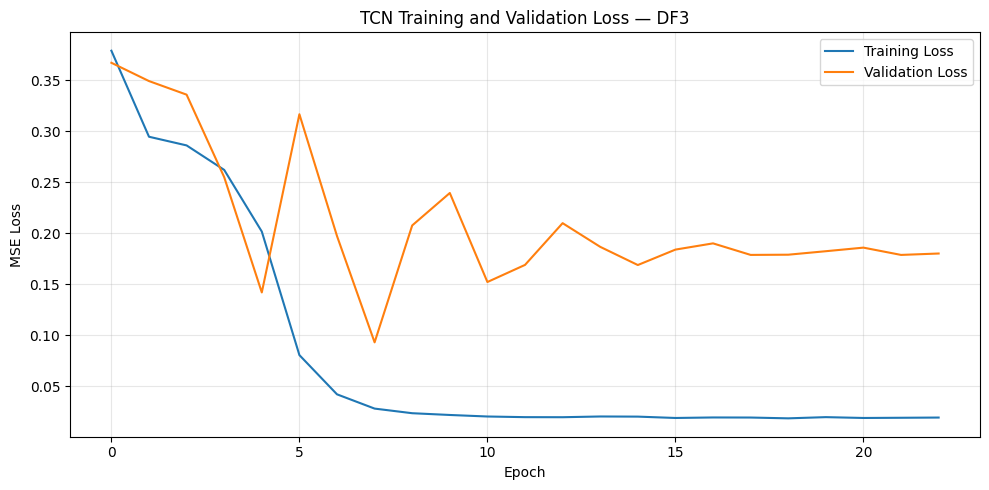

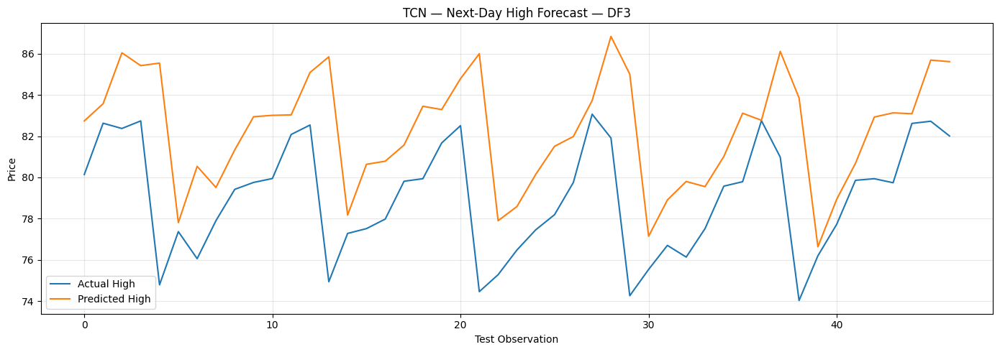

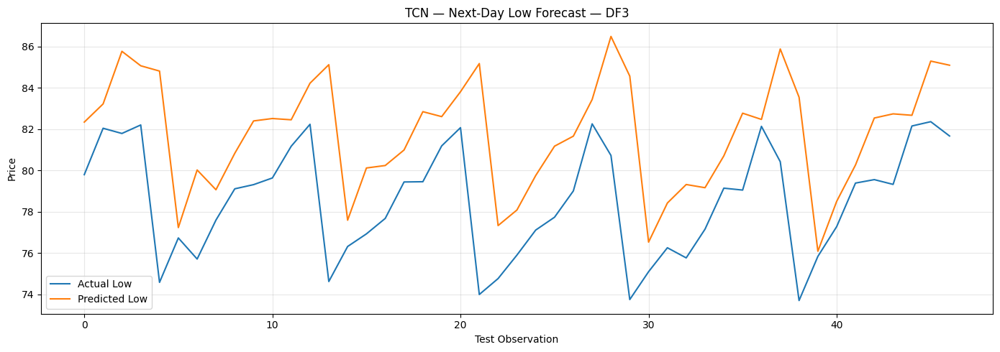



TRAINING TCN — DF4
Total observations: 295
Train observations: 206
Validation observations: 44
Test observations: 45

Sequence shapes:
X_train: (181, 25, 4)
y_train: (181, 2)
X_val: (44, 25, 4)
y_val: (44, 2)
X_test: (45, 25, 4)
y_test: (45, 2)

Model architecture:


Model: "functional_33"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_33      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_33[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_84          │ (None, 25, 64)    │          0 │ conv1d_27[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_84[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_85          │ (None, 25, 64)    │          0 │ conv1d_28[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_33[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 25, 64)    │          0 │ dropout_85[0][0], │
│                     │                   │            │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 25, 64)    │          0 │ add_12[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_86          │ (None, 25, 64)    │          0 │ conv1d_30[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_86[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_87          │ (None, 25, 64)    │          0 │ conv1d_31[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 25, 64)    │          0 │ dropout_87[0][0], │
│                     │                   │            │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 25, 64)    │          0 │ add_13[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_13[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_88          │ (None, 25, 64)    │          0 │ conv1d_32[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_88[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_89          │ (None, 25, 64)    │          0 │ conv1d_33[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 25, 64)    │          0 │ dropout_89[0][0], │
│                     │                   │            │ activation_13[0]

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 136ms/step - loss: 0.2463 - mae: 0.4286 - val_loss: 0.8132 - val_mae: 0.6467 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1042 - mae: 0.2987 - val_loss: 0.3859 - val_mae: 0.3806 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1108 - mae: 0.2957 - val_loss: 0.5728 - val_mae: 0.4966 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0667 - mae: 0.2121 - val_loss: 1.0789 - val_mae: 0.8007 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0493 - mae: 0.1727 - val_loss: 0.8540 - val_mae: 0.6818 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0370 - mae: 0.1485 - val_loss: 0.6323 - val_mae: 0.5403 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0419 - mae: 0.1629 - val_loss: 0.6221 - val_mae: 0.5300 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

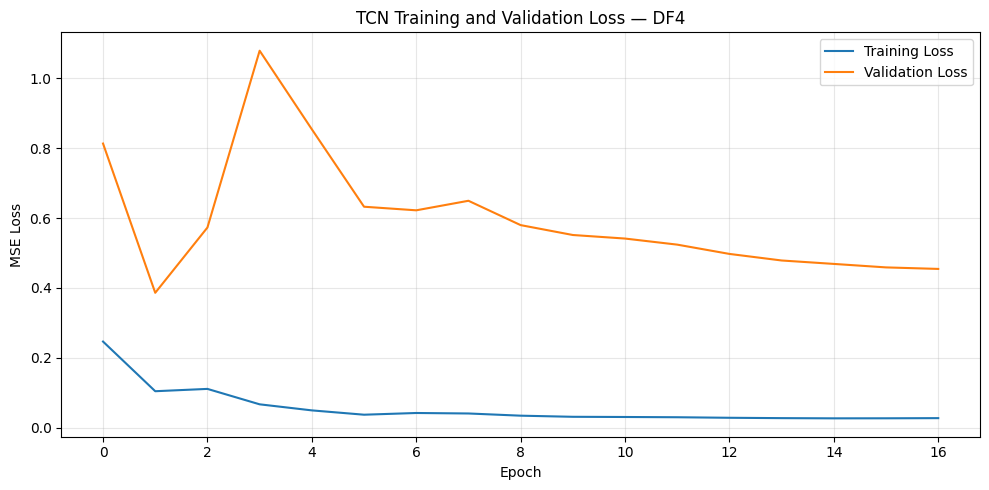

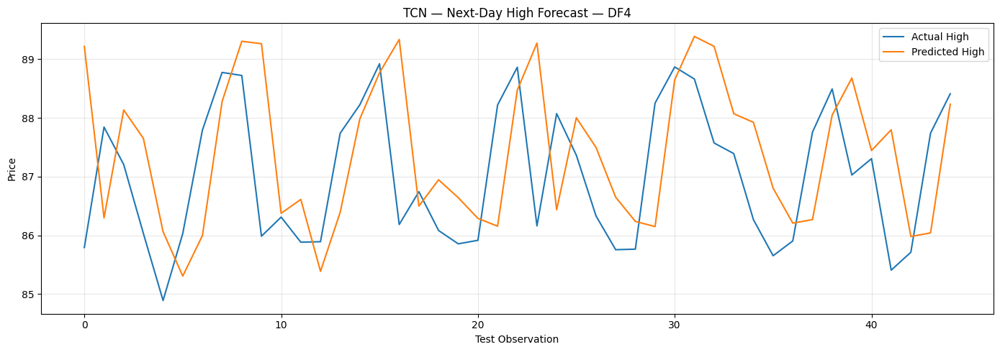

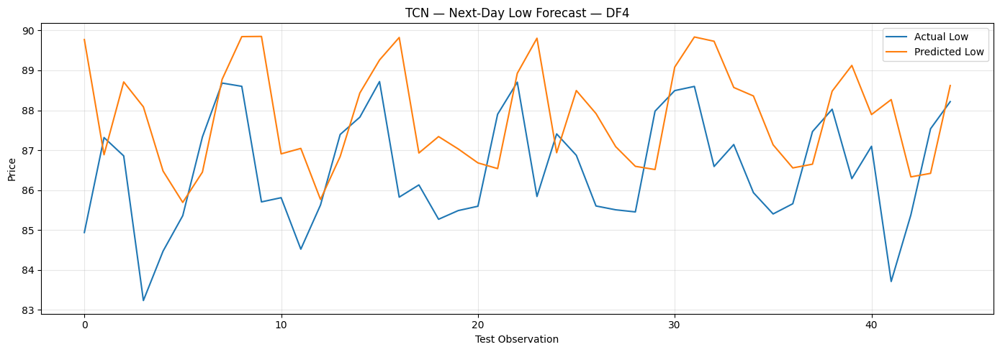



FINAL TCN RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,1.562886,2.342676,0.059807,3.315423,1.519571,2.300353,0.037586,3.236901,42
1,DF2,1.207778,1.615818,0.209326,1.729811,1.133740,1.573963,0.186041,1.634600,83
2,DF3,3.225455,4.302976,-1.502754,4.154432,3.231922,4.269186,-1.550765,4.183596,23
3,DF4,1.135561,1.444100,-0.541147,1.308448,1.624874,2.081286,-1.231634,1.893752,17



Results saved as: TCN_baseline_results.csv
Predictions saved as: TCN_baseline_predictions.xlsx


In [55]:
# ============================================================
# TCN BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dropout,
    Dense,
    Add,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED TCN HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

TCN_FILTERS = 64
KERNEL_SIZE = 3
DILATIONS = [1, 2, 4, 8]

DROPOUT = 0.20
DENSE_UNITS = 16

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

EARLY_STOPPING_PATIENCE = 15
LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. DATA PREPARATION
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure numeric OHLC
for col in FEATURES:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {
    "DF1": ("2007-01-01", "2011-12-31"),
    "DF2": ("2012-01-01", "2019-12-31"),
    "DF3": ("2020-01-01", "2022-12-31"),
    "DF4": ("2023-01-01", None)
}


# ============================================================
# 7. TARGET CREATION
# ============================================================
#
# Predict:
#
#   Next-Day High / Current Close
#   Next-Day Low  / Current Close
#
# Absolute prediction is reconstructed later:
#
#   Predicted High = Predicted Ratio × Current Close
#   Predicted Low  = Predicted Ratio × Current Close
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1) /
    data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1) /
    data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. SEQUENCE CREATION FUNCTION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):
    """
    Creates sequences for the training partition.

    X[i-lookback:i] -> y[i]
    """

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):
    """
    Creates validation/test sequences while allowing
    the first observations to use historical information.

    This avoids losing the first LOOKBACK observations
    of validation/test.
    """

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[i:i + lookback]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. TCN RESIDUAL BLOCK
# ============================================================

def tcn_residual_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate
):

    residual = x

    # First causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Second causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation=None
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Match residual dimensions if necessary
    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    # Residual connection
    x = Add()(
        [
            x,
            residual
        ]
    )

    x = Activation(
        "relu"
    )(x)

    return x


# ============================================================
# 11. BUILD TCN MODEL
# ============================================================

def build_tcn_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    x = inputs

    # --------------------------------------------
    # Dilated TCN blocks
    # --------------------------------------------

    for dilation in DILATIONS:

        x = tcn_residual_block(
            x=x,
            filters=TCN_FILTERS,
            kernel_size=KERNEL_SIZE,
            dilation_rate=dilation,
            dropout_rate=DROPOUT
        )

    # --------------------------------------------
    # Sequence → fixed representation
    # --------------------------------------------

    x = GlobalAveragePooling1D()(x)

    # --------------------------------------------
    # Dense forecasting head
    # --------------------------------------------

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred) /
            denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []
all_predictions = {}
all_histories = {}
all_models = {}


# ============================================================
# 14. REGIME-WISE TRAINING
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 70)
    print(f"TRAINING TCN — {regime_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Filter regime
    # --------------------------------------------------------

    regime_data = data[
        data["Date"] >= pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )

    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )

    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # Extract features and targets
    # --------------------------------------------------------

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # --------------------------------------------------------
    # 70 / 15 / 15 chronological split
    # --------------------------------------------------------

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )

    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]

    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]

    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. SCALE TARGETS USING TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. CREATE TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = create_train_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK
    )


    # ========================================================
    # 18. CREATE VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = create_partition_sequences(
        history_X=X_train_scaled[-LOOKBACK:],
        partition_X=X_val_scaled,
        partition_y=y_val_scaled,
        lookback=LOOKBACK
    )


    # ========================================================
    # 19. CREATE TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = create_partition_sequences(
        history_X=X_val_scaled[-LOOKBACK:],
        partition_X=X_test_scaled,
        partition_y=y_test_scaled,
        lookback=LOOKBACK
    )


    print(
        "\nSequence shapes:"
    )

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_tcn_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(
        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,
        verbose=1
    )


    # ========================================================
    # 23. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TRANSFORM TARGET RATIOS
    # ========================================================

    y_pred_ratio = y_scaler.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = y_scaler.inverse_transform(
        y_test_seq
    )


    # ========================================================
    # 25. CURRENT CLOSE FOR EACH TEST TARGET
    # ========================================================
    #
    # Since validation/test sequences preserve the
    # partition ordering, the target-day current close
    # corresponds to X_test_raw / X_val_raw etc.
    #
    # Target is:
    #
    # High(t+1) / Close(t)
    #
    # Therefore use Close(t) to reconstruct.
    # ========================================================

    current_close_test = X_test_raw[
        :, FEATURES.index("Close")
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0] *
        current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1] *
        current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0] *
        current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1] *
        current_close_test
    )


    # ========================================================
    # 27. CALCULATE METRICS — HIGH
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = (
        calculate_metrics(
            actual_high,
            predicted_high
        )
    )


    # ========================================================
    # 28. CALCULATE METRICS — LOW
    # ========================================================

    low_mae, low_rmse, low_r2, low_mape = (
        calculate_metrics(
            actual_low,
            predicted_low
        )
    )


    # ========================================================
    # 29. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 70)
    print(f"TCN RESULTS — {regime_name}")
    print("=" * 70)

    print("\nNEXT-DAY HIGH")
    print(
        f"MAE  : {high_mae:.6f}"
    )
    print(
        f"RMSE : {high_rmse:.6f}"
    )
    print(
        f"R²   : {high_r2:.6f}"
    )
    print(
        f"MAPE : {high_mape:.6f}%"
    )

    print("\nNEXT-DAY LOW")
    print(
        f"MAE  : {low_mae:.6f}"
    )
    print(
        f"RMSE : {low_rmse:.6f}"
    )
    print(
        f"R²   : {low_r2:.6f}"
    )
    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Best_Epoch":
            len(history.history["loss"])

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Current_Close":
            current_close_test

    })

    all_predictions[
        regime_name
    ] = prediction_df

    all_histories[
        regime_name
    ] = history.history

    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. PLOT TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"TCN Training and Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. PLOT HIGH PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"TCN — Next-Day High Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. PLOT LOW PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"TCN — Next-Day Low Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 90)
print("FINAL TCN RESULTS")
print("=" * 90)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "TCN_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " TCN_baseline_results.csv"
)


# ============================================================
# 37. SAVE ALL PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "TCN_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in all_predictions.items():

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved as:"
    " TCN_baseline_predictions.xlsx"
)



Conv1D-LSTM TRAINING — DF1
Total observations: 504
Train: 352
Validation: 76
Test: 76

Sequence shapes:
X_train: (327, 25, 4)
y_train: (327, 2)
X_val: (76, 25, 4)
y_val: (76, 2)
X_test: (76, 25, 4)
y_test: (76, 2)

Model architecture:


Model: "functional_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_34 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_36 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_92 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_37 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_93 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_60 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_94 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_61 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_95 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_69 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - loss: 0.0962 - mae: 0.2330 - val_loss: 0.2394 - val_mae: 0.4758 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0355 - mae: 0.1378 - val_loss: 0.2196 - val_mae: 0.4552 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0355 - mae: 0.1396 - val_loss: 0.2022 - val_mae: 0.4356 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0301 - mae: 0.1270 - val_loss: 0.1697 - val_mae: 0.3965 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0276 - mae: 0.1230 - val_loss: 0.1586 - val_mae: 0.3824 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0278 - mae: 0.1220 - val_loss: 0.1331 - val_mae: 0.3482 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0249 - mae: 0.1185 - val_loss: 0.1066 - val_mae: 0.3096 - learning_rate: 0.0010
Epoch 

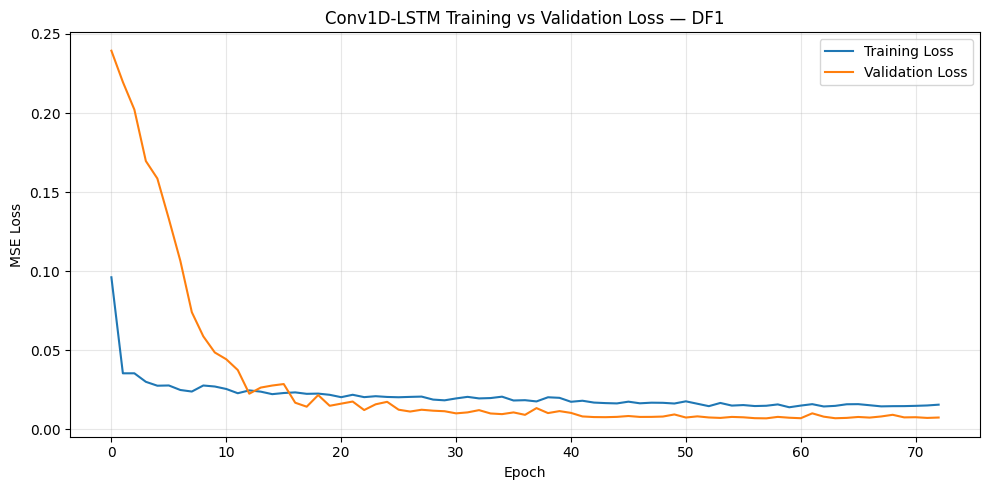

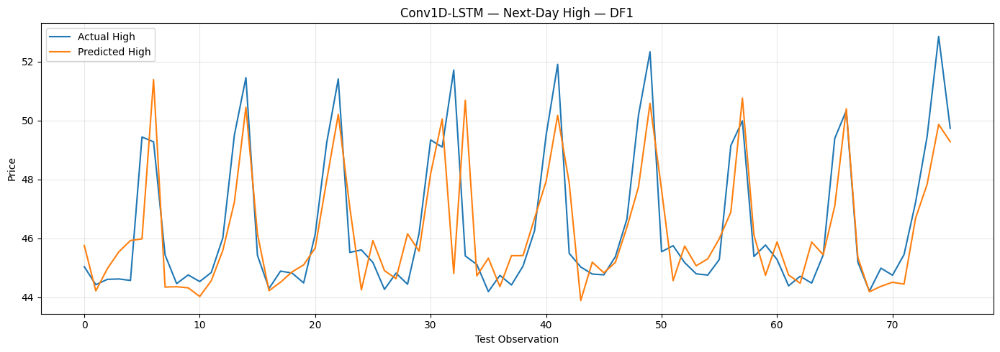

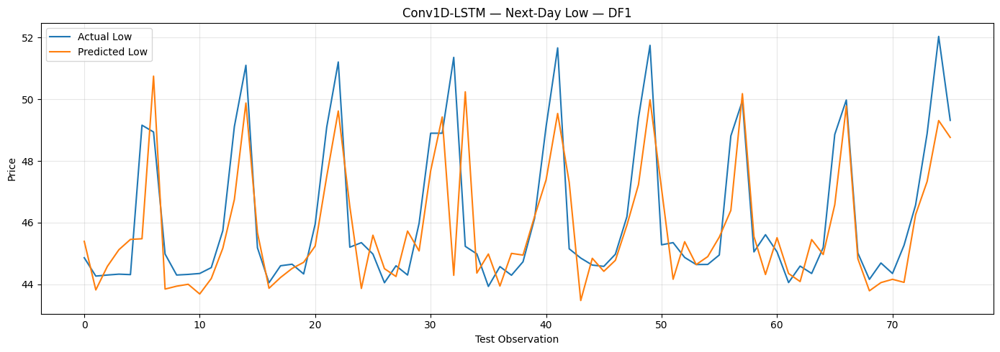



Conv1D-LSTM TRAINING — DF2
Total observations: 821
Train: 574
Validation: 123
Test: 124

Sequence shapes:
X_train: (549, 25, 4)
y_train: (549, 2)
X_val: (123, 25, 4)
y_val: (123, 2)
X_test: (124, 25, 4)
y_test: (124, 2)

Model architecture:


Model: "functional_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_35 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_38 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_96 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_39 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_97 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_62 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_98 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_63 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_99 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_70 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: 0.0650 - mae: 0.1936 - val_loss: 0.1324 - val_mae: 0.3429 - learning_rate: 0.0010
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0258 - mae: 0.1205 - val_loss: 0.1194 - val_mae: 0.3272 - learning_rate: 0.0010
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0235 - mae: 0.1163 - val_loss: 0.1087 - val_mae: 0.3120 - learning_rate: 0.0010
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0218 - mae: 0.1126 - val_loss: 0.0956 - val_mae: 0.2924 - learning_rate: 0.0010
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0224 - mae: 0.1150 - val_loss: 0.0828 - val_mae: 0.2714 - learning_rate: 0.0010
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0192 - mae: 0.1043 - val_loss: 0.0715 - val_mae: 0.2508 - learning_rate: 0.0010
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0178 - mae: 0.1015 - val_loss: 0.0493 - val_mae: 0.2038 - learning_rate: 0.0010
Epoch 

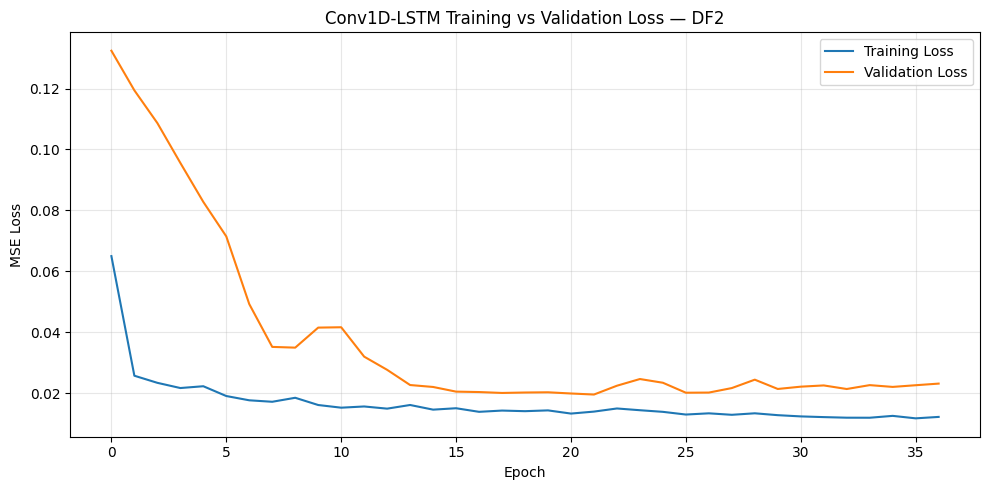

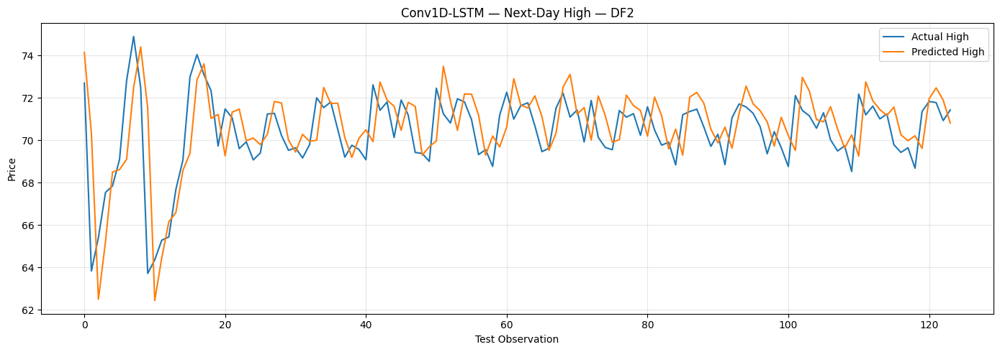

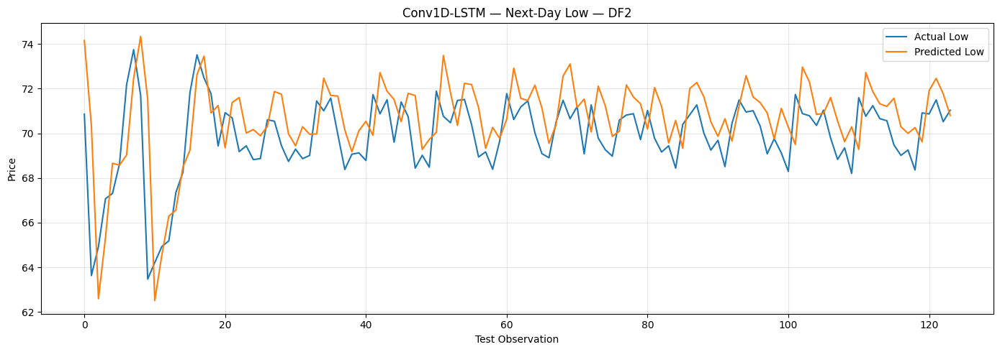



Conv1D-LSTM TRAINING — DF3
Total observations: 308
Train: 215
Validation: 46
Test: 47

Sequence shapes:
X_train: (190, 25, 4)
y_train: (190, 2)
X_val: (46, 25, 4)
y_val: (46, 2)
X_test: (47, 25, 4)
y_test: (47, 2)

Model architecture:


Model: "functional_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_36 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_40 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_100 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_41 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_101 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_102 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_65 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_103 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_72 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 190ms/step - loss: 0.0875 - mae: 0.2262 - val_loss: 0.1190 - val_mae: 0.3320 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0474 - mae: 0.1709 - val_loss: 0.1430 - val_mae: 0.3694 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0359 - mae: 0.1490 - val_loss: 0.1286 - val_mae: 0.3478 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0272 - mae: 0.1327 - val_loss: 0.1104 - val_mae: 0.3196 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0252 - mae: 0.1249 - val_loss: 0.1074 - val_mae: 0.3162 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0252 - mae: 0.1254 - val_loss: 0.1050 - val_mae: 0.3121 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0246 - mae: 0.1244 - val_loss: 0.0959 - val_mae: 0.2942 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

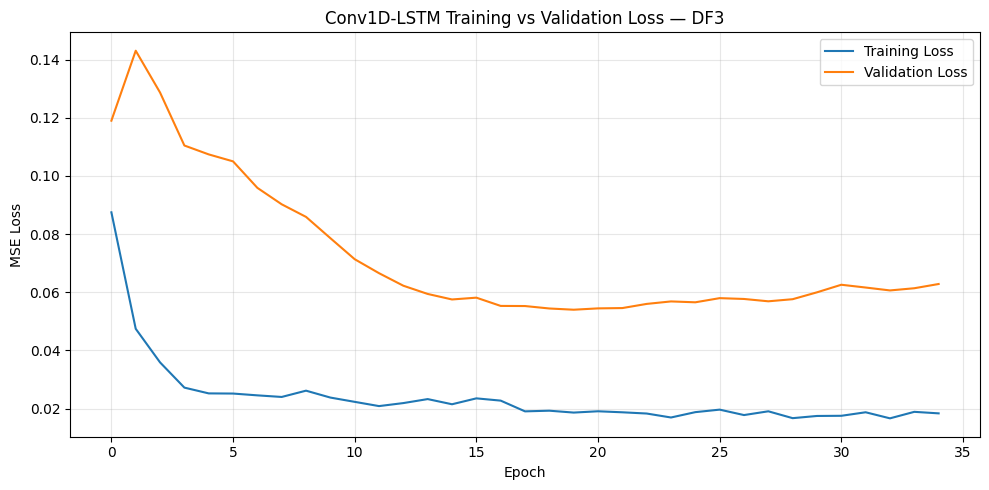

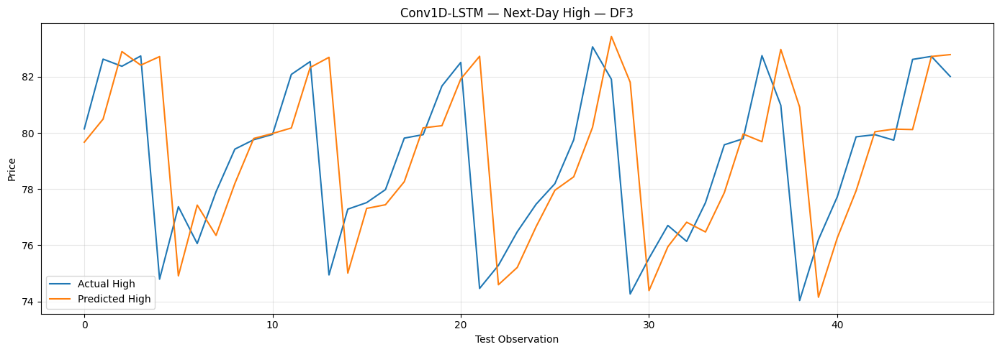

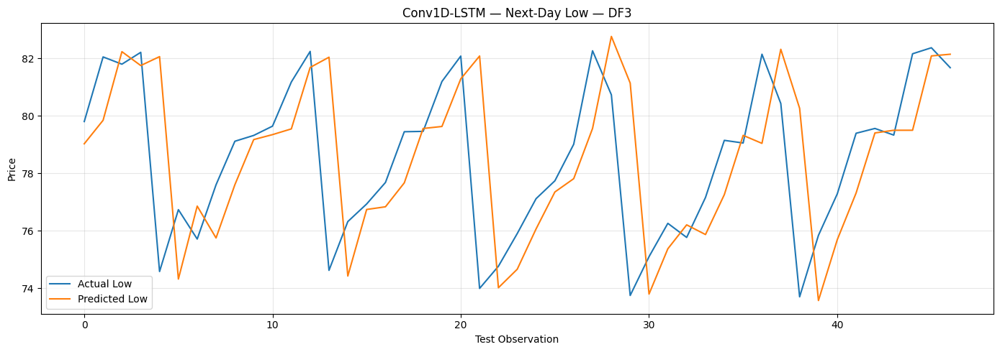



Conv1D-LSTM TRAINING — DF4
Total observations: 295
Train: 206
Validation: 44
Test: 45

Sequence shapes:
X_train: (181, 25, 4)
y_train: (181, 2)
X_val: (44, 25, 4)
y_val: (44, 2)
X_test: (45, 25, 4)
y_test: (45, 2)

Model architecture:


Model: "functional_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_37 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_42 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_22 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_104 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_43 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_23 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_105 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_66 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_106 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_67 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_107 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_74 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 154ms/step - loss: 0.3150 - mae: 0.5012 - val_loss: 0.3805 - val_mae: 0.4501 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0645 - mae: 0.2038 - val_loss: 0.3338 - val_mae: 0.3623 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0500 - mae: 0.1742 - val_loss: 0.3452 - val_mae: 0.3867 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0460 - mae: 0.1639 - val_loss: 0.3371 - val_mae: 0.3577 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0467 - mae: 0.1702 - val_loss: 0.3333 - val_mae: 0.3592 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0372 - mae: 0.1501 - val_loss: 0.3326 - val_mae: 0.3665 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0379 - mae: 0.1522 - val_loss: 0.3311 - val_mae: 0.3618 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

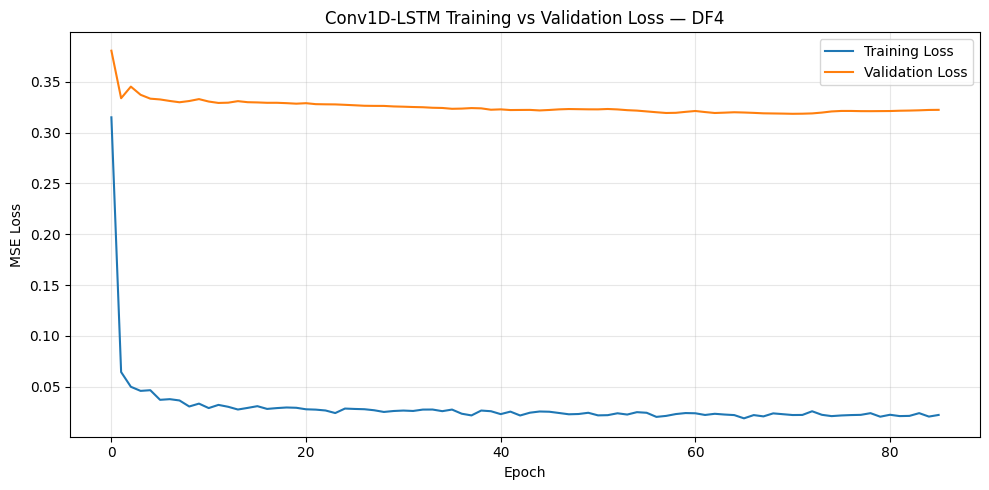

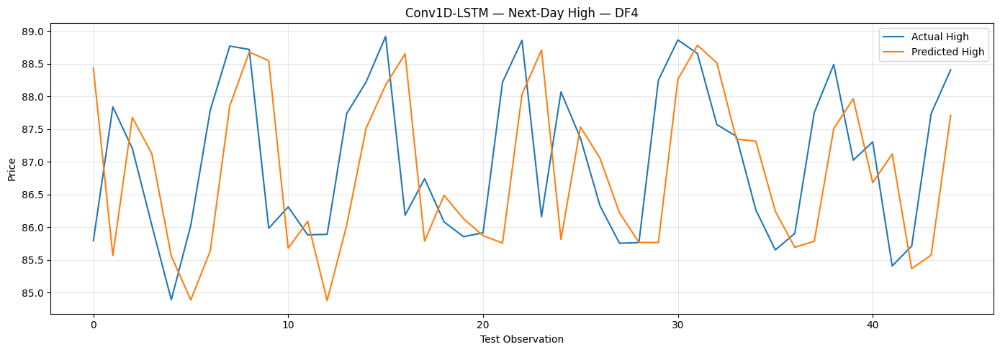

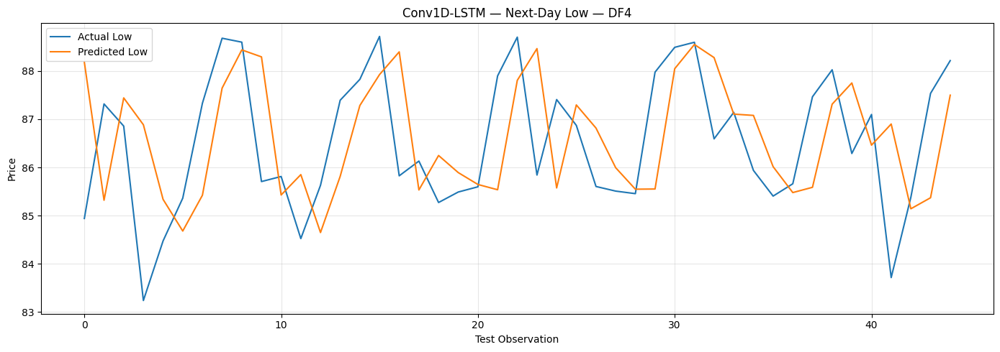



FINAL Conv1D-LSTM BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,1.045256,1.532626,0.597594,2.196978,1.033966,1.523669,0.577765,2.184131,73
1,DF2,1.254682,1.652298,0.173221,1.796406,1.401722,1.777974,-0.038638,2.023697,37
2,DF3,1.827648,2.836044,-0.087192,2.365340,1.864337,2.779654,-0.081339,2.423150,35
3,DF4,1.068334,1.353543,-0.353924,1.226874,1.209948,1.538113,-0.218809,1.403604,86



Results saved as: Conv1D_LSTM_baseline_results.csv
Predictions saved as: Conv1D_LSTM_baseline_predictions.xlsx


In [56]:
# ============================================================
# Conv1D-LSTM BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    Dropout,
    LSTM,
    Dense
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# CNN
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Regularization
DROPOUT = 0.20

# LSTM
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Dense
DENSE_UNITS = 16

# Training
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. INPUT FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure OHLC are numeric
for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2011-12-31"
    ),

    "DF2": (
        "2012-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2022-12-31"
    ),

    "DF4": (
        "2023-01-01",
        None
    )
}


# ============================================================
# 7. CREATE NORMALIZED TARGETS
# ============================================================
#
# Predict:
#
#     High(t+1) / Close(t)
#     Low(t+1)  / Close(t)
#
# Then reconstruct:
#
#     Predicted High =
#         Predicted Ratio × Close(t)
#
#     Predicted Low =
#         Predicted Ratio × Close(t)
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE CREATION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. BUILD IMPROVED Conv1D-LSTM MODEL
# ============================================================

def build_conv1d_lstm_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    # ========================================================
    # CNN FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CNN LAYER
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # LSTM TEMPORAL MODELING
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND LSTM
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # DENSE FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # CREATE MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 11. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 12. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 13. TRAIN EACH MARKET REGIME
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM TRAINING — {regime_name}"
    )
    print("=" * 75)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # FEATURES / TARGETS
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # CHRONOLOGICAL 70 / 15 / 15 SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 14. SCALE INPUTS — TRAIN ONLY
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 15. SCALE TARGETS — TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 16. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 17. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 18. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 19. BUILD MODEL
    # ========================================================

    model = build_conv1d_lstm_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 20. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 21. TRAIN
    # ========================================================

    history = model.fit(

        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 22. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 23. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 24. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 25. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 26. HIGH METRICS
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 27. LOW METRICS
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 28. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM RESULTS — {regime_name}"
    )
    print("=" * 75)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 29. STORE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )
    })


    # ========================================================
    # 30. STORE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 31. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"Conv1D-LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 32. HIGH PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. LOW PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 34. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 95)
print("FINAL Conv1D-LSTM BASELINE RESULTS")
print("=" * 95)

display(
    results_df.round(6)
)


# ============================================================
# 35. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "Conv1D_LSTM_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " Conv1D_LSTM_baseline_results.csv"
)


# ============================================================
# 36. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "Conv1D_LSTM_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )


print(
    "Predictions saved as:"
    " Conv1D_LSTM_baseline_predictions.xlsx"
)



TRAINING TCN — DF1
Total observations: 504
Train observations: 352
Validation observations: 76
Test observations: 76

Sequence shapes:
X_train: (327, 25, 4)
y_train: (327, 2)
X_val: (76, 25, 4)
y_val: (76, 2)
X_test: (76, 25, 4)
y_test: (76, 2)

Model architecture:


Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_30      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 25, 64)    │        832 │ input_layer_30[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_60          │ (None, 25, 64)    │          0 │ conv1d[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_60[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_61          │ (None, 25, 64)    │          0 │ conv1d_1[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 25, 64)    │        320 │ input_layer_30[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 25, 64)    │          0 │ dropout_61[0][0], │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 25, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_62          │ (None, 25, 64)    │          0 │ conv1d_3[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_62[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_63          │ (None, 25, 64)    │          0 │ conv1d_4[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 25, 64)    │          0 │ dropout_63[0][0], │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 25, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_64          │ (None, 25, 64)    │          0 │ conv1d_5[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_64[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_65          │ (None, 25, 64)    │          0 │ conv1d_6[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 25, 64)    │          0 │ dropout_65[0][0], │
│                     │                   │            │ activation_1[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.1768 - mae: 0.3631 - val_loss: 0.0688 - val_mae: 0.2411 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0771 - mae: 0.2284 - val_loss: 0.0274 - val_mae: 0.1416 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0560 - mae: 0.1737 - val_loss: 0.0815 - val_mae: 0.2677 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0606 - mae: 0.2025 - val_loss: 0.0278 - val_mae: 0.1435 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0493 - mae: 0.1678 - val_loss: 0.0407 - val_mae: 0.1787 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0373 - mae: 0.1504 - val_loss: 0.0313 - val_mae: 0.1544 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0330 - mae: 0.1239 - val_loss: 0.0384 - val_mae: 0.1725 - learning_rate: 0.0010
Epoch 

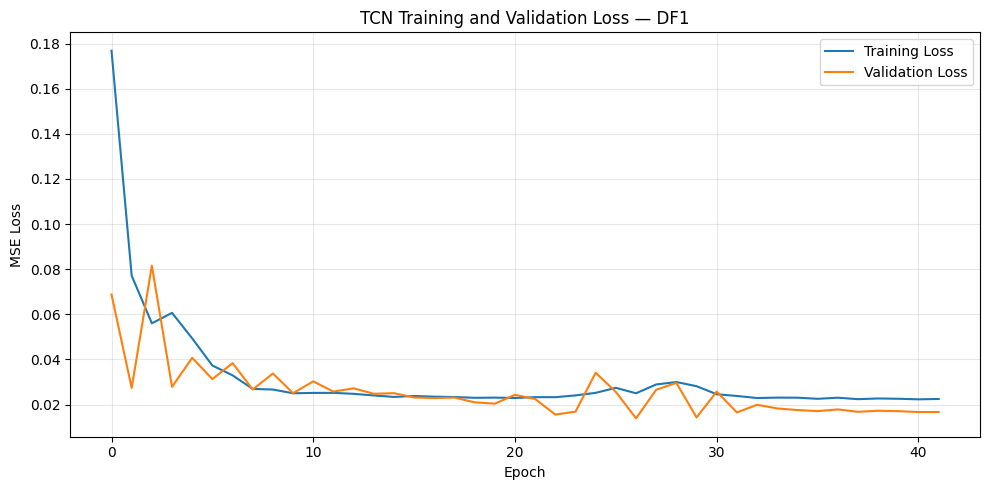

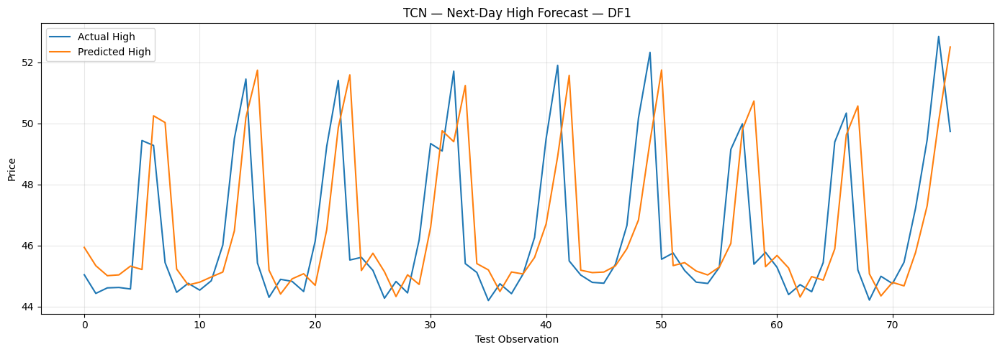

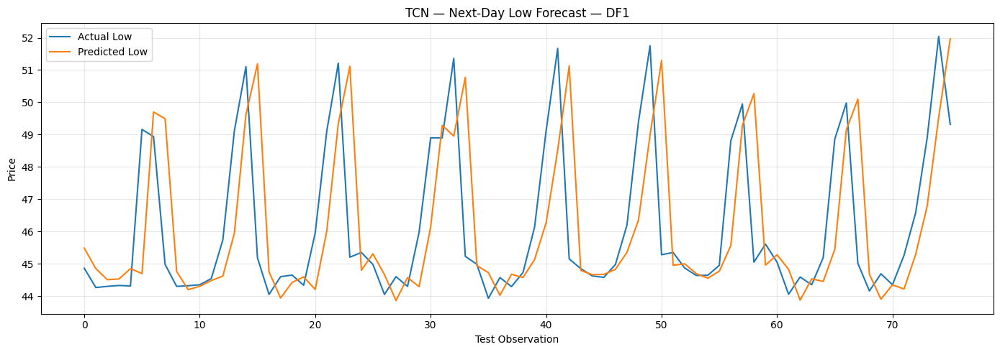



TRAINING TCN — DF2
Total observations: 821
Train observations: 574
Validation observations: 123
Test observations: 124

Sequence shapes:
X_train: (549, 25, 4)
y_train: (549, 2)
X_val: (123, 25, 4)
y_val: (123, 2)
X_test: (124, 25, 4)
y_test: (124, 2)

Model architecture:


Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_31      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 25, 64)    │        832 │ input_layer_31[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_68          │ (None, 25, 64)    │          0 │ conv1d_9[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_68[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_69          │ (None, 25, 64)    │          0 │ conv1d_10[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_31[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 25, 64)    │          0 │ dropout_69[0][0], │
│                     │                   │            │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 25, 64)    │          0 │ add_4[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_70          │ (None, 25, 64)    │          0 │ conv1d_12[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_70[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_71          │ (None, 25, 64)    │          0 │ conv1d_13[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 25, 64)    │          0 │ dropout_71[0][0], │
│                     │                   │            │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 25, 64)    │          0 │ add_5[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_72          │ (None, 25, 64)    │          0 │ conv1d_14[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_72[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_73          │ (None, 25, 64)    │          0 │ conv1d_15[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 25, 64)    │          0 │ dropout_73[0][0], │
│                     │                   │            │ activation_5[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0592 - mae: 0.1708 - val_loss: 0.0257 - val_mae: 0.1230 - learning_rate: 0.0010
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0543 - mae: 0.1865 - val_loss: 0.0489 - val_mae: 0.2024 - learning_rate: 0.0010
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0693 - mae: 0.2123 - val_loss: 0.0260 - val_mae: 0.1280 - learning_rate: 0.0010
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0521 - mae: 0.1816 - val_loss: 0.0237 - val_mae: 0.1155 - learning_rate: 0.0010
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0393 - mae: 0.1555 - val_loss: 0.0230 - val_mae: 0.1061 - learning_rate: 0.0010
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0312 - mae: 0.1345 - val_loss: 0.0238 - val_mae: 0.1156 - learning_rate: 0.0010
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0262 - mae: 0.1213 - val_loss: 0.0240 - val_mae: 0.1165 - learning_rate: 0.0010
Epoch 

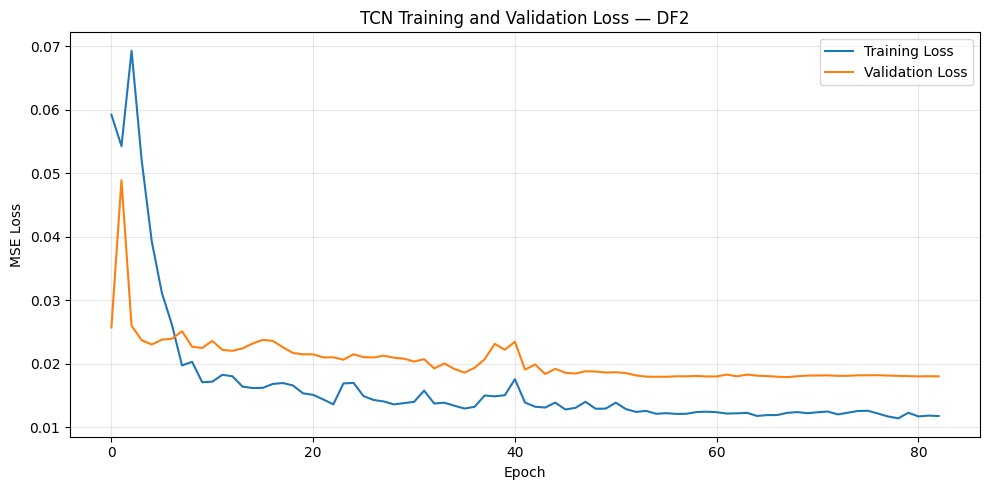

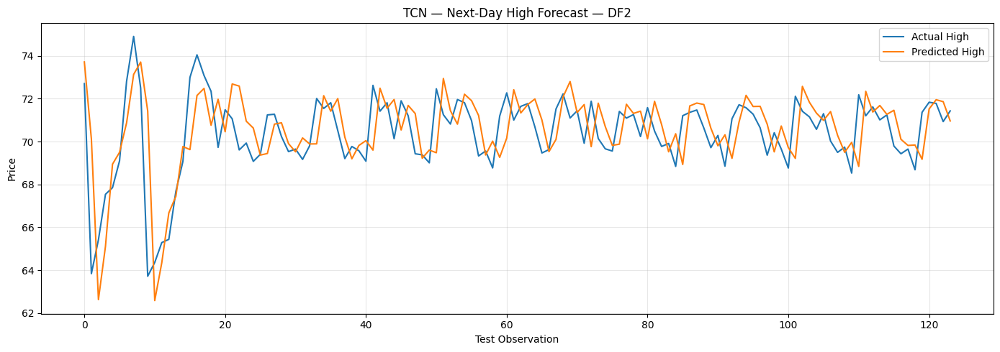

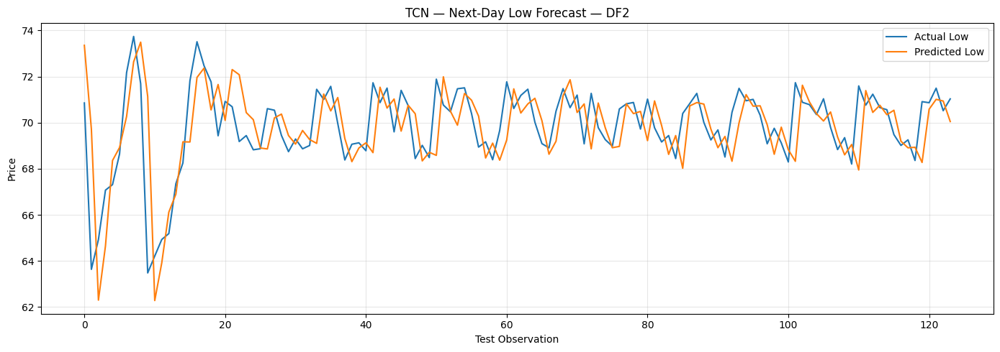



TRAINING TCN — DF3
Total observations: 308
Train observations: 215
Validation observations: 46
Test observations: 47

Sequence shapes:
X_train: (190, 25, 4)
y_train: (190, 2)
X_val: (46, 25, 4)
y_val: (46, 2)
X_test: (47, 25, 4)
y_test: (47, 2)

Model architecture:


Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_32      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_32[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_76          │ (None, 25, 64)    │          0 │ conv1d_18[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_76[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_77          │ (None, 25, 64)    │          0 │ conv1d_19[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_32[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 25, 64)    │          0 │ dropout_77[0][0], │
│                     │                   │            │ conv1d_20[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 25, 64)    │          0 │ add_8[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_78          │ (None, 25, 64)    │          0 │ conv1d_21[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_78[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_79          │ (None, 25, 64)    │          0 │ conv1d_22[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 25, 64)    │          0 │ dropout_79[0][0], │
│                     │                   │            │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 25, 64)    │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_80          │ (None, 25, 64)    │          0 │ conv1d_23[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_80[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_81          │ (None, 25, 64)    │          0 │ conv1d_24[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 25, 64)    │          0 │ dropout_81[0][0], │
│                     │                   │            │ activation_9[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - loss: 0.3788 - mae: 0.5895 - val_loss: 0.3670 - val_mae: 0.5541 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.2946 - mae: 0.5155 - val_loss: 0.3491 - val_mae: 0.5473 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.2861 - mae: 0.5124 - val_loss: 0.3358 - val_mae: 0.5460 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2621 - mae: 0.4936 - val_loss: 0.2550 - val_mae: 0.4766 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2017 - mae: 0.4236 - val_loss: 0.1421 - val_mae: 0.3286 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0807 - mae: 0.2367 - val_loss: 0.3166 - val_mae: 0.4793 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0423 - mae: 0.1661 - val_loss: 0.1973 - val_mae: 0.3598 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

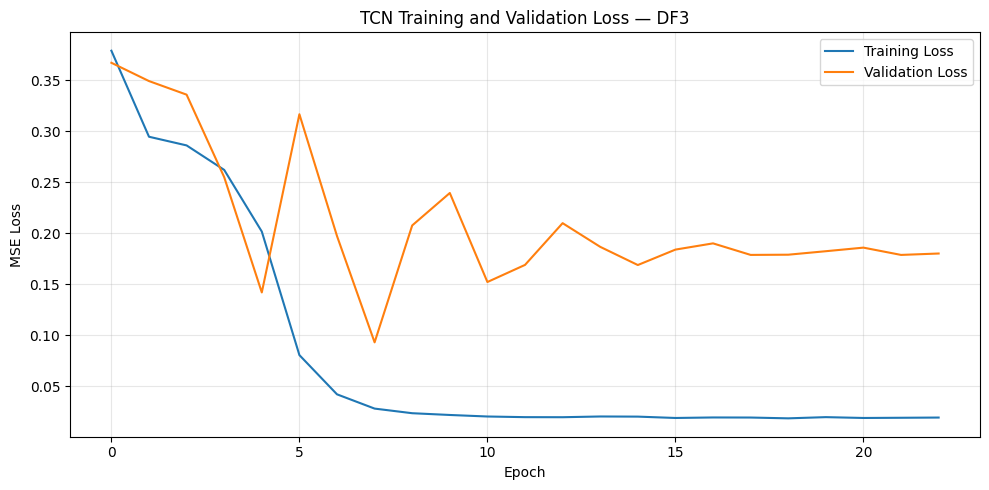

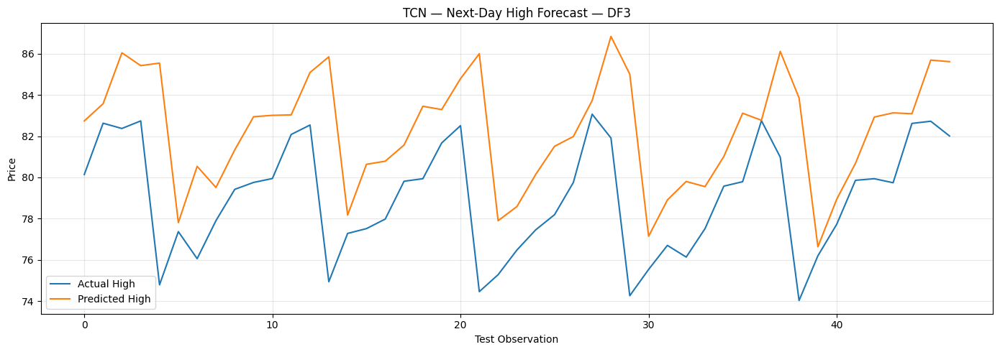

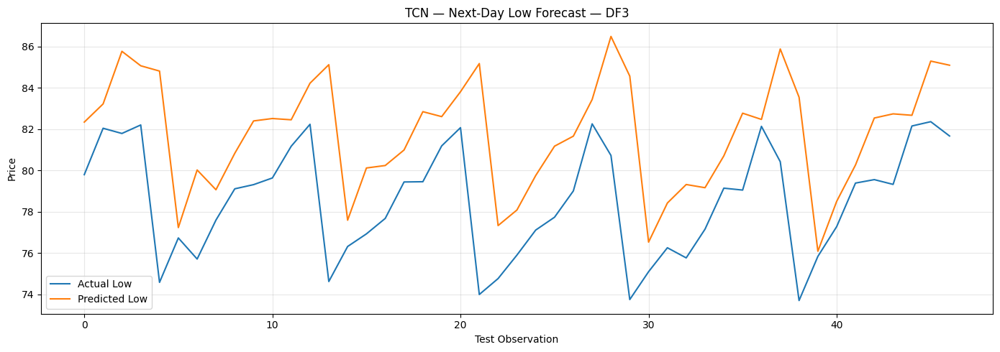



TRAINING TCN — DF4
Total observations: 295
Train observations: 206
Validation observations: 44
Test observations: 45

Sequence shapes:
X_train: (181, 25, 4)
y_train: (181, 2)
X_val: (44, 25, 4)
y_val: (44, 2)
X_test: (45, 25, 4)
y_test: (45, 2)

Model architecture:


Model: "functional_33"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_33      │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_33[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_84          │ (None, 25, 64)    │          0 │ conv1d_27[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_84[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_85          │ (None, 25, 64)    │          0 │ conv1d_28[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_33[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 25, 64)    │          0 │ dropout_85[0][0], │
│                     │                   │            │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 25, 64)    │          0 │ add_12[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_86          │ (None, 25, 64)    │          0 │ conv1d_30[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_86[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_87          │ (None, 25, 64)    │          0 │ conv1d_31[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 25, 64)    │          0 │ dropout_87[0][0], │
│                     │                   │            │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 25, 64)    │          0 │ add_13[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_13[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_88          │ (None, 25, 64)    │          0 │ conv1d_32[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_88[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_89          │ (None, 25, 64)    │          0 │ conv1d_33[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 25, 64)    │          0 │ dropout_89[0][0], │
│                     │                   │            │ activation_13[0]

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 136ms/step - loss: 0.2463 - mae: 0.4286 - val_loss: 0.8132 - val_mae: 0.6467 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.1042 - mae: 0.2987 - val_loss: 0.3859 - val_mae: 0.3806 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1108 - mae: 0.2957 - val_loss: 0.5728 - val_mae: 0.4966 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0667 - mae: 0.2121 - val_loss: 1.0789 - val_mae: 0.8007 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0493 - mae: 0.1727 - val_loss: 0.8540 - val_mae: 0.6818 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0370 - mae: 0.1485 - val_loss: 0.6323 - val_mae: 0.5403 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0419 - mae: 0.1629 - val_loss: 0.6221 - val_mae: 0.5300 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

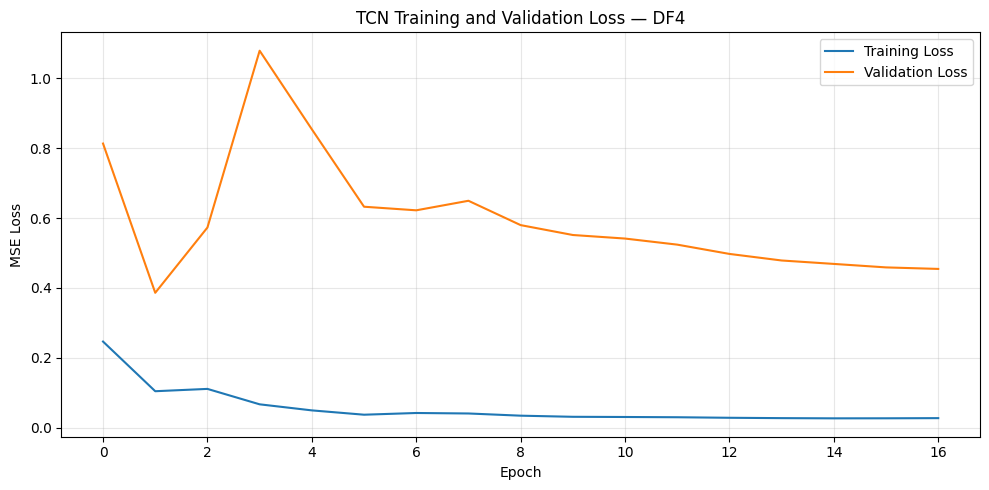

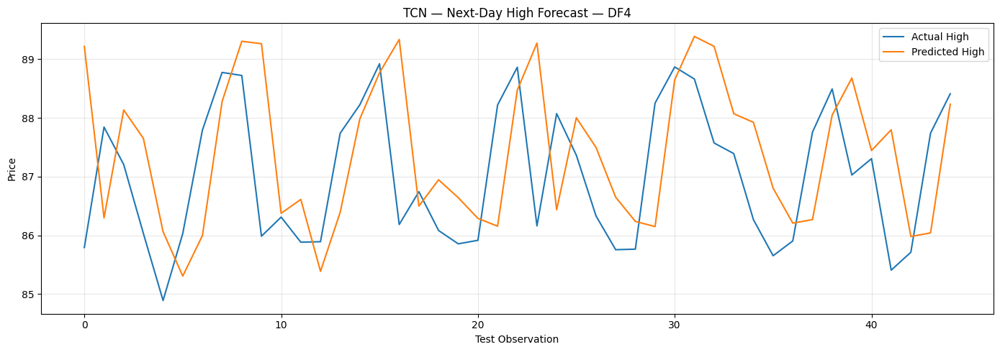

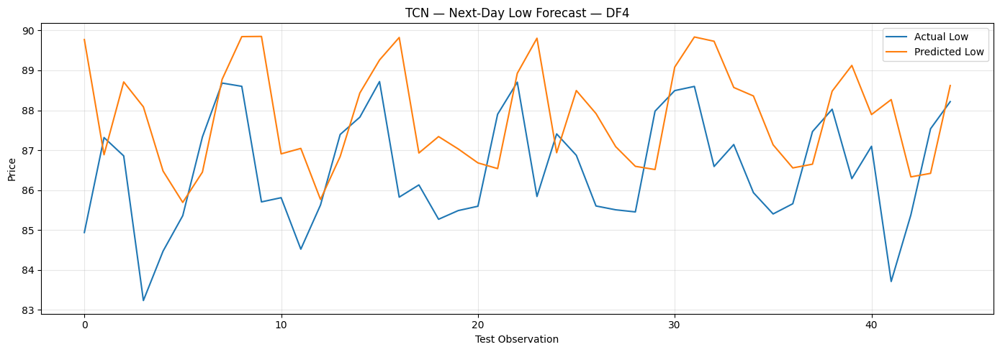



FINAL TCN RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,1.562886,2.342676,0.059807,3.315423,1.519571,2.300353,0.037586,3.236901,42
1,DF2,1.207778,1.615818,0.209326,1.729811,1.133740,1.573963,0.186041,1.634600,83
2,DF3,3.225455,4.302976,-1.502754,4.154432,3.231922,4.269186,-1.550765,4.183596,23
3,DF4,1.135561,1.444100,-0.541147,1.308448,1.624874,2.081286,-1.231634,1.893752,17



Results saved as: TCN_baseline_results.csv
Predictions saved as: TCN_baseline_predictions.xlsx


In [ ]:
# ============================================================
# TCN BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dropout,
    Dense,
    Add,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED TCN HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

TCN_FILTERS = 64
KERNEL_SIZE = 3
DILATIONS = [1, 2, 4, 8]

DROPOUT = 0.20
DENSE_UNITS = 16

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

EARLY_STOPPING_PATIENCE = 15
LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. DATA PREPARATION
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure numeric OHLC
for col in FEATURES:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {
    "DF1": ("2007-01-01", "2011-12-31"),
    "DF2": ("2012-01-01", "2019-12-31"),
    "DF3": ("2020-01-01", "2022-12-31"),
    "DF4": ("2023-01-01", None)
}


# ============================================================
# 7. TARGET CREATION
# ============================================================
#
# Predict:
#
#   Next-Day High / Current Close
#   Next-Day Low  / Current Close
#
# Absolute prediction is reconstructed later:
#
#   Predicted High = Predicted Ratio × Current Close
#   Predicted Low  = Predicted Ratio × Current Close
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1) /
    data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1) /
    data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. SEQUENCE CREATION FUNCTION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):
    """
    Creates sequences for the training partition.

    X[i-lookback:i] -> y[i]
    """

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):
    """
    Creates validation/test sequences while allowing
    the first observations to use historical information.

    This avoids losing the first LOOKBACK observations
    of validation/test.
    """

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[i:i + lookback]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. TCN RESIDUAL BLOCK
# ============================================================

def tcn_residual_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate
):

    residual = x

    # First causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Second causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation=None
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Match residual dimensions if necessary
    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    # Residual connection
    x = Add()(
        [
            x,
            residual
        ]
    )

    x = Activation(
        "relu"
    )(x)

    return x


# ============================================================
# 11. BUILD TCN MODEL
# ============================================================

def build_tcn_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    x = inputs

    # --------------------------------------------
    # Dilated TCN blocks
    # --------------------------------------------

    for dilation in DILATIONS:

        x = tcn_residual_block(
            x=x,
            filters=TCN_FILTERS,
            kernel_size=KERNEL_SIZE,
            dilation_rate=dilation,
            dropout_rate=DROPOUT
        )

    # --------------------------------------------
    # Sequence → fixed representation
    # --------------------------------------------

    x = GlobalAveragePooling1D()(x)

    # --------------------------------------------
    # Dense forecasting head
    # --------------------------------------------

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred) /
            denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []
all_predictions = {}
all_histories = {}
all_models = {}


# ============================================================
# 14. REGIME-WISE TRAINING
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 70)
    print(f"TRAINING TCN — {regime_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Filter regime
    # --------------------------------------------------------

    regime_data = data[
        data["Date"] >= pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )

    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )

    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # Extract features and targets
    # --------------------------------------------------------

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # --------------------------------------------------------
    # 70 / 15 / 15 chronological split
    # --------------------------------------------------------

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )

    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]

    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]

    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. SCALE TARGETS USING TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. CREATE TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = create_train_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK
    )


    # ========================================================
    # 18. CREATE VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = create_partition_sequences(
        history_X=X_train_scaled[-LOOKBACK:],
        partition_X=X_val_scaled,
        partition_y=y_val_scaled,
        lookback=LOOKBACK
    )


    # ========================================================
    # 19. CREATE TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = create_partition_sequences(
        history_X=X_val_scaled[-LOOKBACK:],
        partition_X=X_test_scaled,
        partition_y=y_test_scaled,
        lookback=LOOKBACK
    )


    print(
        "\nSequence shapes:"
    )

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_tcn_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(
        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,
        verbose=1
    )


    # ========================================================
    # 23. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TRANSFORM TARGET RATIOS
    # ========================================================

    y_pred_ratio = y_scaler.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = y_scaler.inverse_transform(
        y_test_seq
    )


    # ========================================================
    # 25. CURRENT CLOSE FOR EACH TEST TARGET
    # ========================================================
    #
    # Since validation/test sequences preserve the
    # partition ordering, the target-day current close
    # corresponds to X_test_raw / X_val_raw etc.
    #
    # Target is:
    #
    # High(t+1) / Close(t)
    #
    # Therefore use Close(t) to reconstruct.
    # ========================================================

    current_close_test = X_test_raw[
        :, FEATURES.index("Close")
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0] *
        current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1] *
        current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0] *
        current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1] *
        current_close_test
    )


    # ========================================================
    # 27. CALCULATE METRICS — HIGH
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = (
        calculate_metrics(
            actual_high,
            predicted_high
        )
    )


    # ========================================================
    # 28. CALCULATE METRICS — LOW
    # ========================================================

    low_mae, low_rmse, low_r2, low_mape = (
        calculate_metrics(
            actual_low,
            predicted_low
        )
    )


    # ========================================================
    # 29. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 70)
    print(f"TCN RESULTS — {regime_name}")
    print("=" * 70)

    print("\nNEXT-DAY HIGH")
    print(
        f"MAE  : {high_mae:.6f}"
    )
    print(
        f"RMSE : {high_rmse:.6f}"
    )
    print(
        f"R²   : {high_r2:.6f}"
    )
    print(
        f"MAPE : {high_mape:.6f}%"
    )

    print("\nNEXT-DAY LOW")
    print(
        f"MAE  : {low_mae:.6f}"
    )
    print(
        f"RMSE : {low_rmse:.6f}"
    )
    print(
        f"R²   : {low_r2:.6f}"
    )
    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Best_Epoch":
            len(history.history["loss"])

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Current_Close":
            current_close_test

    })

    all_predictions[
        regime_name
    ] = prediction_df

    all_histories[
        regime_name
    ] = history.history

    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. PLOT TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"TCN Training and Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. PLOT HIGH PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"TCN — Next-Day High Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. PLOT LOW PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"TCN — Next-Day Low Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 90)
print("FINAL TCN RESULTS")
print("=" * 90)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "TCN_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " TCN_baseline_results.csv"
)


# ============================================================
# 37. SAVE ALL PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "TCN_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in all_predictions.items():

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved as:"
    " TCN_baseline_predictions.xlsx"
)



ConvLSTM-STYLE TRAINING — DF1
Total observations: 504
Train: 352
Validation: 76
Test: 76

Sequence shapes:
X_train: (327, 25, 4)
X_val: (76, 25, 4)
X_test: (76, 25, 4)

Model architecture:


Model: "functional_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_42 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_52 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_32 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_120 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_53 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_33 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_76 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_121 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_77 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_122 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - loss: 0.0987 - mae: 0.2411 - val_loss: 0.2661 - val_mae: 0.5023 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0446 - mae: 0.1652 - val_loss: 0.2479 - val_mae: 0.4852 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0360 - mae: 0.1418 - val_loss: 0.2251 - val_mae: 0.4611 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0291 - mae: 0.1302 - val_loss: 0.1884 - val_mae: 0.4195 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0282 - mae: 0.1283 - val_loss: 0.1590 - val_mae: 0.3831 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0275 - mae: 0.1251 - val_loss: 0.1503 - val_mae: 0.3716 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0277 - mae: 0.1235 - val_loss: 0.1283 - val_mae: 0.3415 - learning_rate: 0.0010
Epoch 

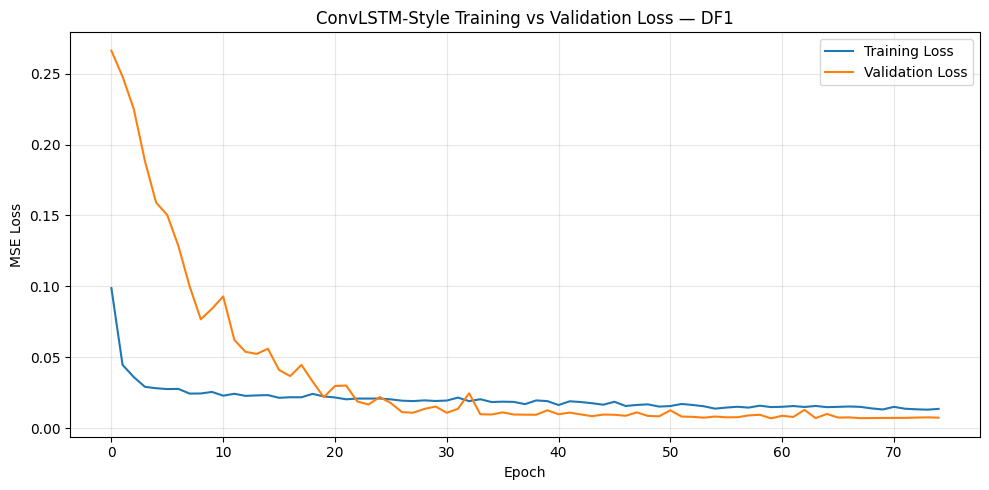

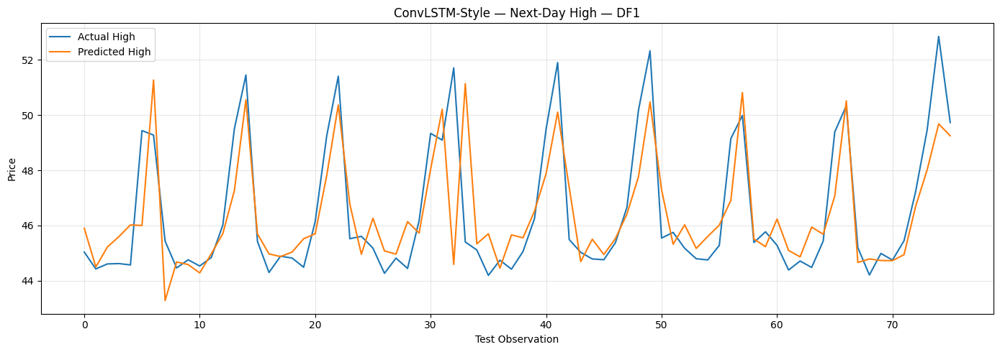

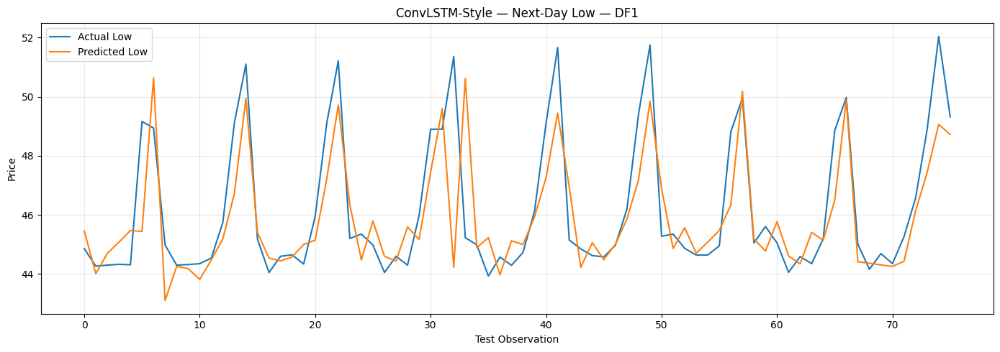



ConvLSTM-STYLE TRAINING — DF2
Total observations: 821
Train: 574
Validation: 123
Test: 124

Sequence shapes:
X_train: (549, 25, 4)
X_val: (123, 25, 4)
X_test: (124, 25, 4)

Model architecture:


Model: "functional_43"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_43 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_54 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_34 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_123 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_55 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_35 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_78 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_124 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_79 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_125 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - loss: 0.0544 - mae: 0.1787 - val_loss: 0.0612 - val_mae: 0.2296 - learning_rate: 0.0010
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0278 - mae: 0.1251 - val_loss: 0.0719 - val_mae: 0.2520 - learning_rate: 0.0010
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0237 - mae: 0.1148 - val_loss: 0.0773 - val_mae: 0.2618 - learning_rate: 0.0010
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0217 - mae: 0.1124 - val_loss: 0.0721 - val_mae: 0.2519 - learning_rate: 0.0010
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0197 - mae: 0.1081 - val_loss: 0.0609 - val_mae: 0.2287 - learning_rate: 0.0010
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0199 - mae: 0.1075 - val_loss: 0.0565 - val_mae: 0.2185 - learning_rate: 0.0010
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0192 - mae: 0.1057 - val_loss: 0.0545 - val_mae: 0.2140 - learning_rate: 0.0010
Epoch 

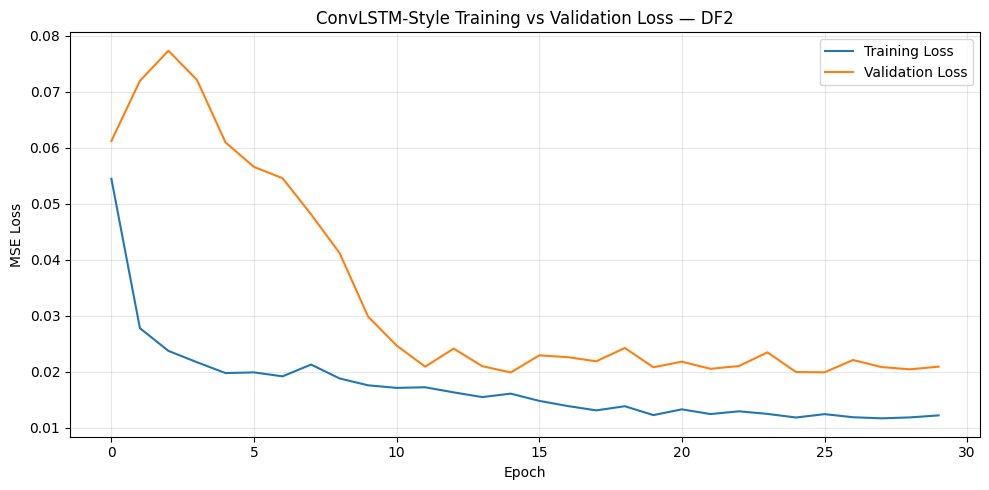

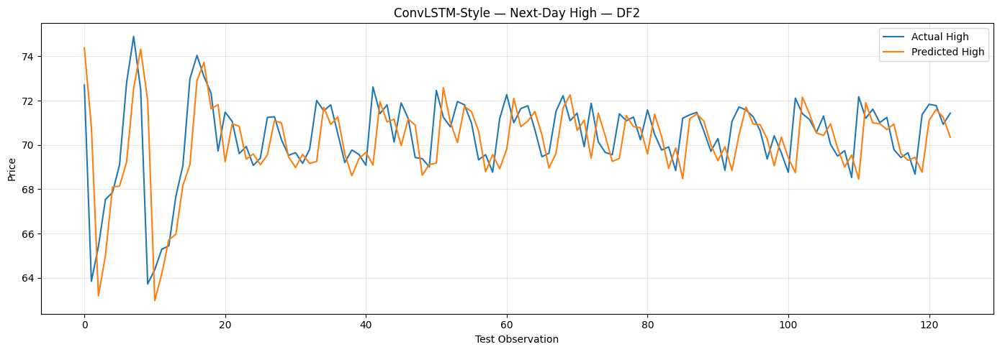

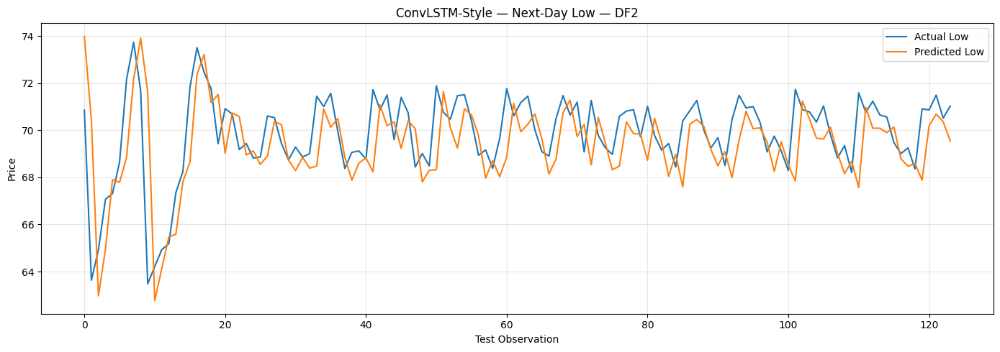



ConvLSTM-STYLE TRAINING — DF3
Total observations: 308
Train: 215
Validation: 46
Test: 47

Sequence shapes:
X_train: (190, 25, 4)
X_val: (46, 25, 4)
X_test: (47, 25, 4)

Model architecture:


Model: "functional_44"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_44 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_56 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_36 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_126 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_57 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_37 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_80 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_127 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_81 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_128 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 140ms/step - loss: 0.1054 - mae: 0.2669 - val_loss: 0.2023 - val_mae: 0.4372 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0327 - mae: 0.1429 - val_loss: 0.1905 - val_mae: 0.4241 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0319 - mae: 0.1423 - val_loss: 0.1967 - val_mae: 0.4309 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0280 - mae: 0.1352 - val_loss: 0.1962 - val_mae: 0.4310 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0282 - mae: 0.1358 - val_loss: 0.1905 - val_mae: 0.4249 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0256 - mae: 0.1272 - val_loss: 0.1882 - val_mae: 0.4220 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0245 - mae: 0.1246 - val_loss: 0.1876 - val_mae: 0.4209 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

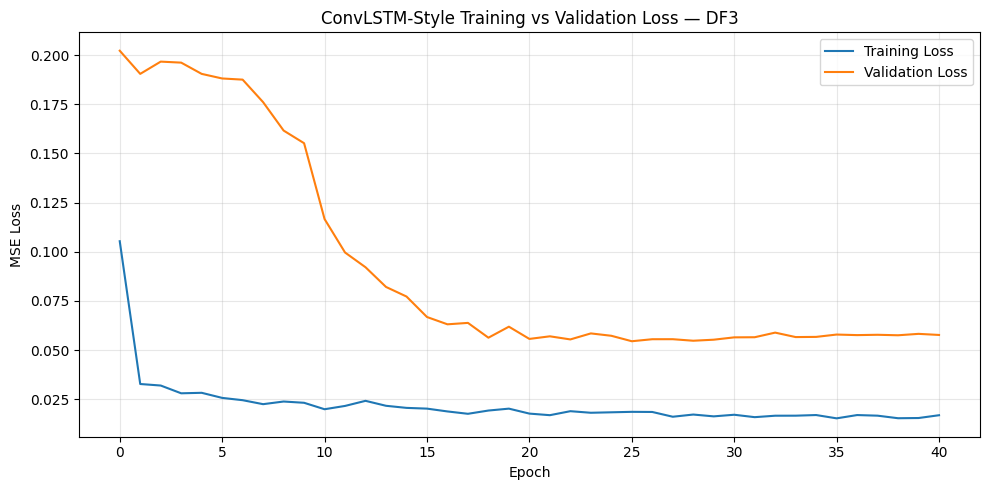

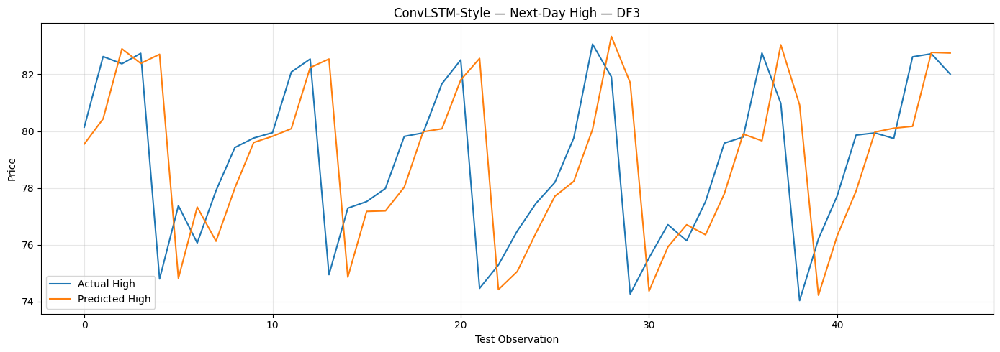

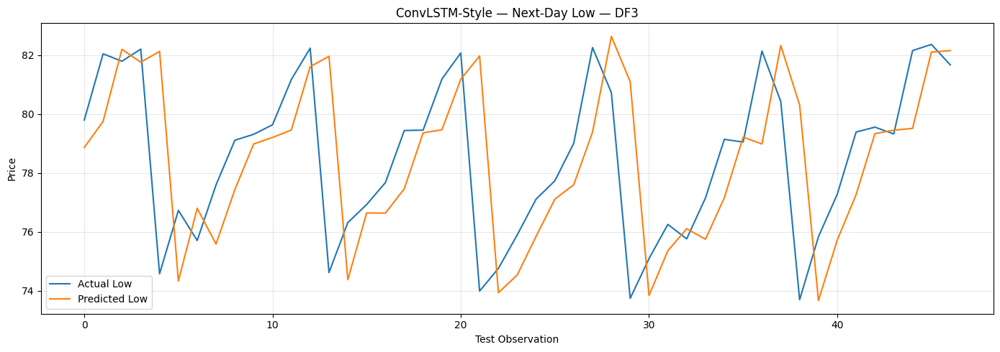



ConvLSTM-STYLE TRAINING — DF4
Total observations: 295
Train: 206
Validation: 44
Test: 45

Sequence shapes:
X_train: (181, 25, 4)
X_val: (44, 25, 4)
X_test: (45, 25, 4)

Model architecture:


Model: "functional_45"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_45 (InputLayer)     │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_58 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_38 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_129 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_59 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_39 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_82 (LSTM)                  │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_130 (Dropout)           │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_83 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_131 (Dropout)           │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_90 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_91 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step - loss: 0.2600 - mae: 0.4595 - val_loss: 0.4547 - val_mae: 0.5261 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0659 - mae: 0.1962 - val_loss: 0.3674 - val_mae: 0.4153 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0477 - mae: 0.1650 - val_loss: 0.3719 - val_mae: 0.4378 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0452 - mae: 0.1692 - val_loss: 0.3574 - val_mae: 0.4195 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0360 - mae: 0.1438 - val_loss: 0.3461 - val_mae: 0.3853 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0415 - mae: 0.1532 - val_loss: 0.3492 - val_mae: 0.3935 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0316 - mae: 0.1374 - val_loss: 0.3510 - val_mae: 0.4068 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

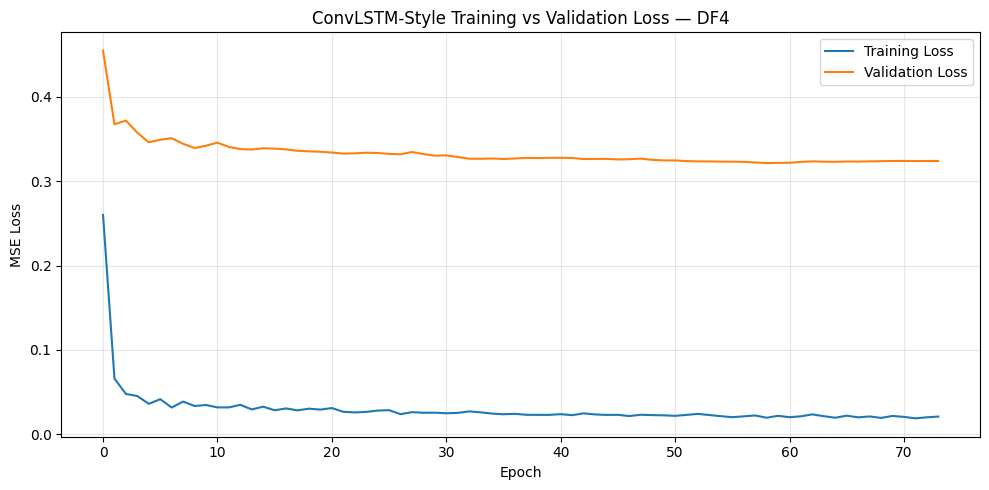

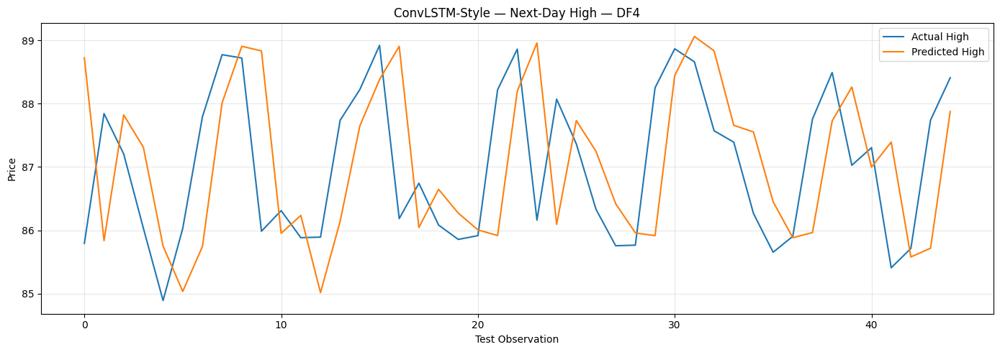

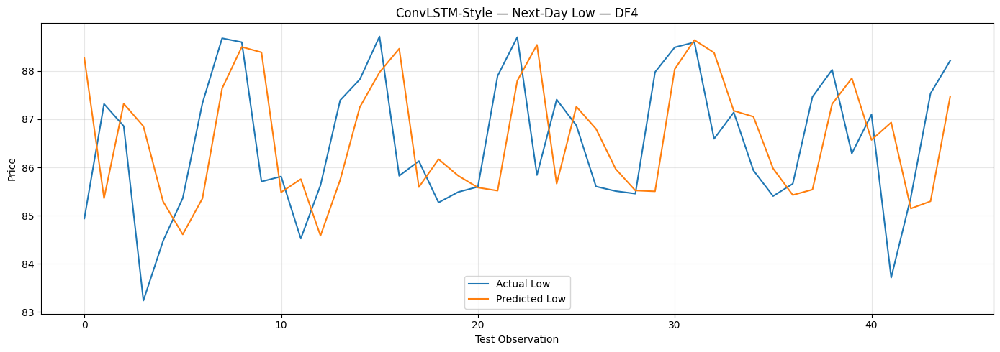



FINAL ConvLSTM-STYLE BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,1.049271,1.567621,0.579007,2.206221,1.004864,1.539968,0.568683,2.116442,75
1,DF2,1.168208,1.678605,0.146684,1.669307,1.186489,1.710405,0.038805,1.704663,30
2,DF3,1.880174,2.839682,-0.089982,2.431024,1.916296,2.798708,-0.096215,2.488533,41
3,DF4,1.083437,1.368239,-0.383483,1.245688,1.210906,1.555971,-0.247276,1.404659,74



Results saved: ConvLSTM_style_baseline_results.csv
Predictions saved: ConvLSTM_style_baseline_predictions.xlsx


In [58]:
# Research review: Tuning/regime variants can differ from final.1. Record exact years, validation metric, trial budget and whether validation targets or test data influenced final fitting. The independent baseline is not a rerun of this model.
# ============================================================
# ConvLSTM-STYLE 1D BASELINE
# NIFTY 50 REGIME-WISE FORECASTING
#
# Target:
#   Next-Day High
#   Next-Day Low
#
# Protocol:
#   70% Train
#   15% Validation
#   15% Test
#
# Input:
#   Previous 25 trading days
#   Open, High, Low, Close
#
# IMPORTANT:
#   Baseline experiment only.
#   NO hyperparameter tuning yet.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dropout,
    Dense,
    BatchNormalization,
    Activation,
    LayerNormalization
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 3. BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# Convolution
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Recurrent layers
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Regularization
DROPOUT = 0.20

# Dense
DENSE_UNITS = 16

# Optimizer
LEARNING_RATE = 0.001

# Training
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 4. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 5. VERIFY DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 6. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 7. MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2011-12-31"
    ),

    "DF2": (
        "2012-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2022-12-31"
    ),

    "DF4": (
        "2023-01-01",
        None
    )
}


# ============================================================
# 8. NORMALIZED NEXT-DAY TARGETS
# ============================================================

# High(t+1) / Close(t)
data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

# Low(t+1) / Close(t)
data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 9. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. VALIDATION / TEST SEQUENCES
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 11. CUSTOM CONVOLUTION-RECURRENT BLOCK
# ============================================================
#
# The idea is:
#
#   Convolution
#       ↓
#   Short-term feature extraction
#       ↓
#   LSTM
#       ↓
#   Temporal memory
#
# This gives the model convolutional processing before
# recurrent temporal modeling.
#
# ============================================================

def build_convlstm_style_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )


    # ========================================================
    # LOCAL TEMPORAL FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CONVOLUTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)


    # ========================================================
    # TEMPORAL RECURRENT MEMORY
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND RECURRENT LAYER
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 14. REGIME LOOP
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE TRAINING — {regime_name}"
    )
    print("=" * 80)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # X / Y
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # 70 / 15 / 15 CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: {len(X_train_raw)}"
    )

    print(
        f"Validation: {len(X_val_raw)}"
    )

    print(
        f"Test: {len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY INPUT SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. TRAIN-ONLY TARGET SCALING
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 18. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 19. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_convlstm_style_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )


    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 23. TEST PREDICTION
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 25. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 27. METRICS — HIGH
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 28. METRICS — LOW
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 29. RESULTS
    # ========================================================

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE RESULTS — {regime_name}"
    )
    print("=" * 80)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"ConvLSTM-Style Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. HIGH PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. LOW PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 100)
print("FINAL ConvLSTM-STYLE BASELINE RESULTS")
print("=" * 100)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "ConvLSTM_style_baseline_results.csv",
    index=False
)

print(
    "\nResults saved:"
    " ConvLSTM_style_baseline_results.csv"
)


# ============================================================
# 37. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "ConvLSTM_style_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved:"
    " ConvLSTM_style_baseline_predictions.xlsx"
)